# Flux: NEE of the LI-7500 years compared with FLUXNET and Etzold et al. (2011)

# About this notebook

The annual net ecosystem exchange of CO2 (`NEE`) of the open-path LI-7500 (`IRGA75`) years of this
product is less negative than in two earlier estimates for the same years: the FLUXNET release
ONEFlux v1.3 for CH-Lae, and Etzold et al. (2011, Ecosystems 14:1289-1309) for 2005-2009. This
notebook compares the three, splits the difference to FLUXNET by the kind of half-hour it comes
from, and recomputes the self-heating correction that Etzold et al. (2011) used, so that it can be
applied to the flux of this product in place of its own correction. It computes no product.

**Which run is shown.** The notebook reads the outputs of the `IRGA75` flux chain as they are on
disk, so a rerun of the chain refreshes every number below. The modification time of each input
file is printed under *Load data*; the numbers belong to the run of that date.

**Sign convention and units.** `NEE` is negative when the forest takes up CO2. Half-hourly values
and corrections are in µmol CO2 m⁻² s⁻¹; sums are in gC m⁻² (1 µmol m⁻² s⁻¹ over 30 minutes is
0.0216 gC m⁻²). A correction is stated as the amount it **adds** to the uncorrected flux, so a
positive correction reduces the uptake.

**Columns used**

- This product, `IRGA75` (`30_FLUX_POST-PROCESSING_CHAIN/IRGA75/05_FPPC_IRGA75_NEE_OPCO_2004-2017`):
  - `NEE_L3.1_L3.3_CUT_50_QCF_gfXG` — `NEE` after all quality tests, filtered at the median USTAR
    threshold (`CUT_50`) and gap-filled with XGBoost. The main series, called *ours* below
  - `FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED` — `0` measured, `1` gap-filled
  - `NEE_L3.1_L3.2_QCF` — `NEE` after the outlier tests and before the USTAR filter
  - `NIGHTTIME` — the night flag of this product, used for the `IRGA72` reference only
- The input of the chain (`.../IRGA75/01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019`):
  - `FC` — the CO2 flux of the LI-7500 **without** the self-heating correction
  - `BIAS_OPCO` — the bias modelled by opco; `FC_L1.1_OPCO = FC - BIAS_OPCO` is the corrected flux,
    so the opco correction adds `-BIAS_OPCO`
  - `SC_SINGLE` — storage flux from the single-point profile
  - `CO2_MOLAR_DENSITY` (mmol m⁻³), `WS`, `USTAR`, `T_SONIC` (°C), `VAPOR_DENSITY`, `AIR_DENSITY`
    (kg m⁻³) — the inputs of the correction of Burba et al. (2008)
- The LI-7200 (`IRGA72`, `.../IRGA72/05_FPPC_IRGA72_NEE_2016-2026.09`): the same main series and
  flag, as the reference not affected by self-heating, 2016-2025
- FLUXNET (`EUF_CH-Lae_FLUXNET_FLUXMET_HH_2004-2024_v1.3_r1`, `-9999` is missing):
  - `NEE_VUT_REF` — `NEE` with the variable USTAR threshold, reference scenario
  - `NEE_VUT_REF_QC` — `0` measured, above `0` gap-filled
  - `NIGHT` — `1` at night
  - the annual sums `NEE_VUT_REF` of the `YY` file, to check the sums computed here

**Day and night.** The comparisons with FLUXNET and with Etzold et al. (2011) split the records
by the FLUXNET flag `NIGHT`, so that both products are split the same way. The `NIGHTTIME` flag of
this product marks about 2 % more records as night, at dusk and dawn; it is used only for the
`IRGA72` years after 2024, which FLUXNET does not cover.

**Timestamps.** This product is stored on `TIMESTAMP_MIDDLE`, FLUXNET on `TIMESTAMP_START`; the
FLUXNET timestamps are moved forward by 15 minutes before the two are joined. Both are in CET
(UTC+01:00).

**2004 is incomplete.** FLUXNET starts on 14 March 2004 and the measurements of this product on
31 March 2004; the main series of this product is gap-filled from 1 January. Comparisons with
FLUXNET use only the half-hours FLUXNET covers.

# Main findings

The numbers behind each point are in the tables below.

- **Shared measured half-hours.** Where both products measured, they agree closely by day from
  February to September; from October to January the correction implied in FLUXNET adds more by
  day. At night this product is higher, because its correction adds more at night.
- **Gap-filled nights.** The largest part of the annual difference to FLUXNET in 2004-2015 comes
  from the nights that both products gap-fill. FLUXNET fills the winter nights far below this
  product, in line with its low measured winter nights. The winter nights of the LI-7200 years are
  well above both; this product fills its winter nights below its own measured ones.
- **2016 and 2017.** FLUXNET uses the LI-7200 in these years and differs from the LI-7200 sums of
  this product in the other direction. On the shared measured records the two agree; FLUXNET's
  higher USTAR thresholds in these years leave fewer measured nights, and it fills them higher.
- **Etzold et al. (2011).** The processing step that differs most is the self-heating correction.
  The correction of Burba et al. (2008), with the fraction of Järvi et al. (2009), is much smaller
  than opco by day in every month and over the year. Applied to the flux of this product in place of opco, it gives
  an annual sum and a seasonal pattern close to those that Etzold et al. (2011) report.
- **What the LI-7200 decides.** In winter the LI-7200 years agree with the opco-corrected flux,
  not with the smaller correction. In summer, in the run shown, they lie between the two. Whether
  opco is too large in the summers of the early years remains open.
- **Approximations.** Removing opco and adding the other correction uses the mean correction of
  each calendar month, by day and by night, applied to every half-hour, measured or gap-filled.
  The values of Etzold et al. (2011) per month are read from a figure.

</br>

# Settings

In [1]:
# This product. The flux chain's outputs are read as they are on disk, so a rerun of the chain
# refreshes every number in this notebook.
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow\30_FLUX_POST-PROCESSING_CHAIN")
FILE_NEE75 = r"IRGA75\05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet"
FILE_INPUT75 = r"IRGA75\01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet"
FILE_NEE72 = r"IRGA72\05_FPPC_IRGA72_NEE_2016-2026.09.parquet"

varname = 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG'  # the main series
flagname = 'FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED'  # 0 measured, 1 gap-filled
varname_l32 = 'NEE_L3.1_L3.2_QCF'  # after the outlier tests, before the USTAR filter
NIGHTTIME = 'NIGHTTIME'
# FC is the uncorrected LI-7500 flux; FC_L1.1_OPCO = FC - BIAS_OPCO is the corrected one.
INPUT_COLS = ['FC', 'FC_L1.1_OPCO', 'BIAS_OPCO', 'SC_SINGLE', 'CO2_MOLAR_DENSITY', 'WS', 'USTAR',
              'T_SONIC', 'VAPOR_DENSITY', 'AIR_DENSITY']

# FLUXNET ONEFlux v1.3 for CH-Lae. Missing values are -9999; timestamps are TIMESTAMP_START.
FLUXNET_DIR = r"F:\Sync\luhk_work\sites\LAE\Data\Datasets\EUF_CH-Lae_FLUXNET_2004-2024_v1.3_r1"
FLUXNET_HH = "EUF_CH-Lae_FLUXNET_FLUXMET_HH_2004-2024_v1.3_r1.csv"
FLUXNET_YY = "EUF_CH-Lae_FLUXNET_FLUXMET_YY_2004-2024_v1.3_r1.csv"
FLX_NEE, FLX_QC, FLX_NIGHT = 'NEE_VUT_REF', 'NEE_VUT_REF_QC', 'NIGHT'
FLX_MISSING = -9999

# Periods.
FIRST_YEAR, LAST_YEAR = 2004, 2017  # the LI-7500 record of this product
LI7500_ONLY = (2004, 2015)  # the LI-7500 is the only analyser
PARALLEL_YEARS = (2016, 2017)  # both analysers; FLUXNET uses the LI-7200
IRGA72_YEARS = (2016, 2025)  # full LI-7200 years of this product, the reference
ETZOLD_YEARS = (2005, 2009)  # the years of Etzold et al. 2011

# Published values of Etzold et al. 2011 (Ecosystems 14:1289-1309), declared here because they
# are not in any data file.
ETZOLD_MEAN = -415  # mean annual NEE 2005-2009, gC m-2 y-1; p. 1301 and Table 4
# Most and least negative year, gC m-2 y-1; p. 1301. As published; it cannot be reconciled with
# the published mean (five years at or below -366 with one at -662 average at most -425), and
# Fig. 3 shows -330 for 2006. Both published means agree with Fig. 3.
ETZOLD_RANGE = (-662, -366)
# Mean monthly NEE 2005-2009 in gC m-2 from Fig. 5 of Etzold et al. 2011, read with both axes
# calibrated on the tick marks, accurate to about +-3 gC m-2; the twelve months sum to -418.
# December to February carry no month number in the figure and are assigned from the connecting
# line and the air temperature; they are the least certain.
ETZOLD_FIG5 = {1: 39, 2: 33, 3: 17, 4: -5, 5: -111, 6: -157, 7: -138, 8: -106, 9: -62, 10: 5.5,
               11: 42, 12: 25}
ETZOLD_FIG5_ACCURACY = 3
ETZOLD_FIG5_WINTER_RANGE = (20, 45)  # range of the unlabelled winter points in Fig. 5
ETZOLD_FIG5_LEAST_CERTAIN = [12, 1, 2]
# Processing of Etzold et al. 2011, p. 1297.
ETZOLD_METHODS = {
    'density correction': "WPL",
    'self-heating correction': "Burba et al. (2008), with the surface temperatures and fraction "
                               "of Järvi et al. (2009)",
    'large winter fluxes (±15 µmol m-2 s-1)': "kept in the data, excluded from the gap-filling fits",
    'negative nighttime values': "removed, together with as many positive ones (trimmed)",
    'gap-filling': "light response by day, Lloyd-Taylor at night, running mean below 0 °C",
    'USTAR threshold (m s-1)': "0.3",
    'measured nights (%)': "24",
}
# This product, from docs/L1.1.md, docs/L3.2.md, docs/L3.3.md and docs/L4.1.md.
USTAR_CUT_50 = 0.304  # m s-1, the CUT_50 threshold of both analysers; docs/L3.3.md
PRODUCT_METHODS = {
    'density correction': "WPL, in EddyPro (Level 1)",
    'self-heating correction': "opco: heating and WPL thermal terms with coefficients fitted to "
                               "the LI-7200 in 2016-2017 (Level 1.1)",
    'large winter fluxes (±15 µmol m-2 s-1)': "absolute limits ±50 µmol m-2 s-1 and outlier tests "
                                              "(Level 3.2)",
    'negative nighttime values': "removed where clearly below zero: single records and whole "
                                 "nights (Level 3.2)",
    'gap-filling': "XGBoost (Level 4.1)",
    'USTAR threshold (m s-1)': f"{USTAR_CUT_50} (CUT_50, constant)",
}

# The correction of Burba et al. 2008 with the fraction of Jarvi et al. 2009, as in an R
# implementation used in the group.
BURBA_FRACTION = 0.085
M_AIR, M_H2O = 0.028965, 0.018  # kg mol-1

# Seasons of the comparison with Etzold et al. 2011.
SEASONS = {'Nov-Mar': [11, 12, 1, 2, 3], 'Apr+Oct': [4, 10], 'May-Sep': [5, 6, 7, 8, 9]}
USTAR_BINS = [0, 0.1, 0.2, 0.3, 0.4, 0.6, 5]  # m s-1, for the nights by USTAR

units = "µmol m-2 s-1"
units_sum = "gC m-2"
UMOL_TO_GC = 12.011 * 1e-6 * 1800  # umol CO2 m-2 s-1 over one half-hour -> gC m-2
CLASSES = {'A': 'both measured', 'B': 'ours measured only', 'C': 'FLUXNET measured only',
           'D': 'both filled'}
COLORS = {'ours': '#1E88E5', 'FLUXNET': '#FB8C00', 'IRGA72': '#43A047', 'study2011': '#212121',
          'burba': '#8E24AA', 'noopco': '#90A4AE'}

# Imports

In [2]:
import calendar
import importlib.metadata
import textwrap
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
version_diive = importlib.metadata.version("diive")
print(f"diive version: v{version_diive}")

diive version: v0.93.0


# Helpers

In [3]:
def tabcap(text, width=100):
    """Print a table caption. Called by `styled`, so no table can be shown without one."""
    print(textwrap.fill(f"Table — {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure — {text}", width), fontsize=9, ha='left', x=0.005)


def styled(data, caption, fmt="{:.0f}", subset=None, cmap="RdBu_r", axis=None, center=True):
    """`data` as a table with a caption, fixed decimals and a colour scale over its values.

    The caption is printed above the table. `center` puts the midpoint of the colour scale at
    zero; `axis=None` scales the colours across the whole table (or `subset`). The colour scale
    sets a text colour per cell, so the numbers stay readable in light and dark pages.
    """
    numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c])]
    fmt = {c: fmt for c in numeric} if isinstance(fmt, str) else {
        c: f for c, f in fmt.items() if c in numeric}
    tabcap(caption)
    styler = data.style.format(fmt, na_rep="-")
    if cmap is None:
        return styler
    limits = {}
    if center:
        if isinstance(subset, tuple):
            values = data.loc[subset]
        else:
            values = data[subset] if subset is not None else data[numeric]
        absmax = np.nanmax(np.abs(values.to_numpy(dtype=float)))
        limits = dict(vmin=-absmax, vmax=absmax)
    return styler.background_gradient(cmap=cmap, subset=subset, axis=axis,
                                      text_color_threshold=0.4, **limits)


def to_gc(s):
    """Half-hourly NEE in umol m-2 s-1 summed to gC m-2 over whatever period `s` covers."""
    return s.sum() * UMOL_TO_GC


def per_year(s, how=to_gc):
    """One value per calendar year, indexed by the year number."""
    out = s.groupby(s.index.year).agg(how)
    out.index.name = 'YEAR'
    return out


def flat(columns):
    """Join a two-level column index of (name, is_night) to 'name, day' / 'name, night'."""
    return [f"{a}, {'night' if b else 'day'}" for a, b in columns]


def mean_monthly_sums(s):
    """Mean sum of each calendar month over the years `s` covers, in gC m-2."""
    years = s.index.year.nunique()
    out = s.groupby(s.index.month).sum() * UMOL_TO_GC / years
    out.index.name = 'MONTH'
    return out


def season_sums(monthly):
    """Sums of a table of monthly values (rows 1-12) over the seasons in SEASONS, and the year."""
    out = pd.DataFrame({k: monthly.loc[v].sum(min_count=len(v)) for k, v in SEASONS.items()})
    out['year'] = monthly.sum(min_count=12)
    return out


def month_night_climatology(frame, column, how='mean'):
    """The mean (or median) of `column` per calendar month and day/night, at every record.

    Used to remove or add a correction on every half-hour, measured or gap-filled: a gap-filled
    value is learned from corrected measured values, so it carries the correction as well.
    """
    table = frame.groupby([frame.index.month, 'night'])[column].agg(how)
    keys = pd.MultiIndex.from_arrays([frame.index.month, frame['night']])
    return pd.Series(table.reindex(keys).to_numpy(), index=frame.index)


def burba_correction(qc, u, ustar, ta, rho_v, rho_a, fraction=BURBA_FRACTION):
    """Self-heating correction of Burba et al. (2008) with the fraction of Jarvi et al. (2009).

    The equation as in an R implementation used in the group. Returns the amount added to the
    uncorrected flux, in umol m-2 s-1.
      qc     CO2 molar density, mmol m-3
      u      wind speed, m s-1
      ustar  friction velocity, m s-1
      ta     air temperature, here the sonic temperature, degC
      rho_v  water vapour density, kg m-3
      rho_a  air density, kg m-3
    """
    qc = qc * 1000  # mmol m-3 -> umol m-3
    ts = 0.0025 * ta ** 2 + 0.90 * ta + 2.07  # surface temperature of the instrument, degC
    ra = u / ustar ** 2  # aerodynamic resistance, s m-1
    rho_d = rho_a + rho_v * (M_AIR / M_H2O - 1)  # as in the R implementation
    return fraction * (ts - ta) * qc / (ra * (ta + 273.15)) * (1 + 1.6077 * rho_v / rho_d)


def month_axis(ax):
    """Month names on an axis of calendar months 1-12."""
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([calendar.month_abbr[m] for m in range(1, 13)])
    return ax

</br>

# Load data

In [4]:
_files = {'this product, IRGA75 NEE (05)': Path(DATADIR) / FILE_NEE75,
          'this product, IRGA75 input (01)': Path(DATADIR) / FILE_INPUT75,
          'this product, IRGA72 NEE (05)': Path(DATADIR) / FILE_NEE72,
          'FLUXNET, half-hourly': Path(FLUXNET_DIR) / FLUXNET_HH,
          'FLUXNET, yearly': Path(FLUXNET_DIR) / FLUXNET_YY}

nee75 = pd.read_parquet(_files['this product, IRGA75 NEE (05)'],
                        columns=[varname, flagname, varname_l32, NIGHTTIME])
inp75 = pd.read_parquet(_files['this product, IRGA75 input (01)'], columns=INPUT_COLS)
nee72 = pd.read_parquet(_files['this product, IRGA72 NEE (05)'], columns=[varname, flagname, NIGHTTIME])

hh = pd.read_csv(_files['FLUXNET, half-hourly'], usecols=['TIMESTAMP_START', FLX_NEE, FLX_QC, FLX_NIGHT],
                 na_values=FLX_MISSING).replace(FLX_MISSING, np.nan)
# TIMESTAMP_START -> TIMESTAMP_MIDDLE, the convention of this product.
hh.index = (pd.to_datetime(hh.pop('TIMESTAMP_START').astype(str), format='%Y%m%d%H%M')
            + pd.Timedelta('15min'))
yy = (pd.read_csv(_files['FLUXNET, yearly'], usecols=['TIMESTAMP', FLX_NEE], na_values=FLX_MISSING)
      .replace(FLX_MISSING, np.nan).set_index('TIMESTAMP')[FLX_NEE])
for _df in (nee75, inp75, nee72, hh):
    _df.index = pd.DatetimeIndex(_df.index).as_unit('ns')
    _df.index.name = 'TIMESTAMP_MIDDLE'

## 📋 Table: input files and the run they come from

In [5]:
_inputs = pd.DataFrame({
    'file': [p.name for p in _files.values()],
    'modified': [f"{datetime.fromtimestamp(p.stat().st_mtime):%Y-%m-%d %H:%M}" for p in _files.values()],
}, index=list(_files))
_inputs['records'] = [len(nee75), len(inp75), len(nee72), len(hh), len(yy)]
display(styled(_inputs, caption="the input files with their modification time. The numbers in this "
                                "notebook belong to the runs of these dates",
               fmt="{:,.0f}", cmap=None))

Table — the input files with their modification time. The numbers in this notebook belong to the
runs of these dates



,file,modified,records
"this product, IRGA75 NEE (05)",05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet,2026-10-30 19:27,"245,472"
"this product, IRGA75 input (01)",01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet,2026-10-30 00:49,"280,512"
"this product, IRGA72 NEE (05)",05_FPPC_IRGA72_NEE_2016-2026.09.parquet,2026-10-30 19:02,"188,448"
"FLUXNET, half-hourly",EUF_CH-Lae_FLUXNET_FLUXMET_HH_2004-2024_v1.3_r1.csv,2025-12-23 06:52,"368,208"
"FLUXNET, yearly",EUF_CH-Lae_FLUXNET_FLUXMET_YY_2004-2024_v1.3_r1.csv,2025-12-23 06:52,21


In [6]:
# One frame of the LI-7500 years: this product, its input and FLUXNET on the same half-hours.
d = pd.DataFrame({
    'ours': nee75[varname],
    'ours_meas': nee75[flagname].eq(0),
    'ours_l32': nee75[varname_l32],
    'nighttime_ours': nee75[NIGHTTIME].eq(1),
}).join(inp75).join(hh)
d = d.loc[str(FIRST_YEAR):str(LAST_YEAR)].copy()
d['flx'] = d[FLX_NEE]
d['has_flx'] = d['flx'].notna()
d['flx_meas'] = d[FLX_QC].eq(0) & d['has_flx']
d['night'] = d[FLX_NIGHT].eq(1)
d['diff'] = d['ours'] - d['flx']  # ours minus FLUXNET
d['opco'] = -d['BIAS_OPCO']  # what opco adds to FC
# What FLUXNET adds to the uncorrected flux, on records FLUXNET measured: its NEE minus the NEE of
# this product before its correction (FC + SC_SINGLE).
d['flx_implied'] = d['flx'] - (d['FC'] + d['SC_SINGLE'])
d['burba'] = burba_correction(d['CO2_MOLAR_DENSITY'], d['WS'], d['USTAR'], d['T_SONIC'],
                              d['VAPOR_DENSITY'], d['AIR_DENSITY'])
d.loc[d['FC'].isna(), 'burba'] = np.nan
d['cls'] = np.select([d.ours_meas & d.flx_meas, d.ours_meas & ~d.flx_meas, ~d.ours_meas & d.flx_meas],
                     ['A', 'B', 'C'], 'D')

# The FLUXNET comparison uses only the half-hours FLUXNET covers.
c = d[d['has_flx']].copy()
# The LI-7200 reference, full years.
r72 = nee72.loc[str(IRGA72_YEARS[0]):str(IRGA72_YEARS[1])].copy()
r72['meas'] = r72[flagname].eq(0)
r72['night'] = r72[NIGHTTIME].eq(1)
print(f"LI-7500 frame: {d.index[0]} -> {d.index[-1]} ({len(d):,} records, "
      f"{len(c):,} with FLUXNET)")
print(f"LI-7200 frame: {r72.index[0]} -> {r72.index[-1]} ({len(r72):,} records)")

LI-7500 frame: 2004-01-01 00:15:00 -> 2017-12-31 23:45:00 (245,472 records, 241,944 with FLUXNET)
LI-7200 frame: 2016-01-01 00:15:00 -> 2025-12-31 23:45:00 (175,344 records)


## Integrity checks

In [7]:
# Everything below assumes complete 30MIN records without duplicates, a complete main series, the
# documented relation between the corrected and the uncorrected flux, and the FLUXNET flags as
# documented.
_issues = []
for _name, _df in (('IRGA75 05', nee75), ('IRGA75 01', inp75), ('IRGA72 05', nee72), ('FLUXNET', hh)):
    if _df.index.duplicated().any():
        _issues.append(f"{_name}: duplicate timestamps")
    if not (_df.index.to_series().diff().dropna() == pd.Timedelta('30min')).all():
        _issues.append(f"{_name}: index gaps")
_expected = pd.date_range(f"{FIRST_YEAR}-01-01 00:15", f"{LAST_YEAR}-12-31 23:45", freq='30min')
if not d.index.equals(_expected):
    _issues.append("the LI-7500 frame does not cover every half-hour of the period")
if d['ours'].isna().any():
    _issues.append(f"main series: {int(d['ours'].isna().sum())} missing values")
if r72[varname].isna().any():
    _issues.append(f"IRGA72 main series: {int(r72[varname].isna().sum())} missing values")
if set(nee75[flagname].dropna().unique()) - {0, 1}:
    _issues.append("unknown fill flags in IRGA75")
_both = d[['FC', 'BIAS_OPCO', 'FC_L1.1_OPCO']].dropna()
_dev = (_both['FC_L1.1_OPCO'] - (_both['FC'] - _both['BIAS_OPCO'])).abs().max()
if _dev > 1e-6:
    _issues.append(f"FC_L1.1_OPCO is not FC - BIAS_OPCO (max deviation {_dev:.3g})")
if set(c[FLX_QC].dropna().unique()) - {0, 1, 2, 3}:
    _issues.append(f"unknown FLUXNET QC values: {sorted(c[FLX_QC].dropna().unique())}")
if set(c[FLX_NIGHT].dropna().unique()) - {0, 1}:
    _issues.append("unknown FLUXNET night flags")
if (c['flx'] == FLX_MISSING).any():
    _issues.append("FLUXNET missing values not converted")
_first_flx = d['flx'].first_valid_index()
if d.loc[_first_flx:, 'flx'].isna().any():
    _issues.append("FLUXNET has gaps after its first record")

print(f"FLUXNET covers this period from {_first_flx} (TIMESTAMP_MIDDLE)")
print(f"first measured record of this product: {d.index[d['ours_meas']][0]}")
print(f"night flags: FLUXNET NIGHT and NIGHTTIME of this product agree on "
      f"{(c['night'] == c['nighttime_ours']).mean() * 100:.1f} % of the records; "
      f"{int((c['night'] & ~c['nighttime_ours']).sum())} FLUXNET nights are day in this product, "
      f"{int((~c['night'] & c['nighttime_ours']).sum())} the other way round")
assert not _issues, "the inputs are not what this notebook assumes: " + "; ".join(_issues)
print("Integrity checks passed.")

FLUXNET covers this period from 2004-03-14 12:15:00 (TIMESTAMP_MIDDLE)
first measured record of this product: 2004-03-31 11:45:00
night flags: FLUXNET NIGHT and NIGHTTIME of this product agree on 97.6 % of the records; 0 FLUXNET nights are day in this product, 5831 the other way round
Integrity checks passed.


</br>

# Annual sums

The annual `NEE` of this product, of FLUXNET and of the LI-7200 of this product. FLUXNET is summed
here from the half-hourly file and checked against its yearly file.

## 📋 Table: annual sums of the LI-7500 years

In [8]:
_yc = c.index.year
annual = pd.DataFrame({
    'ours, whole year': per_year(d['ours']),
    'ours, FLUXNET records': per_year(c['ours']),
    'FLUXNET (HH)': per_year(c['flx']),
    'FLUXNET (YY)': yy.reindex(range(FIRST_YEAR, LAST_YEAR + 1)),
    'ours minus FLUXNET': per_year(c['diff']),
    'IRGA72 (ours)': per_year(r72[varname]).reindex(range(FIRST_YEAR, LAST_YEAR + 1)),
    'ours measured (%)': c['ours_meas'].groupby(_yc).mean() * 100,
    'FLUXNET measured (%)': c['flx_meas'].groupby(_yc).mean() * 100,
    'FLUXNET records (%)': d['has_flx'].groupby(d.index.year).mean() * 100,
})
annual.index.name = 'YEAR'
_check = (annual['FLUXNET (HH)'] - annual['FLUXNET (YY)']).abs().dropna()
assert (_check < 1).all(), f"FLUXNET HH sums differ from its YY file: {_check.round(1).to_dict()}"
_fmt = {col: "{:.0f}" for col in annual.columns}
_fmt.update({col: "{:.1f}" for col in annual.columns if '%' in col})
display(styled(annual, caption=f"annual NEE in {units_sum}. 'ours, FLUXNET records' and the difference use "
                               f"only the half-hours FLUXNET covers, which matters for 2004 only. The "
                               f"FLUXNET sums from the half-hourly file agree with its yearly file "
                               f"within {_check.max():.2f} {units_sum}; the yearly file has no sum for "
                               f"the incomplete 2004. IRGA72: the LI-7200 of this product in the "
                               f"parallel years",
               fmt=_fmt, subset=['ours minus FLUXNET'], cmap='RdBu_r', center=True))

Table — annual NEE in gC m-2. 'ours, FLUXNET records' and the difference use only the half-hours
FLUXNET covers, which matters for 2004 only. The FLUXNET sums from the half-hourly file agree with
its yearly file within 0.02 gC m-2; the yearly file has no sum for the incomplete 2004. IRGA72: the
LI-7200 of this product in the parallel years



,"ours, whole year","ours, FLUXNET records",FLUXNET (HH),FLUXNET (YY),ours minus FLUXNET,IRGA72 (ours),ours measured (%),FLUXNET measured (%),FLUXNET records (%)
YEAR,,,,,,,,,
2004,40,-158,-444,-,286,-,38.6,33.6,79.9
2005,62,62,-158,-158,221,-,36.6,33.3,100.0
2006,43,43,-124,-124,167,-,38.5,29.5,100.0
2007,-180,-180,-352,-352,172,-,41.7,34.1,100.0
2008,-57,-57,-201,-201,144,-,41.7,35.1,100.0
2009,-57,-57,-270,-270,213,-,38.8,34.0,100.0
2010,-168,-168,-441,-441,273,-,36.4,35.5,100.0
2011,-312,-312,-517,-517,204,-,39.5,36.6,100.0
2012,-338,-338,-680,-680,342,-,34.0,30.7,100.0


In the run shown, the difference to FLUXNET is positive in every year in which both use the
LI-7500, 2004-2015: this product shows less uptake. In 2016 and 2017 FLUXNET uses the LI-7200, and the sign reverses.

## 📋 Table: the LI-7200 years, for reference

In [9]:
_y72 = range(IRGA72_YEARS[0], IRGA72_YEARS[1] + 1)
annual72 = pd.DataFrame({
    'IRGA72 (ours)': per_year(r72[varname]),
    'IRGA72 measured (%)': r72['meas'].groupby(r72.index.year).mean() * 100,
    'FLUXNET (YY)': yy.reindex(_y72),
}, index=_y72)
annual72.index.name = 'YEAR'
annual72.loc['mean'] = annual72.mean()
display(styled(annual72, caption=f"annual NEE of the LI-7200 years of this product in {units_sum}, with the "
                                 f"FLUXNET sums of the same years where they exist. The LI-7200 is not "
                                 f"affected by self-heating and is the reference for plausibility",
               fmt={'IRGA72 (ours)': "{:.0f}", 'IRGA72 measured (%)': "{:.1f}",
                    'FLUXNET (YY)': "{:.0f}"}, subset=['IRGA72 (ours)', 'FLUXNET (YY)'],
               cmap='RdBu_r', center=True))

Table — annual NEE of the LI-7200 years of this product in gC m-2, with the FLUXNET sums of the same
years where they exist. The LI-7200 is not affected by self-heating and is the reference for
plausibility



,IRGA72 (ours),IRGA72 measured (%),FLUXNET (YY)
YEAR,,,
2016,-159,35.3,-81
2017,71,48.8,288
2018,-110,45.6,-52
2019,-292,39.4,-95
2020,-267,46.4,-320
2021,-22,45.3,40
2022,-16,46.8,-11
2023,13,50.8,352
2024,-43,48.8,105


## 📊 Plot: annual sums

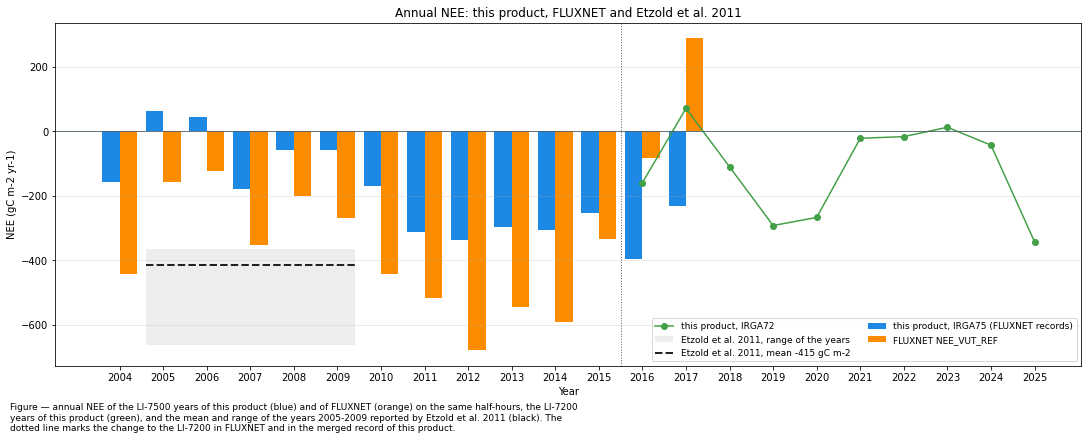

In [10]:
fig, ax = plt.subplots(figsize=(15, 6), dpi=72, layout="constrained")
_x = annual.index.to_numpy()
ax.bar(_x - 0.2, annual['ours, FLUXNET records'], width=0.4, color=COLORS['ours'],
       label="this product, IRGA75 (FLUXNET records)")
ax.bar(_x + 0.2, annual['FLUXNET (HH)'], width=0.4, color=COLORS['FLUXNET'],
       label="FLUXNET NEE_VUT_REF")
_a72 = annual72.drop('mean')['IRGA72 (ours)']
ax.plot(_a72.index, _a72, color=COLORS['IRGA72'], marker='o', lw=1.5, label="this product, IRGA72")
ax.fill_between([ETZOLD_YEARS[0] - 0.4, ETZOLD_YEARS[1] + 0.4], *ETZOLD_RANGE, color=COLORS['study2011'],
                alpha=0.08, lw=0, label="Etzold et al. 2011, range of the years")
ax.hlines(ETZOLD_MEAN, ETZOLD_YEARS[0] - 0.4, ETZOLD_YEARS[1] + 0.4, color=COLORS['study2011'], lw=2,
          ls='--', label=f"Etzold et al. 2011, mean {ETZOLD_MEAN} {units_sum}")
ax.axhline(0, color='#455A64', lw=0.8)
ax.axvline(2015.5, color='#616161', lw=1, ls=':')
ax.set_xticks(range(FIRST_YEAR, IRGA72_YEARS[1] + 1))
ax.set_xlabel("Year")
ax.set_ylabel(f"NEE ({units_sum} yr-1)")
ax.set_title("Annual NEE: this product, FLUXNET and Etzold et al. 2011")
ax.grid(alpha=0.3, axis='y')
ax.legend(fontsize=9, ncol=2, loc='lower right')
figcap(fig, "annual NEE of the LI-7500 years of this product (blue) and of FLUXNET (orange) on the "
            "same half-hours, the LI-7200 years of this product (green), and the mean and range "
            "of the years 2005-2009 reported by Etzold et al. 2011 (black). The dotted line marks "
            "the change to the LI-7200 in FLUXNET and in the merged record of this product.")
fig.show()

</br>

# Comparison with FLUXNET

The FLUXNET release for CH-Lae was built from the earlier product FP2021: for 2004-2015 from the
LI-7500 flux corrected for self-heating, for 2016-2017 from the LI-7200 flux. FLUXNET then applied
its own USTAR filter and gap-filling (MDS). Here the two records are compared half-hour by
half-hour, on the half-hours FLUXNET covers.

Each half-hour falls in one of four classes:

- **A** both measured
- **B** measured in this product only (FLUXNET filled it)
- **C** measured in FLUXNET only (this product filled it)
- **D** both filled

The annual difference is the sum of the differences in the four classes, by day and by night.

## Record classes

### 📋 Table: annual difference by record class, day and night

In [11]:
_g = c.groupby([_yc, 'cls', 'night'])['diff'].sum().unstack(['cls', 'night']) * UMOL_TO_GC
_g = _g.reindex(columns=pd.MultiIndex.from_product([list(CLASSES), [False, True]]))
_g.columns = flat(_g.columns)
_g['total'] = _g.sum(axis=1)
_g.index.name = 'YEAR'
by_class = _g
display(styled(by_class, caption=f"ours minus FLUXNET per year in {units_sum}, split by record class "
                                 f"(A both measured, B ours measured only, C FLUXNET measured only, D both "
                                 f"filled) and by day and night (FLUXNET NIGHT). The columns add up to "
                                 f"'total', the difference of the annual sums",
               subset=[col for col in by_class.columns if col != 'total']))

Table — ours minus FLUXNET per year in gC m-2, split by record class (A both measured, B ours
measured only, C FLUXNET measured only, D both filled) and by day and night (FLUXNET NIGHT). The
columns add up to 'total', the difference of the annual sums



,"A, day","A, night","B, day","B, night","C, day","C, night","D, day","D, night",total
YEAR,,,,,,,,,
2004,-10,6,0,-4,20,45,58,172,286
2005,4,19,24,3,15,13,37,105,221
2006,-10,31,17,7,12,24,-42,129,167
2007,-28,24,-2,6,13,24,38,98,172
2008,-35,30,6,14,13,27,13,76,144
2009,3,24,3,11,7,33,-21,153,213
2010,-5,30,16,10,7,31,57,126,273
2011,-5,26,13,4,19,26,35,85,204
2012,8,16,7,4,18,31,72,184,342


In the LI-7500 years most of the difference comes from class D at night: nights that both products
gap-fill, and that this product fills higher than FLUXNET. The measured nights (classes A, B and C)
add smaller positive amounts. By day the classes are smaller and of both signs: class A is negative, classes B to D positive.

### 📋 Table: share of records per class

In [12]:
share_cls = c.groupby(_yc)['cls'].value_counts(normalize=True).unstack().reindex(columns=list(CLASSES)) * 100
share_cls.columns = [f"{k} {v} (%)" for k, v in CLASSES.items()]
share_cls.index.name = 'YEAR'
display(styled(share_cls, caption="share of the half-hours FLUXNET covers that fall in each record class, "
                                  "per year", fmt="{:.1f}", cmap='Blues', center=False))

Table — share of the half-hours FLUXNET covers that fall in each record class, per year



,A both measured (%),B ours measured only (%),C FLUXNET measured only (%),D both filled (%)
YEAR,,,,
2004,30.5,8.1,3.1,58.3
2005,29.0,7.6,4.3,59.1
2006,27.5,11.0,2.0,59.5
2007,31.9,9.8,2.2,56.1
2008,32.6,9.1,2.4,55.8
2009,30.4,8.4,3.6,57.6
2010,29.9,6.6,5.6,58.0
2011,32.3,7.2,4.2,56.3
2012,26.8,7.2,3.9,62.1


More than half of every year is filled in both products. Class A, the half-hours on which the two
measurements can be compared directly, holds a minority of each year.

### 📋 Table: measured share by day and night

In [13]:
_n = c['night']
measured = pd.DataFrame({
    'ours, day (%)': c.loc[~_n, 'ours_meas'].groupby(_yc[~_n]).mean() * 100,
    'FLUXNET, day (%)': c.loc[~_n, 'flx_meas'].groupby(_yc[~_n]).mean() * 100,
    'ours, night (%)': c.loc[_n, 'ours_meas'].groupby(_yc[_n]).mean() * 100,
    'FLUXNET, night (%)': c.loc[_n, 'flx_meas'].groupby(_yc[_n]).mean() * 100,
})
measured.index.name = 'YEAR'
display(styled(measured, caption="share of measured half-hours per year in each product, by day and by "
                                 "night (FLUXNET NIGHT)", fmt="{:.1f}", cmap='Blues', center=False))

Table — share of measured half-hours per year in each product, by day and by night (FLUXNET NIGHT)



,"ours, day (%)","FLUXNET, day (%)","ours, night (%)","FLUXNET, night (%)"
YEAR,,,,
2004,47.5,41.5,27.8,24.1
2005,45.8,42.2,26.5,23.6
2006,46.5,36.1,29.8,22.3
2007,50.1,42.0,32.5,25.4
2008,50.5,43.4,32.2,26.0
2009,48.2,42.8,28.5,24.4
2010,44.5,44.3,27.6,25.9
2011,48.8,46.0,29.4,26.2
2012,42.7,38.9,24.5,21.7


This product keeps more measured half-hours than FLUXNET, by day and by night, in most years. Both
fill most of the nights.

### 📋 Table: mean value of the records both products fill

In [14]:
_dd = c[c['cls'] == 'D']
filled_d = _dd.groupby([_dd.index.year, 'night'])[['ours', 'flx']].mean().unstack('night')
filled_d.columns = flat([('ours' if a == 'ours' else 'FLUXNET', b) for a, b in filled_d.columns])
filled_d.index.name = 'YEAR'
display(styled(filled_d, caption=f"class D, half-hours both products gap-fill: mean NEE per year in {units}, "
                                 f"by day and night", fmt="{:.2f}"))

Table — class D, half-hours both products gap-fill: mean NEE per year in µmol m-2 s-1, by day and
night



,"ours, day","ours, night","FLUXNET, day","FLUXNET, night"
YEAR,,,,
2004,-1.79,3.00,-2.49,1.18
2005,-0.82,2.92,-1.19,2.09
2006,-1.19,2.81,-0.78,1.76
2007,-1.59,2.98,-1.99,2.14
2008,-0.91,2.93,-1.04,2.28
2009,-0.44,2.93,-0.23,1.67
2010,-1.39,2.36,-1.98,1.33
2011,-2.53,3.00,-2.91,2.29
2012,-2.63,2.63,-3.32,1.22


At night the gap-filling of this product gives a respiration well above that of FLUXNET in the
LI-7500 years. This difference, over the many filled nights, is the class-D night column of the
first table.

### 📋 Table: annual difference by season

In [15]:
_season = pd.Series(np.array(['DJF', 'DJF', 'MAM', 'MAM', 'MAM', 'JJA', 'JJA', 'JJA', 'SON', 'SON',
                              'SON', 'DJF'])[c.index.month - 1], index=c.index)
by_season = c.groupby([_yc, _season])['diff'].sum().unstack()[['DJF', 'MAM', 'JJA', 'SON']] * UMOL_TO_GC
by_season['total'] = by_season.sum(axis=1)
by_season.index.name = 'YEAR'
display(styled(by_season, caption=f"ours minus FLUXNET per year and season in {units_sum}. DJF is December, "
                                  f"January and February of the same calendar year",
               subset=['DJF', 'MAM', 'JJA', 'SON']))

Table — ours minus FLUXNET per year and season in gC m-2. DJF is December, January and February of
the same calendar year



,DJF,MAM,JJA,SON,total
YEAR,,,,,
2004,208,60,-23,40,286
2005,69,143,-16,23,221
2006,74,151,-97,39,167
2007,63,33,57,19,172
2008,128,-9,46,-21,144
2009,40,87,35,52,213
2010,68,78,42,84,273
2011,63,76,29,36,204
2012,4,93,140,104,342


In most of the LI-7500 years the difference is largest in winter (DJF).

## Correction on the shared measured records

On the class-A half-hours both products measured, so a difference between them comes from the
processing of the same raw flux. The correction of this product is known (`-BIAS_OPCO`). The
correction contained in FLUXNET is estimated as its `NEE` minus the `NEE` of this product before
correction, `FC + SC_SINGLE`. This implied correction also contains any other difference of the
Level-1 processing and of the storage term between FP2021 and this product.

### 📋 Table: correction added on the shared measured records

In [16]:
_a = c[c['cls'] == 'A']
corr_a = _a.groupby([_a.index.year, 'night'])[['diff', 'opco', 'flx_implied']].mean().unstack('night')
corr_a.columns = flat([({'diff': 'ours minus FLUXNET', 'opco': 'correction, ours',
                         'flx_implied': 'correction, FLUXNET implied'}[a], b) for a, b in corr_a.columns])
corr_a['A records'] = _a.groupby(_a.index.year).size()
corr_a.index.name = 'YEAR'
_fmt = {col: "{:.2f}" for col in corr_a.columns}
_fmt['A records'] = "{:,.0f}"
display(styled(corr_a, caption=f"class A, half-hours both products measured: mean difference ours minus "
                               f"FLUXNET, and the mean correction each adds to the uncorrected flux, in "
                               f"{units}, by day and night",
               fmt=_fmt, subset=[col for col in corr_a.columns if col != 'A records']))

Table — class A, half-hours both products measured: mean difference ours minus FLUXNET, and the mean
correction each adds to the uncorrected flux, in µmol m-2 s-1, by day and night



,"ours minus FLUXNET, day","ours minus FLUXNET, night","correction, ours, day","correction, ours, night","correction, FLUXNET implied, day","correction, FLUXNET implied, night",A records
YEAR,,,,,,,
2004,-0.16,0.21,2.51,0.65,2.76,0.26,"4,286"
2005,0.06,0.55,3.00,0.80,3.15,0.27,"5,085"
2006,-0.15,0.85,2.80,0.94,3.04,0.21,"4,820"
2007,-0.36,0.59,2.46,0.51,2.98,0.16,"5,588"
2008,-0.43,0.71,2.75,0.65,3.36,0.16,"5,734"
2009,0.04,0.66,3.06,0.94,3.21,0.44,"5,327"
2010,-0.07,0.80,3.09,0.97,3.41,0.37,"5,232"
2011,-0.06,0.64,3.01,0.88,3.17,0.41,"5,665"
2012,0.12,0.50,2.82,0.72,2.92,0.37,"4,708"


By day the two corrections are of similar size from February to September, and the products agree closely; from October to January the correction implied in FLUXNET is larger (see the monthly table in the comprehensive comparison). At night the
correction of this product is larger than the one implied in FLUXNET, and this product is higher by
about the difference of the two corrections. In 2016 and 2017, when FLUXNET uses the LI-7200, the
FLUXNET-implied value is the difference between the two analysers rather than a correction.

## Night levels

### 📋 Table: mean nighttime NEE per year

In [17]:
_cn = c[c['night']]
_yn = _cn.index.year
nights_year = pd.DataFrame({
    'ours, measured': _cn.loc[_cn['ours_meas'], 'ours'].groupby(_yn[_cn['ours_meas']]).mean(),
    'FLUXNET, measured': _cn.loc[_cn['flx_meas'], 'flx'].groupby(_yn[_cn['flx_meas']]).mean(),
    'ours, all nights': _cn['ours'].groupby(_yn).mean(),
    'FLUXNET, all nights': _cn['flx'].groupby(_yn).mean(),
})
nights_year.index.name = 'YEAR'
display(styled(nights_year, caption=f"mean nighttime NEE per year in {units}: the measured nights of each "
                                    f"product, and all nights including the gap-filled ones",
               fmt="{:.2f}", cmap='Reds', center=False))

Table — mean nighttime NEE per year in µmol m-2 s-1: the measured nights of each product, and all
nights including the gap-filled ones



,"ours, measured","FLUXNET, measured","ours, all nights","FLUXNET, all nights"
YEAR,,,,
2004,3.75,2.29,3.17,1.59
2005,3.18,2.53,2.97,2.20
2006,3.57,2.52,3.02,1.96
2007,3.67,2.78,3.19,2.35
2008,3.88,2.87,3.24,2.43
2009,3.10,1.82,2.96,1.74
2010,3.33,1.99,2.62,1.53
2011,3.83,2.85,3.23,2.45
2012,3.35,2.29,2.80,1.50


The measured nights of FLUXNET are lower than those of this product in the LI-7500 years, and its
gap-filling, which learns from them, fills the nights lower as well.

### 📋 Table: monthly night means 2004-2015 per class

In [18]:
_p = c[(c.index.year <= LI7500_ONLY[1]) & c['night']]
_mo = _p.index.month


def _mean(sel, col):
    return _p.loc[sel, col].groupby(_mo[sel]).mean()


nights_month = pd.DataFrame({
    'ours, measured': _mean(_p['ours_meas'], 'ours'),
    'ours, filled': _mean(~_p['ours_meas'], 'ours'),
    'FLUXNET, measured': _mean(_p['flx_meas'], 'flx'),
    'FLUXNET, filled': _mean(~_p['flx_meas'], 'flx'),
    'A: ours': _mean(_p['cls'] == 'A', 'ours'),
    'A: FLUXNET': _mean(_p['cls'] == 'A', 'flx'),
    'C: ours (filled)': _mean(_p['cls'] == 'C', 'ours'),
    'C: FLUXNET (measured)': _mean(_p['cls'] == 'C', 'flx'),
    'D: ours': _mean(_p['cls'] == 'D', 'ours'),
    'D: FLUXNET': _mean(_p['cls'] == 'D', 'flx'),
    'ours filled (%)': (~_p['ours_meas']).groupby(_mo).mean() * 100,
    'FLUXNET filled (%)': (~_p['flx_meas']).groupby(_mo).mean() * 100,
})
# The LI-7200 of this product, 2016-2025, with its own night flag.
_r = r72[r72['night']]
nights_month['IRGA72, measured'] = _r.loc[_r['meas'], varname].groupby(_r.index.month[_r['meas']]).mean()
nights_month['IRGA72, all nights'] = _r[varname].groupby(_r.index.month).mean()
nights_month.index = [calendar.month_abbr[m] for m in nights_month.index]
nights_month.index.name = 'MONTH'
_vals = [col for col in nights_month.columns if '%' not in col]
_fmt = {col: "{:.2f}" for col in _vals}
_fmt.update({col: "{:.0f}" for col in nights_month.columns if '%' in col})
display(styled(nights_month, caption=f"mean nighttime NEE per calendar month over {LI7500_ONLY[0]}-"
                                     f"{LI7500_ONLY[1]} in {units}: measured and filled nights of each "
                                     f"product, and the nights of classes A, C and D, with the share of "
                                     f"filled nights. The last two columns are the LI-7200 of this product, "
                                     f"{IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}, by its own NIGHTTIME flag",
               fmt=_fmt, subset=_vals, cmap='Reds', center=False))

Table — mean nighttime NEE per calendar month over 2004-2015 in µmol m-2 s-1: measured and filled
nights of each product, and the nights of classes A, C and D, with the share of filled nights. The
last two columns are the LI-7200 of this product, 2016-2025, by its own NIGHTTIME flag



,"ours, measured","ours, filled","FLUXNET, measured","FLUXNET, filled",A: ours,A: FLUXNET,C: ours (filled),C: FLUXNET (measured),D: ours,D: FLUXNET,ours filled (%),FLUXNET filled (%),"IRGA72, measured","IRGA72, all nights"
MONTH,,,,,,,,,,,,,,
Jan,2.65,1.93,1.55,0.33,3.00,2.19,1.83,-1.49,1.94,0.25,71,76,2.43,2.60
Feb,2.34,1.94,0.82,0.84,2.61,1.37,1.61,-1.16,1.97,0.87,74,77,2.46,2.57
Mar,2.26,2.25,1.05,0.43,2.40,1.48,2.15,-1.22,2.25,0.37,69,74,2.63,2.74
Apr,3.46,3.18,2.32,1.63,3.81,3.17,3.13,-5.65,3.18,1.57,66,72,3.71,3.59
May,4.83,3.66,3.94,2.46,5.27,4.75,3.79,-2.01,3.66,2.30,67,72,4.20,4.10
Jun,4.97,4.35,4.58,4.33,5.37,5.01,4.23,0.19,4.35,4.31,68,75,5.63,5.24
Jul,4.72,4.55,4.45,4.06,4.91,4.63,4.42,2.67,4.55,4.03,70,77,5.02,4.85
Aug,4.86,4.25,4.69,4.32,5.29,4.73,4.23,4.37,4.25,4.28,75,80,5.06,4.81
Sep,4.34,3.66,4.11,3.57,4.70,4.30,3.89,1.99,3.66,3.55,68,74,4.72,4.45


### 📊 Plot: monthly night levels

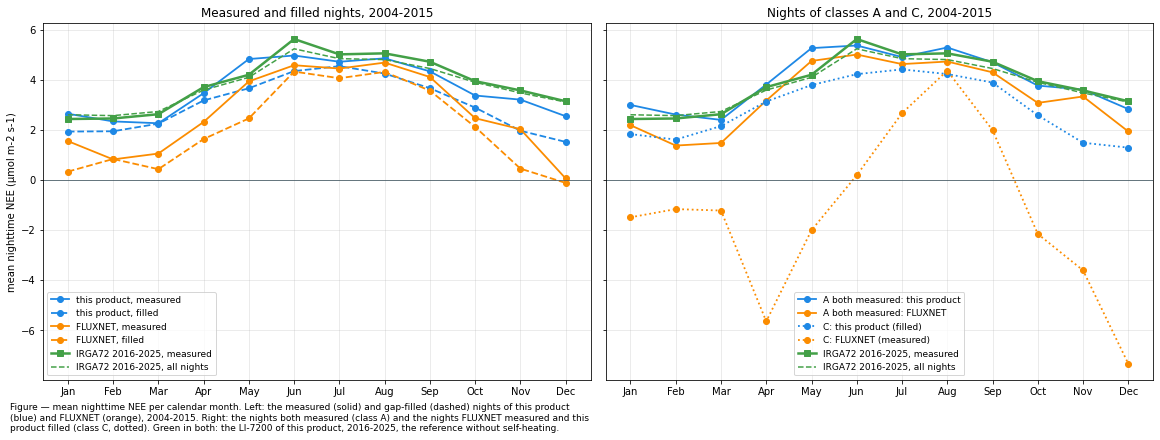

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6), dpi=72, layout="constrained", sharey=True)
_m = range(1, 13)
_nm = nights_month.set_axis(_m)
for _col, _c, _ls, _lab in (
        ('ours, measured', COLORS['ours'], '-', "this product, measured"),
        ('ours, filled', COLORS['ours'], '--', "this product, filled"),
        ('FLUXNET, measured', COLORS['FLUXNET'], '-', "FLUXNET, measured"),
        ('FLUXNET, filled', COLORS['FLUXNET'], '--', "FLUXNET, filled")):
    axs[0].plot(_m, _nm[_col], color=_c, ls=_ls, marker='o', lw=1.8, label=_lab)
for _col, _c, _ls, _lab in (
        ('A: ours', COLORS['ours'], '-', "A both measured: this product"),
        ('A: FLUXNET', COLORS['FLUXNET'], '-', "A both measured: FLUXNET"),
        ('C: ours (filled)', COLORS['ours'], ':', "C: this product (filled)"),
        ('C: FLUXNET (measured)', COLORS['FLUXNET'], ':', "C: FLUXNET (measured)")):
    axs[1].plot(_m, _nm[_col], color=_c, ls=_ls, marker='o', lw=1.8, label=_lab)
for _ax in axs:
    _ax.plot(_m, _nm['IRGA72, measured'], color=COLORS['IRGA72'], lw=2.5, marker='s',
             label=f"IRGA72 {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}, measured")
    _ax.plot(_m, _nm['IRGA72, all nights'], color=COLORS['IRGA72'], lw=1.5, ls='--',
             label=f"IRGA72 {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}, all nights")
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
    month_axis(_ax)
axs[0].set_ylabel(f"mean nighttime NEE ({units})")
axs[0].set_title(f"Measured and filled nights, {LI7500_ONLY[0]}-{LI7500_ONLY[1]}")
axs[1].set_title(f"Nights of classes A and C, {LI7500_ONLY[0]}-{LI7500_ONLY[1]}")
figcap(fig, f"mean nighttime NEE per calendar month. Left: the measured (solid) and gap-filled (dashed) "
            f"nights of this product (blue) and FLUXNET (orange), {LI7500_ONLY[0]}-{LI7500_ONLY[1]}. "
            f"Right: the nights both measured (class A) and the nights FLUXNET measured and this "
            f"product filled (class C, dotted). Green in both: the LI-7200 of this product, "
            f"{IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}, the reference without self-heating.")
fig.show()

From late autumn to early spring the FLUXNET nights, measured and filled, lie well below those of
this product and of the LI-7200. The class-C nights, which FLUXNET keeps and this product removes,
are on average negative from autumn to spring: apparent nighttime uptake, which the tests of
negative nighttime values and the outlier tests of this product remove (Level 3.2). In summer the
products and the LI-7200 are close.

### 📋 Table: nights by USTAR class

In [20]:
_q = c[(c.index.year <= LI7500_ONLY[1]) & c['night']].copy()
_q['USTAR class (m s-1)'] = pd.cut(_q['USTAR'], USTAR_BINS)
by_ustar = _q.groupby('USTAR class (m s-1)', observed=True).agg(
    nights=('ours', 'size'), ours_meas=('ours_meas', 'mean'), flx_meas=('flx_meas', 'mean'),
    l32=('ours_l32', 'mean'))
by_ustar['ours_meas'] *= 100
by_ustar['flx_meas'] *= 100
by_ustar.columns = ['night records', 'ours measured (%)', 'FLUXNET measured (%)',
                    f'ours before USTAR filter, mean ({units})']
by_ustar.index = by_ustar.index.astype(str)
display(styled(by_ustar, caption=f"nights {LI7500_ONLY[0]}-{LI7500_ONLY[1]} by USTAR of this product: the "
                                 f"share each product keeps as measured, and the mean NEE of this product "
                                 f"after the outlier tests and before the USTAR filter. The USTAR threshold "
                                 f"of this product is {USTAR_CUT_50} m s-1",
               fmt={'night records': "{:,.0f}", 'ours measured (%)': "{:.0f}",
                    'FLUXNET measured (%)': "{:.0f}", f'ours before USTAR filter, mean ({units})': "{:.2f}"},
               cmap=None))

Table — nights 2004-2015 by USTAR of this product: the share each product keeps as measured, and the
mean NEE of this product after the outlier tests and before the USTAR filter. The USTAR threshold of
this product is 0.304 m s-1



,night records,ours measured (%),FLUXNET measured (%),"ours before USTAR filter, mean (µmol m-2 s-1)"
USTAR class (m s-1),,,,
"(0.0, 0.1]","5,127",0,0,0.13
"(0.1, 0.2]","17,300",0,0,0.45
"(0.2, 0.3]","15,650",0,5,0.90
"(0.3, 0.4]","12,540",50,27,1.91
"(0.4, 0.6]","20,153",52,42,3.06
"(0.6, 5.0]","24,215",48,44,4.76


This product keeps no night below its threshold. FLUXNET keeps a few nights in the class just below
it and fewer in the classes above, although its reference thresholds (`GRP_FLUX_REF` of the BIF file) are
mostly below the constant `CUT_50` of this product in 2004-2015 (see the comprehensive comparison).
It keeps fewer measured nights because of its other filters, not its threshold. Before the USTAR filter the nighttime `NEE` rises with USTAR in every class. Below the
threshold it is low, the signature of respiration that the turbulence does not carry to the sensor;
above it the rise also reflects the season.

### 📋 Table: 2016-2017 nights, LI-7500, LI-7200 and FLUXNET

In [21]:
_e = c[c.index.year >= PARALLEL_YEARS[0]]
_e = _e.join(nee72[[varname]].rename(columns={varname: 'ours72'}))
_en = _e[_e['night']]
_ye, _yen = _e.index.year, _en.index.year
parallel = pd.DataFrame({
    'night, IRGA75 (ours)': _en['ours'].groupby(_yen).mean(),
    'night, IRGA72 (ours)': _en['ours72'].groupby(_yen).mean(),
    'night, FLUXNET': _en['flx'].groupby(_yen).mean(),
    'year, IRGA75 (ours)': per_year(_e['ours']),
    'year, IRGA72 (ours)': per_year(_e['ours72']),
    'year, FLUXNET': per_year(_e['flx']),
})
parallel.index.name = 'YEAR'
display(styled(parallel, caption=f"the parallel years: mean nighttime NEE ({units}, all nights) and annual "
                                 f"NEE ({units_sum}) of the LI-7500 and the LI-7200 of this product, and of "
                                 f"FLUXNET, which uses the LI-7200 in these years",
               fmt={col: ("{:.2f}" if col.startswith('night') else "{:.0f}") for col in parallel.columns},
               cmap=None))

Table — the parallel years: mean nighttime NEE (µmol m-2 s-1, all nights) and annual NEE (gC m-2) of
the LI-7500 and the LI-7200 of this product, and of FLUXNET, which uses the LI-7200 in these years



,"night, IRGA75 (ours)","night, IRGA72 (ours)","night, FLUXNET","year, IRGA75 (ours)","year, IRGA72 (ours)","year, FLUXNET"
YEAR,,,,,,
2016,2.98,3.62,4.24,-397,-159,-81
2017,2.74,3.73,5.35,-232,71,288


In the parallel years the LI-7200 nights of this product are higher than its LI-7500 nights, and
the FLUXNET nights, built on the LI-7200, are higher still. FLUXNET has less annual uptake than both
records of this product in these years. On the shared measured records FLUXNET and the LI-7200 of this product
agree; the difference comes from FLUXNET's higher USTAR thresholds in these years and the higher
values it fills (see the comprehensive comparison).

## Comprehensive comparison: overall, day and night

This part compares this product with FLUXNET (`NEE_VUT_REF`) over the whole day, by day and by
night (FLUXNET `NIGHT`), per year, per season and per month. Each difference is split by record
class, and the mean flux of the measured and of the gap-filled records of each product is shown,
so that a difference can be traced to the measured values (class A), to the selection of the
measured records (classes B and C) or to the gap-filling (class D). A table of the causes and their
approximate size closes the part.

- **Years.** Means over years use 2005-2015, the complete years in which both products use the
  LI-7500. 2004 is shown per year only, on the half-hours FLUXNET covers.
- **2016 and 2017.** FLUXNET uses the LI-7200 in these years. The LI-7200 of this product
  (`IRGA72`) is shown next to its LI-7500 (`IRGA75`); for the LI-7200 the record classes are
  formed with its own fill flag.
- **The LI-7200 as a reference.** Where the LI-7200 of this product is shown as a seasonal or
  monthly reference, it covers the years 2016-2024 that FLUXNET also covers, split by the FLUXNET
  night flag.
- **Seasons.** DJF is December, January and February of the same calendar year, as in the table of
  the annual difference by season above.
- **Sign.** A difference is this product minus FLUXNET; a positive difference means less uptake or
  more respiration in this product.

In [22]:
# FLUXNET files read again for this part: the reference scenario with a constant USTAR threshold
# (CUT) from the half-hourly file, and the reference USTAR thresholds from the BIF file.
fx_FLUXNET_BIF = "EUF_CH-Lae_FLUXNET_BIF_2004-2024_v1.3_r1.csv"
fx_FLX_CUT = 'NEE_CUT_REF'
fx_MEAN_YEARS = (LI7500_ONLY[0] + 1, LI7500_ONLY[1])  # complete years in which both use the LI-7500
fx_SEASONS = {'DJF': [12, 1, 2], 'MAM': [3, 4, 5], 'JJA': [6, 7, 8], 'SON': [9, 10, 11]}
fx_WINTER = [11, 12, 1, 2, 3]  # November to March
fx_PARTS = ('overall', 'day', 'night')
fx_CLASS_COLORS = {'A': '#78909C', 'B': '#64B5F6', 'C': '#FFB74D', 'D': '#7E57C2'}

# The reference USTAR thresholds of FLUXNET, group GRP_FLUX_REF of the BIF file. The file also holds
# other site metadata; only this group is kept.
_fx_bif = pd.read_csv(Path(FLUXNET_DIR) / fx_FLUXNET_BIF, dtype=str)
_fx_ref = (_fx_bif[_fx_bif['VARIABLE_GROUP'] == 'GRP_FLUX_REF']
           .pivot_table(index='GROUP_ID', columns='VARIABLE', values='DATAVALUE', aggfunc='first'))
del _fx_bif
_fx_ref = _fx_ref[(_fx_ref['REF_VARIABLE'] == 'NEE') & (_fx_ref['REF_TIME_RESOLUTION'] == 'HH')]
_fx_vut = _fx_ref[_fx_ref['REF_VERSION'] == 'VUT']
fx_ustar_vut = pd.Series(_fx_vut['REF_USTAR_THRESHOLD'].astype(float).to_numpy(),
                         index=_fx_vut['REF_YEAR'].astype(float).astype(int).to_numpy()).sort_index()
fx_ustar_cut = float(_fx_ref.loc[_fx_ref['REF_VERSION'] == 'CUT', 'REF_USTAR_THRESHOLD'].iloc[0])
assert fx_ustar_vut.index.is_unique
assert set(range(FIRST_YEAR, LAST_YEAR + 1)) <= set(fx_ustar_vut.index), "VUT thresholds missing"

_fx_cut = pd.read_csv(Path(FLUXNET_DIR) / FLUXNET_HH, usecols=['TIMESTAMP_START', fx_FLX_CUT],
                      na_values=FLX_MISSING).replace(FLX_MISSING, np.nan)
_fx_cut.index = pd.DatetimeIndex(pd.to_datetime(_fx_cut.pop('TIMESTAMP_START').astype(str),
                                                format='%Y%m%d%H%M') + pd.Timedelta('15min')).as_unit('ns')

# The LI-7500 years: the joined frame of the comparison with FLUXNET, with the LI-7200 of this
# product in the parallel years and the reason a record is measured in one product only.
_fx_month_season = {m: s for s, months in fx_SEASONS.items() for m in months}
fx = c.copy()
fx['year'], fx['month'] = fx.index.year, fx.index.month
fx['season'] = fx['month'].map(_fx_month_season)
fx['ours72'] = nee72[varname].reindex(fx.index)
fx['ours72_meas'] = nee72[flagname].reindex(fx.index).eq(0)
fx['diff72'] = fx['ours72'] - fx['flx']
fx['cls72'] = np.select([fx['ours72_meas'] & fx['flx_meas'], fx['ours72_meas'] & ~fx['flx_meas'],
                         ~fx['ours72_meas'] & fx['flx_meas']], ['A', 'B', 'C'], 'D')
fx['cls72'] = fx['cls72'].where(fx['ours72'].notna())
fx['flx_cut'] = _fx_cut[fx_FLX_CUT].reindex(fx.index)
fx['ustar_vut'] = fx['year'].map(fx_ustar_vut)
# Class C: why this product did not keep the record. Class B: whether the record lies below the
# FLUXNET threshold of its year. USTAR of this product and of FLUXNET agree within a few mm s-1.
fx['reason'] = np.select(
    [(fx['cls'] == 'C') & fx['FC'].isna(),
     (fx['cls'] == 'C') & fx['ours_l32'].isna(),
     (fx['cls'] == 'C') & (fx['USTAR'] < USTAR_CUT_50),
     fx['cls'] == 'C',
     (fx['cls'] == 'B') & (fx['USTAR'] < fx['ustar_vut']),
     fx['cls'] == 'B'],
    ['C, no flux in this product', 'C, quality and outlier tests', 'C, USTAR filter', 'C, other',
     'B, below the FLUXNET threshold', 'B, other'], '')
fx_mean = fx[fx['year'].between(*fx_MEAN_YEARS)]
fx_par = fx[fx['year'].between(*PARALLEL_YEARS)]
fx_n_mean, fx_n_par = fx_mean['year'].nunique(), fx_par['year'].nunique()

# The LI-7200 reference: the years FLUXNET also covers, split by the FLUXNET night flag.
fx_IRGA72_REF = (IRGA72_YEARS[0], min(IRGA72_YEARS[1], int(hh.index[-1].year)))
fx72 = r72.loc[str(fx_IRGA72_REF[0]):str(fx_IRGA72_REF[1])].join(hh[FLX_NIGHT])
assert fx72[FLX_NIGHT].notna().all(), "the FLUXNET night flag does not cover the LI-7200 reference"
fx72['night_flx'] = fx72[FLX_NIGHT].eq(1)
fx72['year'], fx72['month'] = fx72.index.year, fx72.index.month
fx72['season'] = fx72['month'].map(_fx_month_season)
fx_n72 = fx72['year'].nunique()
fx_REF72 = f"IRGA72 {fx_IRGA72_REF[0]}-{fx_IRGA72_REF[1]}"
fx_MEAN_LABEL = f"{fx_MEAN_YEARS[0]}-{fx_MEAN_YEARS[1]}"


def fx_select(frame, part, night='night'):
    """The records of one part of the day: 'overall', 'day' or 'night'."""
    if part == 'overall':
        return frame
    return frame[frame[night]] if part == 'night' else frame[~frame[night]]


def fx_sums(frame, col, by, part, night='night', years=1):
    """Sums of `col` in gC m-2 per group `by` over the records of `part`, divided by `years`."""
    return fx_select(frame, part, night).groupby(by)[col].sum(min_count=1) * UMOL_TO_GC / years


def fx_class_sums(frame, by, part, cls='cls', diff='diff', years=1):
    """The difference in gC m-2 per group `by` (rows) and record class (columns A-D)."""
    out = fx_select(frame, part).groupby([by, cls])[diff].sum().unstack(cls) * UMOL_TO_GC / years
    return out.reindex(columns=list(CLASSES)).fillna(0)


def fx_ours_flx(frame, by, years=1, ours='ours', diff='diff'):
    """This product, FLUXNET and their difference per group `by`, overall, by day and by night."""
    out = {}
    for part in fx_PARTS:
        out[f"{part}, ours"] = fx_sums(frame, ours, by, part, years=years)
        out[f"{part}, FLUXNET"] = fx_sums(frame, 'flx', by, part, years=years)
        out[f"{part}, difference"] = fx_sums(frame, diff, by, part, years=years)
    return pd.DataFrame(out)


def fx_diff_cols(table):
    """The columns of a table that hold a difference."""
    return [col for col in table.columns if 'difference' in col]


def fx_stacked(ax, parts, x, width=0.7):
    """Stacked bars of the class contributions (columns A-D): positive up, negative down."""
    pos, neg = np.zeros(len(x)), np.zeros(len(x))
    for k in CLASSES:
        v = parts[k].reindex(x).fillna(0).to_numpy()
        ax.bar(x, v, width=width, bottom=np.where(v >= 0, pos, neg), color=fx_CLASS_COLORS[k],
               label=f"{k} {CLASSES[k]}")
        pos, neg = pos + np.clip(v, 0, None), neg + np.clip(v, None, 0)


print(f"FLUXNET VUT reference thresholds {FIRST_YEAR}-{LAST_YEAR}: "
      f"{fx_ustar_vut.loc[FIRST_YEAR:LAST_YEAR].min():.3f} to {fx_ustar_vut.loc[FIRST_YEAR:LAST_YEAR].max():.3f} m s-1; "
      f"CUT reference threshold {fx_ustar_cut:.3f} m s-1; this product CUT_50 {USTAR_CUT_50} m s-1")
print(f"means over {fx_MEAN_LABEL} ({fx_n_mean} years); LI-7200 reference {fx_REF72} ({fx_n72} years)")

FLUXNET VUT reference thresholds 2004-2017: 0.231 to 0.503 m s-1; CUT reference threshold 0.430 m s-1; this product CUT_50 0.304 m s-1
means over 2005-2015 (11 years); LI-7200 reference IRGA72 2016-2024 (9 years)


### 📋 Table: annual sums, overall, day and night

In [23]:
fx_y75 = fx_ours_flx(fx, 'year')
fx_y72 = fx_ours_flx(fx_par, 'year', ours='ours72', diff='diff72')
assert np.allclose(fx_y75['overall, difference'].to_numpy(), annual['ours minus FLUXNET'].to_numpy())
fx_annual = pd.concat([fx_y75.set_axis([f"{y}" for y in fx_y75.index]),
                       fx_y72.set_axis([f"{y}, IRGA72" for y in fx_y72.index])])
fx_annual.loc[f"mean {fx_MEAN_LABEL}"] = fx_y75.loc[fx_MEAN_YEARS[0]:fx_MEAN_YEARS[1]].mean()
fx_annual.index.name = 'YEAR'
display(styled(fx_annual, caption=f"annual NEE in {units_sum} of this product ('ours') and of FLUXNET, and "
                                  f"the difference ours minus FLUXNET, over the whole day, by day and by "
                                  f"night (FLUXNET NIGHT), on the half-hours FLUXNET covers. The rows "
                                  f"marked IRGA72 show the LI-7200 of this product in place of its LI-7500 "
                                  f"in the years in which FLUXNET uses the LI-7200. The last row is the "
                                  f"mean of {fx_MEAN_LABEL}",
               subset=fx_diff_cols(fx_annual)))

Table — annual NEE in gC m-2 of this product ('ours') and of FLUXNET, and the difference ours minus
FLUXNET, over the whole day, by day and by night (FLUXNET NIGHT), on the half-hours FLUXNET covers.
The rows marked IRGA72 show the LI-7200 of this product in place of its LI-7500 in the years in
which FLUXNET uses the LI-7200. The last row is the mean of 2005-2015



,"overall, ours","overall, FLUXNET","overall, difference","day, ours","day, FLUXNET","day, difference","night, ours","night, FLUXNET","night, difference"
YEAR,,,,,,,,,
2004,-158,-444,286,-595,-662,68,436,219,218
2005,62,-158,221,-475,-556,81,537,398,140
2006,43,-124,167,-503,-479,-24,546,355,191
2007,-180,-352,172,-757,-777,20,577,425,152
2008,-57,-201,144,-645,-642,-3,587,441,146
2009,-57,-270,213,-592,-584,-8,535,314,221
2010,-168,-441,273,-642,-718,76,474,277,197
2011,-312,-517,204,-897,-960,63,584,443,141
2012,-338,-680,342,-847,-953,106,509,273,236


In the LI-7500 years most of the difference arises at night: this product has more nighttime
respiration than FLUXNET in every year. By day the two products are close in most years, with
differences of either sign. In 2016 and 2017 FLUXNET has more nighttime respiration than both
records of this product, and the LI-7200 of this product lies between its LI-7500 and FLUXNET at
night; by day FLUXNET shows more uptake than the LI-7200 of this product in these years.

### 📊 Plot: annual sums and their difference by record class

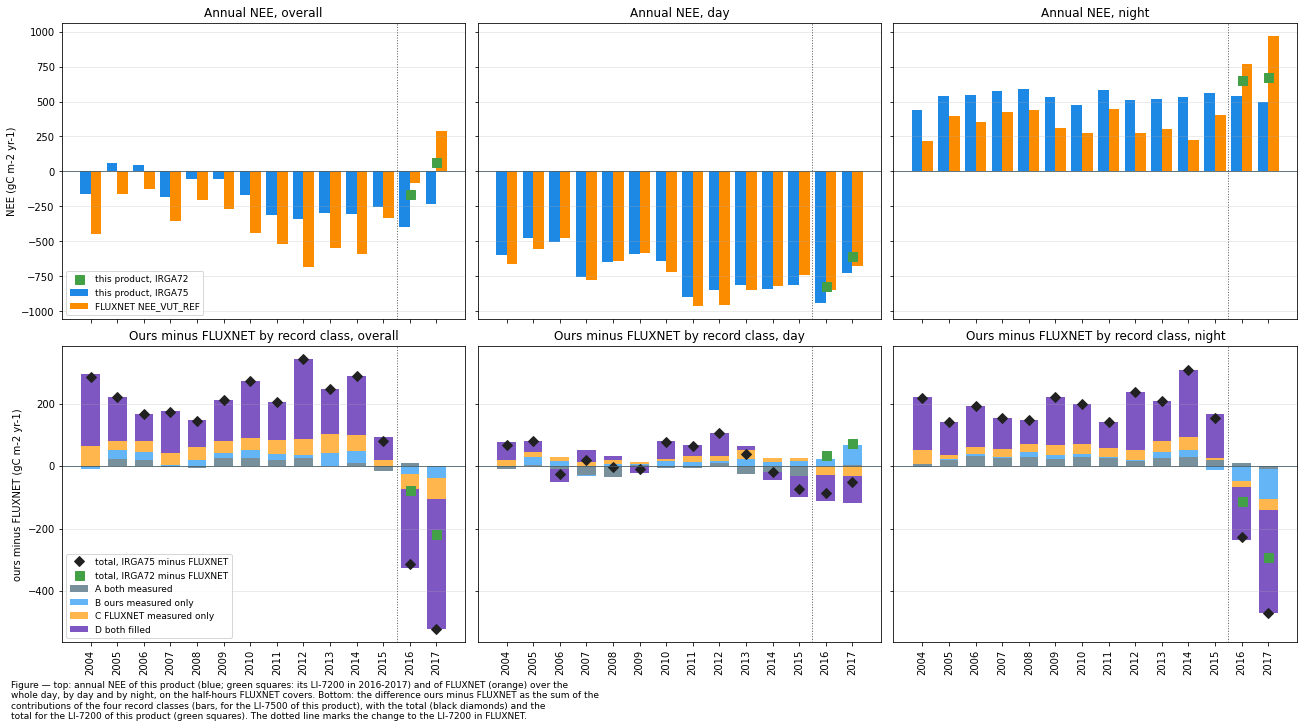

In [24]:
_fx_x = np.arange(FIRST_YEAR, LAST_YEAR + 1)
_fx_x72 = np.arange(PARALLEL_YEARS[0], PARALLEL_YEARS[1] + 1)
fig, axs = plt.subplots(2, 3, figsize=(18, 10), dpi=72, layout="constrained", sharex=True, sharey='row')
for _fx_j, _fx_part in enumerate(fx_PARTS):
    _ax = axs[0, _fx_j]
    _ax.bar(_fx_x - 0.2, fx_y75[f"{_fx_part}, ours"], width=0.4, color=COLORS['ours'],
            label="this product, IRGA75")
    _ax.bar(_fx_x + 0.2, fx_y75[f"{_fx_part}, FLUXNET"], width=0.4, color=COLORS['FLUXNET'],
            label="FLUXNET NEE_VUT_REF")
    _ax.plot(_fx_x72, fx_y72[f"{_fx_part}, ours"], color=COLORS['IRGA72'], marker='s', ms=9, lw=0,
             label="this product, IRGA72")
    _ax.set_title(f"Annual NEE, {_fx_part}")
    _ax = axs[1, _fx_j]
    fx_stacked(_ax, fx_class_sums(fx, 'year', _fx_part), _fx_x)
    _ax.plot(_fx_x, fx_y75[f"{_fx_part}, difference"], 'D', color='#212121', ms=7,
             label="total, IRGA75 minus FLUXNET")
    _ax.plot(_fx_x72, fx_y72[f"{_fx_part}, difference"], 's', color=COLORS['IRGA72'], ms=9,
             label="total, IRGA72 minus FLUXNET")
    _ax.set_title(f"Ours minus FLUXNET by record class, {_fx_part}")
    _ax.set_xticks(_fx_x)
    _ax.set_xticklabels(_fx_x, rotation=90)
for _ax in axs.flat:
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.axvline(LI7500_ONLY[1] + 0.5, color='#616161', lw=1, ls=':')
    _ax.grid(alpha=0.3, axis='y')
axs[0, 0].set_ylabel(f"NEE ({units_sum} yr-1)")
axs[1, 0].set_ylabel(f"ours minus FLUXNET ({units_sum} yr-1)")
axs[0, 0].legend(fontsize=9, loc='lower left')
axs[1, 0].legend(fontsize=9, loc='lower left')
figcap(fig, f"top: annual NEE of this product (blue; green squares: its LI-7200 in {PARALLEL_YEARS[0]}-"
            f"{PARALLEL_YEARS[1]}) and of FLUXNET (orange) over the whole day, by day and by night, on the "
            f"half-hours FLUXNET covers. Bottom: the difference ours minus FLUXNET as the sum of the "
            f"contributions of the four record classes (bars, for the LI-7500 of this product), with the "
            f"total (black diamonds) and the total for the LI-7200 of this product (green squares). The "
            f"dotted line marks the change to the LI-7200 in FLUXNET.")
fig.show()

At night the records both products gap-fill (class D) carry the largest share of the difference
in every LI-7500 year; the shared measured nights (class A) and the nights FLUXNET measured and this
product removed (class C) add smaller positive amounts. By day the contributions are smaller and
change sign between years, the filled days (class D) varying most. In 2016 and 2017 the sign
reverses at night, mainly in classes B and D.

### 📋 Table: mean annual difference by record class

In [25]:
_fx_cases = {f"{fx_MEAN_LABEL}, IRGA75": (fx_mean, 'cls', 'diff', fx_n_mean),
             f"{PARALLEL_YEARS[0]}-{PARALLEL_YEARS[1]}, IRGA75": (fx_par, 'cls', 'diff', fx_n_par),
             f"{PARALLEL_YEARS[0]}-{PARALLEL_YEARS[1]}, IRGA72": (fx_par, 'cls72', 'diff72', fx_n_par)}
fx_class_mean = pd.DataFrame({
    f"{_fx_name}, {_fx_part}": (fx_select(_fx_f, _fx_part).groupby(_fx_cls)[_fx_d].sum()
                                * UMOL_TO_GC / _fx_n).reindex(list(CLASSES))
    for _fx_name, (_fx_f, _fx_cls, _fx_d, _fx_n) in _fx_cases.items() for _fx_part in fx_PARTS})
fx_class_mean.index = [f"{k} {v}" for k, v in CLASSES.items()]
fx_class_mean.loc['total'] = fx_class_mean.sum()
fx_class_mean.index.name = 'CLASS'
display(styled(fx_class_mean, caption=f"mean annual difference ours minus FLUXNET in {units_sum} yr-1 per "
                                      f"record class, over the whole day, by day and by night: the LI-7500 "
                                      f"of this product over {fx_MEAN_LABEL}, and over {PARALLEL_YEARS[0]}-"
                                      f"{PARALLEL_YEARS[1]} its LI-7500 and its LI-7200, each with its own "
                                      f"record classes. The rows add up to 'total'",
               subset=pd.IndexSlice[fx_class_mean.index[:-1], :]))

Table — mean annual difference ours minus FLUXNET in gC m-2 yr-1 per record class, over the whole
day, by day and by night: the LI-7500 of this product over 2005-2015, and over 2016-2017 its LI-7500
and its LI-7200, each with its own record classes. The rows add up to 'total'



,"2005-2015, IRGA75, overall","2005-2015, IRGA75, day","2005-2015, IRGA75, night","2016-2017, IRGA75, overall","2016-2017, IRGA75, day","2016-2017, IRGA75, night","2016-2017, IRGA72, overall","2016-2017, IRGA72, day","2016-2017, IRGA72, night"
CLASS,,,,,,,,,
A both measured,12,-13,25,3,3,1,4,5,-1
B ours measured only,20,12,8,-30,43,-73,-33,42,-75
C FLUXNET measured only,40,14,26,-58,-30,-27,-16,-13,-2
D both filled,141,10,131,-333,-84,-250,-104,21,-125
total,214,23,190,-418,-69,-349,-148,55,-202


Over the LI-7500 years the nights that both products gap-fill (class D) account for most of the
mean annual difference. The shared measured nights (class A) and the nights only one product
measured (B and C) each add a smaller positive amount. By day the sum of the classes is small:
class A is negative and the other classes are positive. In the parallel years class A of the
LI-7200 is close to zero by day and by night: there FLUXNET and this product start from the same
LI-7200 flux, and the difference comes from the records that FLUXNET fills, the records this
product measured (class B) and those both fill (class D).

### 📋 Table: seasonal sums, overall, day and night

In [26]:
_fx_s = fx_ours_flx(fx_mean, 'season', years=fx_n_mean)
for _fx_part in fx_PARTS:
    _fx_s[f"{_fx_part}, {fx_REF72}"] = fx_sums(fx72, varname, 'season', _fx_part, night='night_flx',
                                               years=fx_n72)
fx_season_sums = _fx_s[[f"{p}, {q}" for p in fx_PARTS
                        for q in ('ours', 'FLUXNET', 'difference', fx_REF72)]].reindex(list(fx_SEASONS))
fx_season_sums.loc['year'] = fx_season_sums.sum()
fx_season_sums.index.name = 'SEASON'
display(styled(fx_season_sums, caption=f"mean seasonal NEE in {units_sum} over {fx_MEAN_LABEL}: this "
                                       f"product ('ours', LI-7500), FLUXNET and the difference, over the "
                                       f"whole day, by day and by night, with the LI-7200 of this product "
                                       f"over {fx_IRGA72_REF[0]}-{fx_IRGA72_REF[1]} as a reference (FLUXNET "
                                       f"night flag)", subset=fx_diff_cols(fx_season_sums)))

Table — mean seasonal NEE in gC m-2 over 2005-2015: this product ('ours', LI-7500), FLUXNET and the
difference, over the whole day, by day and by night, with the LI-7200 of this product over 2016-2024
as a reference (FLUXNET night flag)



,"overall, ours","overall, FLUXNET","overall, difference","overall, IRGA72 2016-2024","day, ours","day, FLUXNET","day, difference","day, IRGA72 2016-2024","night, ours","night, FLUXNET","night, difference","night, IRGA72 2016-2024"
SEASON,,,,,,,,,,,,
DJF,184,119,65,242,72,82,-10,82,113,37,75,160
MAM,-41,-119,77,-52,-167,-185,18,-189,125,66,59,137
JJA,-320,-355,34,-347,-474,-497,23,-517,154,143,11,170
SON,8,-29,37,65,-142,-135,-8,-132,150,105,45,196
year,-169,-383,214,-92,-711,-734,23,-755,542,351,190,664


The difference is largest in winter (DJF) and smallest in summer (JJA), in which the two products
agree most closely. At night the FLUXNET sums of winter, spring and autumn lie well below those of
this product and of the LI-7200 years, while the nighttime sums of this product are close to the
LI-7200 in winter and spring. By day the products are close in every season.

### 📋 Table: seasonal difference per year, day and night

In [27]:
def _fx_season_year(frame, diff):
    parts = {p: fx_select(frame, p).groupby(['year', 'season'])[diff].sum().unstack('season')
             * UMOL_TO_GC for p in ('day', 'night')}
    out = pd.concat(parts, axis=1).swaplevel(axis=1)
    out = out.reindex(columns=pd.MultiIndex.from_product([list(fx_SEASONS), ['day', 'night']]))
    out.columns = [f"{s}, {p}" for s, p in out.columns]
    return out


_fx_sy75 = _fx_season_year(fx, 'diff')
_fx_sy72 = _fx_season_year(fx_par, 'diff72')
fx_season_year = pd.concat([_fx_sy75.set_axis([f"{y}" for y in _fx_sy75.index]),
                            _fx_sy72.set_axis([f"{y}, IRGA72" for y in _fx_sy72.index])])
fx_season_year.loc[f"mean {fx_MEAN_LABEL}"] = _fx_sy75.loc[fx_MEAN_YEARS[0]:fx_MEAN_YEARS[1]].mean()
fx_season_year.index.name = 'YEAR'
display(styled(fx_season_year, caption=f"difference ours minus FLUXNET in {units_sum} per year and season, "
                                       f"by day and by night. The rows marked IRGA72 use the LI-7200 of this "
                                       f"product. 2004 starts on the first FLUXNET record in March. The last "
                                       f"row is the mean of {fx_MEAN_LABEL}"))

Table — difference ours minus FLUXNET in gC m-2 per year and season, by day and by night. The rows
marked IRGA72 use the LI-7200 of this product. 2004 starts on the first FLUXNET record in March. The
last row is the mean of 2005-2015



,"DJF, day","DJF, night","MAM, day","MAM, night","JJA, day","JJA, night","SON, day","SON, night"
YEAR,,,,,,,,
2004,32,176,19,41,18,-41,-2,41
2005,26,43,69,75,-9,-7,-6,30
2006,-13,88,53,98,-80,-16,17,21
2007,-12,75,22,11,28,29,-19,38
2008,34,94,-35,26,45,1,-46,25
2009,-26,65,19,67,27,8,-28,80
2010,-9,77,23,55,50,-8,11,73
2011,11,51,48,29,6,23,-2,38
2012,-21,25,-1,94,97,44,32,72


In the LI-7500 years the nighttime difference is positive in winter, spring and autumn of nearly
every year and largest in winter; in summer it is small and of either sign. The daytime difference
is small and changes sign between years and seasons. With the LI-7200 in 2016 and 2017 the
nighttime difference is negative, most strongly in summer and autumn.

### 📋 Table: seasonal difference by record class, day and night

In [28]:
def _fx_class_table(frame, by, order, years, labels=None):
    parts = {p: fx_class_sums(frame, by, p, years=years).reindex(order) for p in ('day', 'night')}
    out = pd.concat(parts, axis=1)
    out.columns = [f"{p}, {k}" for p, k in out.columns]
    out['total'] = out.sum(axis=1)
    if labels is not None:
        out.index = labels
    out.loc['year'] = out.sum()
    return out


fx_season_cls = _fx_class_table(fx_mean, 'season', list(fx_SEASONS), fx_n_mean)
fx_season_cls.index.name = 'SEASON'
display(styled(fx_season_cls, caption=f"mean difference ours minus FLUXNET in {units_sum} per season over "
                                      f"{fx_MEAN_LABEL}, split by day and night and by record class (A both "
                                      f"measured, B ours measured only, C FLUXNET measured only, D both "
                                      f"filled). The columns add up to 'total', the rows to 'year'",
               subset=pd.IndexSlice[fx_season_cls.index[:-1], fx_season_cls.columns[:-1]]))

Table — mean difference ours minus FLUXNET in gC m-2 per season over 2005-2015, split by day and
night and by record class (A both measured, B ours measured only, C FLUXNET measured only, D both
filled). The columns add up to 'total', the rows to 'year'



,"day, A","day, B","day, C","day, D","night, A","night, B","night, C","night, D",total
SEASON,,,,,,,,,
DJF,-7,3,3,-9,11,4,10,50,65
MAM,-2,4,8,8,7,2,8,42,77
JJA,2,3,3,15,3,-1,2,7,34
SON,-7,3,-0,-3,4,2,6,32,37
year,-13,12,14,10,25,8,26,131,214


The class-D nights carry the largest part of the difference in winter, spring and autumn and a
much smaller amount in summer. The class-C nights, which FLUXNET keeps and this product removes, add most
in winter. The shared measured nights (class A) add a positive amount in every season. By day class
A is negative in winter and autumn, and the gap-filled days (class D) add most in spring and summer.

### 📋 Table: monthly sums, overall, day and night

In [29]:
_fx_m = fx_ours_flx(fx_mean, 'month', years=fx_n_mean)
for _fx_part in fx_PARTS:
    _fx_m[f"{_fx_part}, {fx_REF72}"] = fx_sums(fx72, varname, 'month', _fx_part, night='night_flx',
                                               years=fx_n72)
fx_month_sums = _fx_m[[f"{p}, {q}" for p in fx_PARTS for q in ('ours', 'FLUXNET', 'difference', fx_REF72)]]
_fx_show = fx_month_sums.set_axis([calendar.month_abbr[m] for m in fx_month_sums.index])
_fx_show.loc['year'] = fx_month_sums.sum()
_fx_show.index.name = 'MONTH'
display(styled(_fx_show, caption=f"mean monthly NEE in {units_sum} over {fx_MEAN_LABEL}: this product "
                                 f"('ours', LI-7500), FLUXNET and the difference, over the whole day, by day "
                                 f"and by night, with the LI-7200 of this product over {fx_IRGA72_REF[0]}-"
                                 f"{fx_IRGA72_REF[1]} as a reference (FLUXNET night flag)",
               subset=fx_diff_cols(_fx_show)))

Table — mean monthly NEE in gC m-2 over 2005-2015: this product ('ours', LI-7500), FLUXNET and the
difference, over the whole day, by day and by night, with the LI-7200 of this product over 2016-2024
as a reference (FLUXNET night flag)



,"overall, ours","overall, FLUXNET","overall, difference","overall, IRGA72 2016-2024","day, ours","day, FLUXNET","day, difference","day, IRGA72 2016-2024","night, ours","night, FLUXNET","night, difference","night, IRGA72 2016-2024"
MONTH,,,,,,,,,,,,
Jan,72,46,26,81,29,33,-4,29,42,12,30,52
Feb,57,41,15,60,23,28,-4,17,34,14,20,43
Mar,39,9,31,38,4,-2,6,-6,35,11,25,44
Apr,19,-2,21,7,-24,-26,2,-40,43,24,19,47
May,-100,-126,26,-97,-147,-157,10,-144,46,31,15,47
Jun,-126,-135,9,-142,-173,-179,5,-197,47,43,4,55
Jul,-108,-123,15,-128,-158,-168,10,-182,50,45,6,54
Aug,-87,-96,9,-77,-143,-151,8,-138,56,55,1,61
Sep,-56,-66,10,-60,-111,-119,8,-124,55,53,2,64


### 📊 Plot: monthly sums and their difference by record class

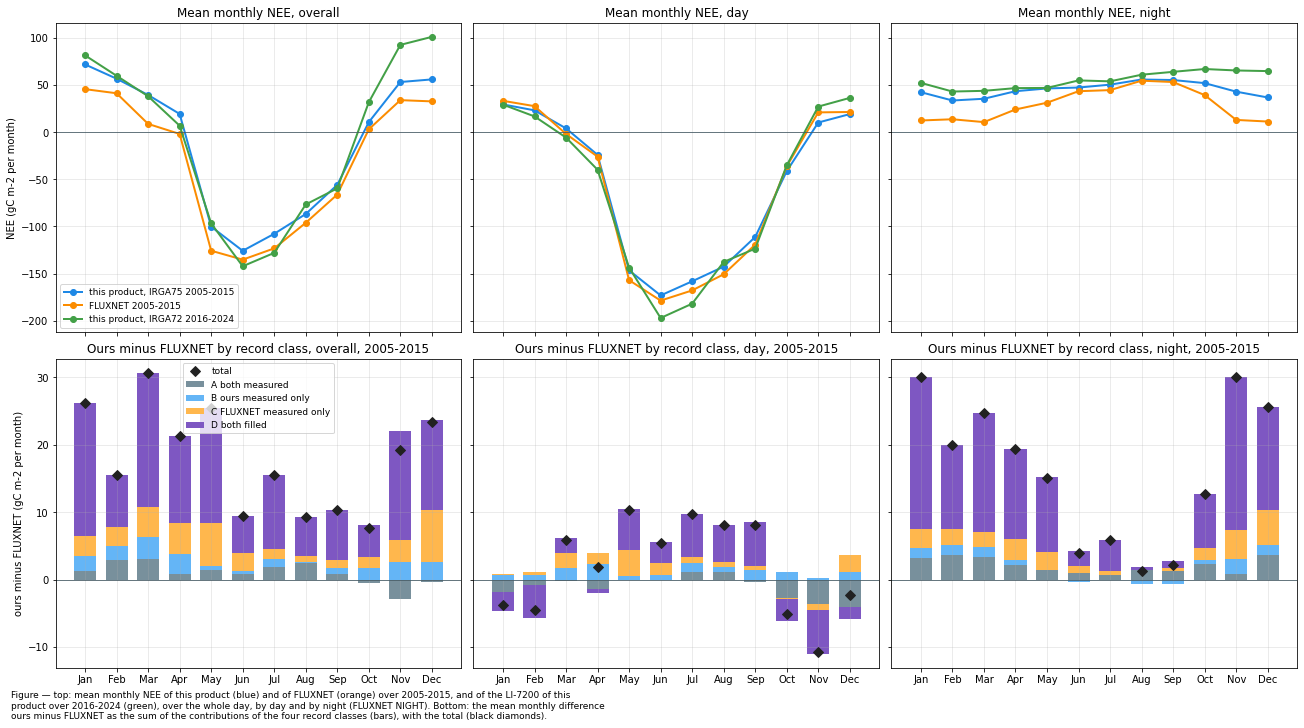

In [30]:
_fx_x = np.arange(1, 13)
fig, axs = plt.subplots(2, 3, figsize=(18, 10), dpi=72, layout="constrained", sharex=True, sharey='row')
for _fx_j, _fx_part in enumerate(fx_PARTS):
    _ax = axs[0, _fx_j]
    for _fx_col, _fx_c, _fx_lab in (('ours', COLORS['ours'], f"this product, IRGA75 {fx_MEAN_LABEL}"),
                                    ('FLUXNET', COLORS['FLUXNET'], f"FLUXNET {fx_MEAN_LABEL}"),
                                    (fx_REF72, COLORS['IRGA72'], f"this product, {fx_REF72}")):
        _ax.plot(_fx_x, fx_month_sums[f"{_fx_part}, {_fx_col}"], color=_fx_c, marker='o', lw=2,
                 label=_fx_lab)
    _ax.set_title(f"Mean monthly NEE, {_fx_part}")
    _ax = axs[1, _fx_j]
    fx_stacked(_ax, fx_class_sums(fx_mean, 'month', _fx_part, years=fx_n_mean), _fx_x)
    _ax.plot(_fx_x, fx_month_sums[f"{_fx_part}, difference"], 'D', color='#212121', ms=7, label="total")
    _ax.set_title(f"Ours minus FLUXNET by record class, {_fx_part}, {fx_MEAN_LABEL}")
for _ax in axs.flat:
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.grid(alpha=0.3)
    month_axis(_ax)
axs[0, 0].set_ylabel(f"NEE ({units_sum} per month)")
axs[1, 0].set_ylabel(f"ours minus FLUXNET ({units_sum} per month)")
axs[0, 0].legend(fontsize=9, loc='lower left')
axs[1, 0].legend(fontsize=9, loc='upper center')
figcap(fig, f"top: mean monthly NEE of this product (blue) and of FLUXNET (orange) over {fx_MEAN_LABEL}, "
            f"and of the LI-7200 of this product over {fx_IRGA72_REF[0]}-{fx_IRGA72_REF[1]} (green), over "
            f"the whole day, by day and by night (FLUXNET NIGHT). Bottom: the mean monthly difference ours "
            f"minus FLUXNET as the sum of the contributions of the four record classes (bars), with the "
            f"total (black diamonds).")
fig.show()

From June to September the monthly sums of the two products are close by day and by night. From
October to April this product has more nighttime respiration than FLUXNET in every month, mostly in
the nights both products fill (class D). In these months the nighttime sums of this product are
close to or somewhat below those of the LI-7200 years, while those of FLUXNET are well below both.
By day the monthly differences are small; class A is negative from October to January, and the
filled days (class D) add a positive amount from May to September.

### 📋 Table: monthly difference by record class, day and night

In [31]:
fx_month_cls = _fx_class_table(fx_mean, 'month', list(range(1, 13)), fx_n_mean,
                               labels=[calendar.month_abbr[m] for m in range(1, 13)])
fx_month_cls.index.name = 'MONTH'
display(styled(fx_month_cls, caption=f"mean difference ours minus FLUXNET in {units_sum} per calendar month "
                                     f"over {fx_MEAN_LABEL}, split by day and night and by record class. The "
                                     f"columns add up to 'total', the rows to 'year'",
               subset=pd.IndexSlice[fx_month_cls.index[:-1], fx_month_cls.columns[:-1]]))

Table — mean difference ours minus FLUXNET in gC m-2 per calendar month over 2005-2015, split by day
and night and by record class. The columns add up to 'total', the rows to 'year'



,"day, A","day, B","day, C","day, D","night, A","night, B","night, C","night, D",total
MONTH,,,,,,,,,
Jan,-2,1,0,-3,3,2,3,23,26
Feb,-1,1,1,-5,4,1,2,12,15
Mar,-0,2,2,2,3,2,2,18,31
Apr,-1,2,2,-1,2,1,3,13,21
May,-0,1,4,6,1,-0,3,11,26
Jun,-0,1,2,3,1,-0,1,2,9
Jul,1,1,1,6,1,-0,1,5,15
Aug,1,1,1,5,1,-1,0,0,9
Sep,-0,1,1,6,1,-1,1,1,10


The class-D nights of November to March contribute the largest monthly amounts. The class-C nights
add most in the same months. The other classes contribute a few gC m⁻² per month or less in most
months.

### 📋 Table: mean flux of measured and filled records per month

The sums above combine three things: the measured values, the share of records each product keeps
as measured, and the values its gap-filling assigns to the rest. This table shows the first and the
third as mean fluxes, per product, by day and by night; the next table shows the second.

In [32]:
def _fx_levels(frame, col, meas, night):
    out = {}
    for part in ('day', 'night'):
        sel = fx_select(frame, part, night)
        out[(part, 'measured')] = sel.loc[sel[meas], col].groupby(sel.loc[sel[meas], 'month']).mean()
        out[(part, 'filled')] = sel.loc[~sel[meas], col].groupby(sel.loc[~sel[meas], 'month']).mean()
    return out


_fx_lv = {'ours': _fx_levels(fx_mean, 'ours', 'ours_meas', 'night'),
          'FLUXNET': _fx_levels(fx_mean, 'flx', 'flx_meas', 'night'),
          fx_REF72: _fx_levels(fx72, varname, 'meas', 'night_flx')}
fx_levels = pd.DataFrame({f"{part}, {prod}, {kind}": _fx_lv[prod][(part, kind)]
                          for part in ('day', 'night') for prod in _fx_lv for kind in ('measured', 'filled')})
fx_levels.index = [calendar.month_abbr[m] for m in fx_levels.index]
fx_levels.index.name = 'MONTH'
display(styled(fx_levels, caption=f"mean NEE per calendar month in {units} of the measured and of the "
                                  f"gap-filled records, by day and by night (FLUXNET NIGHT): this product "
                                  f"('ours', LI-7500) and FLUXNET over {fx_MEAN_LABEL}, and the LI-7200 of "
                                  f"this product over {fx_IRGA72_REF[0]}-{fx_IRGA72_REF[1]}",
               fmt="{:.2f}"))

Table — mean NEE per calendar month in µmol m-2 s-1 of the measured and of the gap-filled records,
by day and by night (FLUXNET NIGHT): this product ('ours', LI-7500) and FLUXNET over 2005-2015, and
the LI-7200 of this product over 2016-2024



,"day, ours, measured","day, ours, filled","day, FLUXNET, measured","day, FLUXNET, filled","day, IRGA72 2016-2024, measured","day, IRGA72 2016-2024, filled","night, ours, measured","night, ours, filled","night, FLUXNET, measured","night, FLUXNET, filled","night, IRGA72 2016-2024, measured","night, IRGA72 2016-2024, filled"
MONTH,,,,,,,,,,,,
Jan,3.24,1.86,3.39,2.36,2.52,2.28,2.65,1.93,1.55,0.33,2.44,2.72
Feb,1.91,1.73,1.73,2.37,1.23,1.35,2.34,1.94,0.82,0.84,2.50,2.69
Mar,-0.00,0.49,-0.46,0.17,-1.02,0.17,2.27,2.23,1.06,0.53,2.74,2.79
Apr,-2.12,-0.35,-2.42,-0.49,-3.10,-1.09,3.52,3.20,2.33,1.64,3.67,3.49
May,-9.91,-3.69,-10.61,-4.75,-9.20,-4.10,4.78,3.67,3.74,2.32,4.21,3.99
Jun,-11.79,-4.13,-12.38,-5.04,-12.53,-4.52,4.99,4.36,4.48,4.09,5.68,5.02
Jul,-10.55,-4.45,-11.19,-5.44,-11.41,-3.54,4.75,4.54,4.38,3.98,5.16,4.77
Aug,-10.74,-4.52,-11.29,-5.47,-9.79,-2.91,4.91,4.25,4.58,4.25,5.00,4.71
Sep,-9.58,-3.32,-10.01,-4.66,-10.04,-3.43,4.29,3.66,4.14,3.57,4.73,4.31


By day the measured records of the two products are close in every month; in summer FLUXNET fills
the days with somewhat more uptake than this product. At night the measured records of FLUXNET lie
below those of this product from autumn to spring, and its filled nights lie lower still, close to
zero in midwinter. The filled nights of this product lie at most slightly below its measured nights
and close to the LI-7200 years. In summer the nights of the two products are close.

### 📋 Table: measured share per month

In [33]:
_fx_share = {}
for _fx_part in ('day', 'night'):
    _fx_a = fx_select(fx_mean, _fx_part)
    _fx_b = fx_select(fx72, _fx_part, 'night_flx')
    _fx_share[f"{_fx_part}, ours (%)"] = _fx_a.groupby('month')['ours_meas'].mean() * 100
    _fx_share[f"{_fx_part}, FLUXNET (%)"] = _fx_a.groupby('month')['flx_meas'].mean() * 100
    _fx_share[f"{_fx_part}, {fx_REF72} (%)"] = _fx_b.groupby('month')['meas'].mean() * 100
fx_share = pd.DataFrame(_fx_share)
fx_share.index = [calendar.month_abbr[m] for m in fx_share.index]
fx_share.index.name = 'MONTH'
display(styled(fx_share, caption=f"share of measured records per calendar month, by day and by night: this "
                                 f"product (LI-7500) and FLUXNET over {fx_MEAN_LABEL}, and the LI-7200 of this "
                                 f"product over {fx_IRGA72_REF[0]}-{fx_IRGA72_REF[1]}",
               fmt="{:.0f}", cmap='Blues', center=False))

Table — share of measured records per calendar month, by day and by night: this product (LI-7500)
and FLUXNET over 2005-2015, and the LI-7200 of this product over 2016-2024



,"day, ours (%)","day, FLUXNET (%)","day, IRGA72 2016-2024 (%)","night, ours (%)","night, FLUXNET (%)","night, IRGA72 2016-2024 (%)"
MONTH,,,,,,
Jan,38,32,36,29,24,31
Feb,38,35,49,26,23,40
Mar,50,45,44,32,27,34
Apr,56,49,56,34,28,41
May,55,49,56,32,28,40
Jun,55,49,62,31,25,41
Jul,49,43,64,30,23,38
Aug,45,39,60,24,19,35
Sep,52,45,59,32,25,37


This product keeps a larger share of the records as measured than FLUXNET in most months, by day
and by night. Both fill most of the nights, so at night the annual sum depends
mostly on the gap-filling.

### 📊 Plot: mean flux of measured and filled records per month

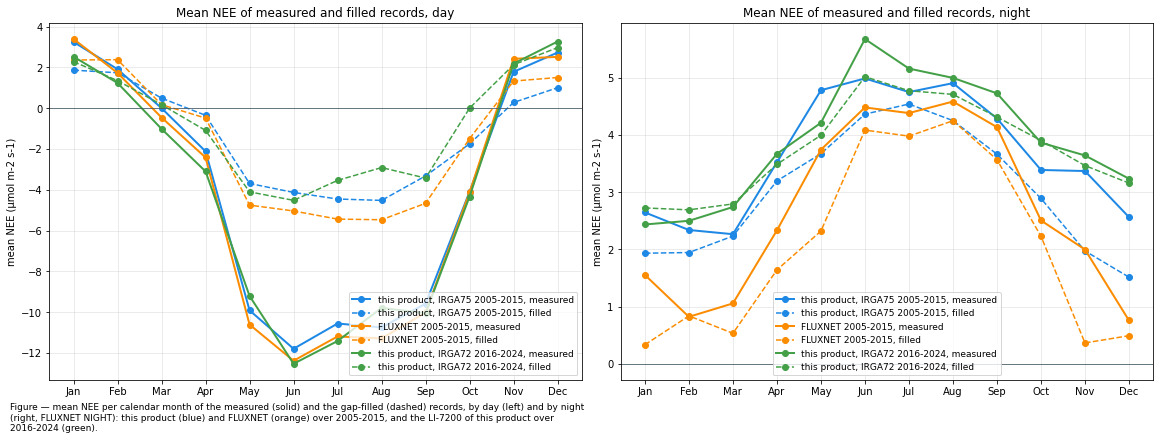

In [34]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6), dpi=72, layout="constrained")
for _ax, _fx_part in zip(axs, ('day', 'night')):
    for _fx_prod, _fx_c, _fx_lab in (('ours', COLORS['ours'], f"this product, IRGA75 {fx_MEAN_LABEL}"),
                                     ('FLUXNET', COLORS['FLUXNET'], f"FLUXNET {fx_MEAN_LABEL}"),
                                     (fx_REF72, COLORS['IRGA72'], f"this product, {fx_REF72}")):
        _ax.plot(range(1, 13), fx_levels[f"{_fx_part}, {_fx_prod}, measured"].to_numpy(), color=_fx_c,
                 marker='o', lw=2, label=f"{_fx_lab}, measured")
        _ax.plot(range(1, 13), fx_levels[f"{_fx_part}, {_fx_prod}, filled"].to_numpy(), color=_fx_c,
                 marker='o', lw=1.5, ls='--', label=f"{_fx_lab}, filled")
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.set_title(f"Mean NEE of measured and filled records, {_fx_part}")
    _ax.set_ylabel(f"mean NEE ({units})")
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9, loc='lower right' if _fx_part == 'day' else 'best')
    month_axis(_ax)
figcap(fig, f"mean NEE per calendar month of the measured (solid) and the gap-filled (dashed) records, by "
            f"day (left) and by night (right, FLUXNET NIGHT): this product (blue) and FLUXNET (orange) over "
            f"{fx_MEAN_LABEL}, and the LI-7200 of this product over {fx_IRGA72_REF[0]}-{fx_IRGA72_REF[1]} "
            f"(green).")
fig.show()

The two products diverge at night from October to April, and in most of these months the
divergence is larger in the filled nights than in the measured ones. The filled winter nights of
FLUXNET lie below its own measured winter nights in most months and below every other line, while
the filled and measured nights of this product and of the LI-7200 lie close together.

### 📋 Table: why the numbers diverge

Each cause is tied to the records on which it acts, so that its size can be read from the tables
of this part. The sizes are in the next table; they are mean annual amounts over 2005-2015 unless
stated, and the rows (a) to (e) and (g) add up to the annual difference. A cause that acts through
the gap-filling also enters classes other than its own, so the rows assign each record to one cause
and do not measure every indirect effect.

| Cause | Sign of ours minus FLUXNET | Where it acts | Evidence |
|:------|:---------------------------|:--------------|:---------|
| (a) Different self-heating corrections: opco in this product, the FP2021 correction in FLUXNET | Positive at night, negative by day in late autumn and winter | Class A: the shared measured records; at night all year, by day from October to January | On class A the correction of this product adds more at night than the correction implied in FLUXNET; by day the two are close from February to September and the FLUXNET correction is larger in late autumn and winter (table of the corrections per month below) |
| (b) Negative winter nights kept by FLUXNET and removed by this product | Positive | Class C removed by the quality and outlier tests of this product (Level 3.2); at night mostly from November to March, and to a smaller amount by day | The nights FLUXNET measured and this product removed have a negative mean in FLUXNET, and a large share of them is below zero: apparent nighttime uptake (supporting numbers below) |
| (c) Gap-filling of the nights: MDS in FLUXNET, XGBoost in this product | Positive | Class D at night, mostly from November to March | FLUXNET fills the winter nights far below its own measured winter nights, close to zero; MDS fills from records of similar conditions nearby in time and so from the low and negative measured winter nights. The filled nights of this product lie close to its measured nights and to the LI-7200 years |
| (d) Different USTAR filtering: variable thresholds (VUT) in FLUXNET, a constant threshold (CUT_50) in this product | Small and positive in 2005-2015 | Classes B and C of records whose USTAR lies between the two thresholds | The VUT thresholds lie below CUT_50 in most of the LI-7500 years, so FLUXNET keeps some low-turbulence nights that this product removes; the direct effect is small. A higher threshold raises the FLUXNET sums, as its own CUT scenario shows (table of the USTAR thresholds below) |
| (e) Gap-filling by day | Positive | Class D by day, mostly in spring and summer | This product fills the days with somewhat less uptake than FLUXNET in the growing season |
| (g) Other records measured in one product only | Positive | Class B (records FLUXNET filled above its USTAR threshold) and the remaining class C | Records this product keeps as measured and FLUXNET fills, through the quality filtering of FP2021 and ONEFlux; FLUXNET fills them with more uptake or less respiration |
| (f) 2016-2017: FLUXNET uses the LI-7200 and much higher USTAR thresholds | Negative at night, positive by day | Nights, mostly in summer and autumn: class B (nights this product keeps and FLUXNET fills) and class D; by day classes B and D | On class A the LI-7200 of this product and FLUXNET agree closely, so both start from the same flux. The VUT thresholds of these years are well above CUT_50 and above those of the LI-7500 years, with the same USTAR series; FLUXNET then keeps fewer nights and fills them higher (table of the parallel years below) |

### 📋 Table: size of each cause

In [35]:
_fx_r = fx_mean['reason']
_fx_causes = {
    '(a) self-heating corrections: class A': fx_mean['cls'] == 'A',
    '(b) negative winter nights: class C removed by the quality and outlier tests of this product':
        _fx_r == 'C, quality and outlier tests',
    '(c) gap-filling of the nights: class D, night': (fx_mean['cls'] == 'D') & fx_mean['night'],
    '(d) USTAR filtering: class C removed by the USTAR filter, class B below the FLUXNET threshold':
        _fx_r.isin(['C, USTAR filter', 'B, below the FLUXNET threshold']),
    '(e) gap-filling by day: class D, day': (fx_mean['cls'] == 'D') & ~fx_mean['night'],
    '(g) other records measured in one product only: class B and the rest of class C':
        _fx_r.isin(['B, other', 'C, no flux in this product', 'C, other']),
}
_fx_winter = fx_mean['month'].isin(fx_WINTER)
_fx_n = fx_mean['night']


def _fx_size(sel):
    return {'day': fx_mean.loc[sel & ~_fx_n, 'diff'].sum(), 'night': fx_mean.loc[sel & _fx_n, 'diff'].sum(),
            'overall': fx_mean.loc[sel, 'diff'].sum(),
            'Nov-Mar': fx_mean.loc[sel & _fx_winter, 'diff'].sum(),
            'Apr-Oct': fx_mean.loc[sel & ~_fx_winter, 'diff'].sum()}


fx_causes = pd.DataFrame({k: _fx_size(v) for k, v in _fx_causes.items()}).T * UMOL_TO_GC / fx_n_mean
_fx_all = pd.concat(_fx_causes.values(), axis=1)
assert (_fx_all.sum(axis=1) == 1).all(), "the causes do not partition the records"
fx_causes.loc['total, ours minus FLUXNET'] = fx_causes.sum()
assert np.isclose(fx_causes.loc['total, ours minus FLUXNET', 'overall'],
                  fx_annual.loc[f"mean {fx_MEAN_LABEL}", 'overall, difference'])
# (f): the LI-7200 of this product minus FLUXNET, mean of the parallel years.
_fx_f = {'day': fx_y72['day, difference'].mean(), 'night': fx_y72['night, difference'].mean(),
         'overall': fx_y72['overall, difference'].mean(),
         'Nov-Mar': fx_par.loc[fx_par['month'].isin(fx_WINTER), 'diff72'].sum() * UMOL_TO_GC / fx_n_par,
         'Apr-Oct': fx_par.loc[~fx_par['month'].isin(fx_WINTER), 'diff72'].sum() * UMOL_TO_GC / fx_n_par}
fx_causes.loc[f"(f) {PARALLEL_YEARS[0]}-{PARALLEL_YEARS[1]}: IRGA72 of this product minus FLUXNET"] = _fx_f
fx_causes.index.name = 'CAUSE'
display(styled(fx_causes, caption=f"approximate size of each cause in {units_sum} yr-1: the mean annual "
                                  f"difference ours minus FLUXNET over {fx_MEAN_LABEL} on the records each "
                                  f"cause acts on, by day, by night, over the whole day, and over November "
                                  f"to March and April to October. The rows (a) to (g) without (f) add up to "
                                  f"the total. Row (f) is the mean of {PARALLEL_YEARS[0]}-{PARALLEL_YEARS[1]} "
                                  f"with the LI-7200 of this product",
               subset=pd.IndexSlice[fx_causes.index.drop('total, ours minus FLUXNET'), :]))

Table — approximate size of each cause in gC m-2 yr-1: the mean annual difference ours minus FLUXNET
over 2005-2015 on the records each cause acts on, by day, by night, over the whole day, and over
November to March and April to October. The rows (a) to (g) without (f) add up to the total. Row (f)
is the mean of 2016-2017 with the LI-7200 of this product



,day,night,overall,Nov-Mar,Apr-Oct
CAUSE,,,,,
(a) self-heating corrections: class A,-13,25,12,4,8
(b) negative winter nights: class C removed by the quality and outlier tests of this product,16,23,39,20,18
"(c) gap-filling of the nights: class D, night",0,131,131,90,41
"(d) USTAR filtering: class C removed by the USTAR filter, class B below the FLUXNET threshold",-1,2,1,0,1
"(e) gap-filling by day: class D, day",10,0,10,-14,24
(g) other records measured in one product only: class B and the rest of class C,12,9,21,13,8
"total, ours minus FLUXNET",23,190,214,115,99
(f) 2016-2017: IRGA72 of this product minus FLUXNET,55,-202,-148,-6,-141


The gap-filling of the nights (c) is the largest cause in the LI-7500 years and acts mostly from
November to March. The records FLUXNET keeps and this product removes in its tests (b), the records
only this product measured (g), the gap-filling by day (e) and the different corrections on the
shared measured records (a) add smaller positive amounts. The USTAR filtering acts directly on few
records in these years (d). In 2016 and 2017 the difference has the other sign and arises at night
(f).

### 📋 Table: corrections on the shared measured records per month

In [36]:
_fx_a = fx_mean[fx_mean['cls'] == 'A']
fx_corr_month = _fx_a.groupby(['month', 'night'])[['opco', 'flx_implied', 'diff']].mean().unstack('night')
fx_corr_month.columns = flat([({'opco': 'correction, ours', 'flx_implied': 'correction, FLUXNET implied',
                                'diff': 'ours minus FLUXNET'}[a], b) for a, b in fx_corr_month.columns])
fx_corr_month = fx_corr_month[[f"{q}, {p}" for p in ('day', 'night') for q in
                               ('correction, ours', 'correction, FLUXNET implied', 'ours minus FLUXNET')]]
fx_corr_month.index = [calendar.month_abbr[m] for m in fx_corr_month.index]
fx_corr_month.index.name = 'MONTH'
display(styled(fx_corr_month, caption=f"class A, the records both products measured, {fx_MEAN_LABEL}: the mean "
                                      f"correction each product adds to the uncorrected LI-7500 flux and the "
                                      f"mean difference ours minus FLUXNET, per calendar month, by day and by "
                                      f"night, in {units}", fmt="{:.2f}"))

Table — class A, the records both products measured, 2005-2015: the mean correction each product
adds to the uncorrected LI-7500 flux and the mean difference ours minus FLUXNET, per calendar month,
by day and by night, in µmol m-2 s-1



,"correction, ours, day","correction, FLUXNET implied, day","ours minus FLUXNET, day","correction, ours, night","correction, FLUXNET implied, night","ours minus FLUXNET, night"
MONTH,,,,,,
Jan,2.96,3.74,-0.55,0.79,0.21,0.81
Feb,3.94,4.35,-0.22,1.24,0.21,1.24
Mar,3.68,3.84,-0.03,0.94,0.23,0.92
Apr,3.26,3.55,-0.17,0.86,0.36,0.68
May,2.87,3.02,-0.01,0.70,0.31,0.53
Jun,2.72,2.85,-0.01,0.66,0.42,0.42
Jul,2.40,2.48,0.13,0.51,0.43,0.28
Aug,2.52,2.64,0.15,0.57,0.45,0.67
Sep,2.77,2.96,-0.05,0.67,0.41,0.37


At night the correction of this product is larger than the correction implied in FLUXNET in every
month, and this product is higher by about the difference. By day the two corrections are close
from spring to early autumn; from October to January the FLUXNET correction is the larger one, and
FLUXNET is higher by day in these months. Over the year the two effects partly cancel on class A.

### 📋 Table: USTAR thresholds per year

In [37]:
_fx_cn = fx[fx['night']]
fx_ustar = pd.DataFrame({
    'FLUXNET VUT threshold (m s-1)': fx_ustar_vut.reindex(range(FIRST_YEAR, LAST_YEAR + 1)),
    'nights measured, ours (%)': _fx_cn.groupby('year')['ours_meas'].mean() * 100,
    'nights measured, FLUXNET (%)': _fx_cn.groupby('year')['flx_meas'].mean() * 100,
    f'night, ours minus FLUXNET ({units_sum})': fx_y75['night, difference'],
    f'FLUXNET CUT minus VUT, year ({units_sum})': (fx['flx_cut'] - fx['flx']).groupby(fx['year']).sum()
                                                  * UMOL_TO_GC,
})
fx_ustar.index.name = 'YEAR'
display(styled(fx_ustar, caption=f"USTAR thresholds and their effect per year: the threshold of the FLUXNET "
                                 f"reference NEE_VUT_REF; the share of the nights each product keeps as "
                                 f"measured; the nighttime difference ours minus FLUXNET (LI-7500 of this "
                                 f"product); and the annual sum of the FLUXNET reference with one constant "
                                 f"threshold for all years ({fx_FLX_CUT}, {fx_ustar_cut:.3f} m s-1) minus "
                                 f"that of NEE_VUT_REF. The threshold of this product is CUT_50, "
                                 f"{USTAR_CUT_50} m s-1, in every year",
               fmt={'FLUXNET VUT threshold (m s-1)': "{:.3f}", 'nights measured, ours (%)': "{:.0f}",
                    'nights measured, FLUXNET (%)': "{:.0f}", f'night, ours minus FLUXNET ({units_sum})': "{:.0f}",
                    f'FLUXNET CUT minus VUT, year ({units_sum})': "{:.0f}"},
               subset=[f'FLUXNET CUT minus VUT, year ({units_sum})'], cmap='RdBu_r', center=True))

Table — USTAR thresholds and their effect per year: the threshold of the FLUXNET reference
NEE_VUT_REF; the share of the nights each product keeps as measured; the nighttime difference ours
minus FLUXNET (LI-7500 of this product); and the annual sum of the FLUXNET reference with one
constant threshold for all years (NEE_CUT_REF, 0.430 m s-1) minus that of NEE_VUT_REF. The threshold
of this product is CUT_50, 0.304 m s-1, in every year



,FLUXNET VUT threshold (m s-1),"nights measured, ours (%)","nights measured, FLUXNET (%)","night, ours minus FLUXNET (gC m-2)","FLUXNET CUT minus VUT, year (gC m-2)"
YEAR,,,,,
2004,0.282,28,24,218,-46
2005,0.259,26,24,140,218
2006,0.322,30,22,191,75
2007,0.299,32,25,152,102
2008,0.287,32,26,146,-8
2009,0.268,29,24,221,43
2010,0.231,28,26,197,-6
2011,0.244,29,26,141,23
2012,0.257,25,22,236,187


In most of the LI-7500 years the FLUXNET threshold lies below that of this product, yet FLUXNET
keeps fewer nights as measured in every year: its other quality filters remove more nights than its
lower threshold adds. The FLUXNET scenario with one constant threshold, higher than every VUT
threshold of the LI-7500 years, has less uptake in most of these years, in some years by an amount
close to the nighttime difference between the two products; the FLUXNET sums thus depend strongly
on the choice of threshold. In 2016 and 2017 the FLUXNET threshold is much higher than in the
LI-7500 years and than that of this product, and FLUXNET keeps its smallest shares of measured
nights.

### 📋 Table: the parallel years by record class

In [38]:
_fx_pp = {}
for _fx_part in ('day', 'night'):
    _fx_t = (fx_select(fx_par, _fx_part).groupby(['cls72', 'year'])['diff72'].sum().unstack('year')
             * UMOL_TO_GC)
    for _fx_y in _fx_t.columns:
        _fx_pp[f"{_fx_y}, {_fx_part}"] = _fx_t[_fx_y].reindex(list(CLASSES))
for _fx_y in range(PARALLEL_YEARS[0], PARALLEL_YEARS[1] + 1):
    _fx_sel = fx_par[(fx_par['year'] == _fx_y) & fx_par['night']]
    _fx_pp[f"{_fx_y}, night records (%)"] = _fx_sel['cls72'].value_counts(normalize=True).reindex(list(CLASSES)) * 100
fx_parallel_cls = pd.DataFrame(_fx_pp)
fx_parallel_cls = fx_parallel_cls[sorted(fx_parallel_cls.columns)]
fx_parallel_cls.index = [f"{k} {v}" for k, v in CLASSES.items()]
fx_parallel_cls.loc['total'] = fx_parallel_cls.sum()
fx_parallel_cls.index.name = 'CLASS'
_fx_val = [col for col in fx_parallel_cls.columns if '%' not in col]
_fx_fmt = {col: "{:.0f}" for col in fx_parallel_cls.columns}
display(styled(fx_parallel_cls, caption=f"the parallel years: difference between the LI-7200 of this product "
                                        f"and FLUXNET in {units_sum} per record class, by day and by night, with "
                                        f"the share of the nights in each class. The classes are formed with "
                                        f"the fill flag of the LI-7200 of this product",
               fmt=_fx_fmt, subset=pd.IndexSlice[fx_parallel_cls.index[:-1], _fx_val]))

Table — the parallel years: difference between the LI-7200 of this product and FLUXNET in gC m-2 per
record class, by day and by night, with the share of the nights in each class. The classes are
formed with the fill flag of the LI-7200 of this product



,"2016, day","2016, night","2016, night records (%)","2017, day","2017, night","2017, night records (%)"
CLASS,,,,,,
A both measured,5,-0,13,5,-1,14
B ours measured only,29,-58,16,54,-92,25
C FLUXNET measured only,-20,4,5,-7,-9,1
D both filled,19,-58,65,23,-191,60
total,34,-112,100,75,-293,100


In the parallel years class A of the LI-7200 is close to zero by day and by night. The negative
difference comes from the nights this product measured and FLUXNET filled (class B) and from the
nights both filled (class D): FLUXNET fills its nights with more respiration than this product
measures or fills. By day the same two classes are positive: FLUXNET fills the days with more
uptake.

### Supporting numbers per cause

In [39]:
def _fx_gc(s):
    return s.sum() * UMOL_TO_GC / fx_n_mean


_fx_m = fx_mean
_fx_n = _fx_m['night']
_fx_win = _fx_m['month'].isin(fx_WINTER)
_fx_lines = []

# (a) The correction difference of class A, applied to every record by month and day/night, as an
# upper bound: a gap-filled value is learned from corrected measured values.
_fx_a = _fx_m[_fx_m['cls'] == 'A']
_fx_clim = (_fx_a['opco'] - _fx_a['flx_implied']).groupby([_fx_a['month'], _fx_a['night']]).mean()
_fx_prop = pd.Series(_fx_clim.reindex(pd.MultiIndex.from_arrays([_fx_m['month'], _fx_n])).to_numpy(),
                     index=_fx_m.index)
_fx_lines.append(f"(a) class A, ours minus FLUXNET: day {_fx_gc(_fx_a.loc[~_fx_a['night'], 'diff']):+.0f}, "
                 f"night {_fx_gc(_fx_a.loc[_fx_a['night'], 'diff']):+.0f} {units_sum} yr-1. The correction "
                 f"difference of class A applied to every record: day {_fx_gc(_fx_prop[~_fx_n]):+.0f}, night "
                 f"{_fx_gc(_fx_prop[_fx_n]):+.0f}, overall {_fx_gc(_fx_prop):+.0f} {units_sum} yr-1")

# (b) The nights FLUXNET measured and the quality and outlier tests of this product removed.
_fx_b = _fx_m[(_fx_m['reason'] == 'C, quality and outlier tests') & _fx_n]
_fx_lines.append(f"(b) class-C nights removed by the tests of this product: {len(_fx_b) / fx_n_mean:.0f} "
                 f"per year ({len(_fx_b) / _fx_n.sum() * 100:.1f} % of the nights); FLUXNET mean "
                 f"{_fx_b['flx'].mean():.2f} {units}, below zero in {(_fx_b['flx'] < 0).mean() * 100:.0f} %; "
                 f"filled by this product at a mean of {_fx_b['ours'].mean():.2f} {units}; "
                 f"{_fx_gc(_fx_b['diff']):+.0f} {units_sum} yr-1, of which "
                 f"{_fx_gc(_fx_b.loc[_fx_b['month'].isin(fx_WINTER), 'diff']):+.0f} in November to March")
_fx_bu = _fx_m[(_fx_m['reason'] == 'C, USTAR filter') & _fx_n]
_fx_lines.append(f"    for comparison, class-C nights removed by the USTAR filter of this product: FLUXNET "
                 f"mean {_fx_bu['flx'].mean():.2f} {units}, {_fx_gc(_fx_bu['diff']):+.0f} {units_sum} yr-1")

# (c) The nights both products fill.
_fx_d = _fx_m[(_fx_m['cls'] == 'D') & _fx_n]
_fx_dw = _fx_d[_fx_d['month'].isin(fx_WINTER)]
_fx_72w = fx72[fx72['night_flx'] & fx72['month'].isin(fx_WINTER)]
_fx_lines.append(f"(c) class-D nights: {_fx_gc(_fx_d['diff']):+.0f} {units_sum} yr-1, of which "
                 f"{_fx_gc(_fx_dw['diff']):+.0f} in November to March. Mean of the filled nights of November "
                 f"to March: ours {_fx_dw['ours'].mean():.2f}, FLUXNET {_fx_dw['flx'].mean():.2f} {units}; "
                 f"measured nights of the same months: ours "
                 f"{_fx_m.loc[_fx_n & _fx_win & _fx_m['ours_meas'], 'ours'].mean():.2f}, FLUXNET "
                 f"{_fx_m.loc[_fx_n & _fx_win & _fx_m['flx_meas'], 'flx'].mean():.2f}, {fx_REF72} "
                 f"{_fx_72w.loc[_fx_72w['meas'], varname].mean():.2f} {units}")

# (d) The USTAR thresholds.
_fx_v = fx_ustar_vut.loc[fx_MEAN_YEARS[0]:fx_MEAN_YEARS[1]]
_fx_dd = _fx_m[_fx_m['reason'].isin(['C, USTAR filter', 'B, below the FLUXNET threshold'])]
_fx_lines.append(f"(d) FLUXNET VUT threshold {fx_MEAN_LABEL}: mean {_fx_v.mean():.3f} m s-1, above CUT_50 "
                 f"({USTAR_CUT_50}) in {', '.join(str(y) for y in _fx_v.index[_fx_v > USTAR_CUT_50]) or 'no year'}. "
                 f"Records between the thresholds: {_fx_gc(_fx_dd['diff']):+.0f} {units_sum} yr-1. FLUXNET "
                 f"{fx_FLX_CUT} ({fx_ustar_cut:.3f} m s-1) minus NEE_VUT_REF: mean "
                 f"{fx_ustar.loc[fx_MEAN_YEARS[0]:fx_MEAN_YEARS[1], f'FLUXNET CUT minus VUT, year ({units_sum})'].mean():+.0f} "
                 f"{units_sum} yr-1")

# (e) The days both products fill.
_fx_e = _fx_m[(_fx_m['cls'] == 'D') & ~_fx_n]
_fx_lines.append(f"(e) class-D days: {_fx_gc(_fx_e['diff']):+.0f} {units_sum} yr-1, of which "
                 f"{_fx_gc(_fx_e.loc[_fx_e['month'].between(4, 9), 'diff']):+.0f} in April to September; mean "
                 f"filled day April to September: ours {_fx_e.loc[_fx_e['month'].between(4, 9), 'ours'].mean():.2f}, "
                 f"FLUXNET {_fx_e.loc[_fx_e['month'].between(4, 9), 'flx'].mean():.2f} {units}")

# (g) The records only one product measured, for other reasons.
_fx_g = _fx_m[_fx_m['reason'] == 'B, other']
_fx_lines.append(f"(g) class B above the FLUXNET threshold: {len(_fx_g) / fx_n_mean:.0f} records per year, "
                 f"{_fx_gc(_fx_g.loc[~_fx_g['night'], 'diff']):+.0f} by day and "
                 f"{_fx_gc(_fx_g.loc[_fx_g['night'], 'diff']):+.0f} at night {units_sum} yr-1")

# (f) The parallel years.
_fx_pn = fx_par[fx_par['night']]
_fx_lines.append(f"(f) {PARALLEL_YEARS[0]}-{PARALLEL_YEARS[1]}: VUT threshold "
                 f"{', '.join(f'{y} {fx_ustar_vut[y]:.3f}' for y in range(PARALLEL_YEARS[0], PARALLEL_YEARS[1] + 1))} "
                 f"m s-1; IRGA72 minus FLUXNET at night {fx_y72['night, difference'].mean():+.0f} {units_sum} yr-1, "
                 f"of which class B {_fx_pn.loc[_fx_pn['cls72'] == 'B', 'diff72'].sum() * UMOL_TO_GC / fx_n_par:+.0f} "
                 f"and class D {_fx_pn.loc[_fx_pn['cls72'] == 'D', 'diff72'].sum() * UMOL_TO_GC / fx_n_par:+.0f}; "
                 f"class A at night, mean IRGA72 {_fx_pn.loc[_fx_pn['cls72'] == 'A', 'ours72'].mean():.2f} and "
                 f"FLUXNET {_fx_pn.loc[_fx_pn['cls72'] == 'A', 'flx'].mean():.2f} {units}; all nights, mean "
                 f"IRGA72 {_fx_pn['ours72'].mean():.2f} and FLUXNET {_fx_pn['flx'].mean():.2f} {units}")
print("\n".join(textwrap.fill(line, 110, subsequent_indent="    ") for line in _fx_lines))

(a) class A, ours minus FLUXNET: day -13, night +25 gC m-2 yr-1. The correction difference of class A applied
    to every record: day -85, night +85, overall -0 gC m-2 yr-1
(b) class-C nights removed by the tests of this product: 213 per year (2.5 % of the nights); FLUXNET mean
    -2.84 µmol m-2 s-1, below zero in 50 %; filled by this product at a mean of 2.15 µmol m-2 s-1; +23 gC m-2
    yr-1, of which +15 in November to March
    for comparison, class-C nights removed by the USTAR filter of this product: FLUXNET mean 0.92 µmol m-2
    s-1, +3 gC m-2 yr-1
(c) class-D nights: +131 gC m-2 yr-1, of which +90 in November to March. Mean of the filled nights of November
    to March: ours 1.91, FLUXNET 0.44 µmol m-2 s-1; measured nights of the same months: ours 2.63, FLUXNET
    1.22, IRGA72 2016-2024 2.93 µmol m-2 s-1
(d) FLUXNET VUT threshold 2005-2015: mean 0.278 m s-1, above CUT_50 (0.304) in 2006, 2015. Records between the
    thresholds: +1 gC m-2 yr-1. FLUXNET NEE_CUT_REF (0.430 m 

### Interpretation

- **Measured records by day.** The two products agree closely on the days both measured, except in
  late autumn and winter, when the correction implied in FLUXNET is larger. Neither product is
  clearly more plausible here; the effect on the annual sum is small.
- **Measured records at night.** On the nights both measured, opco adds more than the correction
  implied in FLUXNET. Whether opco is too large at night cannot be decided on these records alone;
  the winter nights of the LI-7200 years, which need no correction, are close to this product.
- **Measured winter nights FLUXNET keeps.** The nights that FLUXNET keeps and this product removes
  are negative on average in FLUXNET. Without light there is no photosynthesis, so a negative
  nighttime `NEE` is not a biological signal of the forest; apparent uptake in cold conditions is
  the known signature of an open-path analyser whose self-heating is not fully corrected. Removing
  these nights, as this product does, is the more plausible choice.
- **Gap-filled nights.** FLUXNET fills the winter nights close to zero, far below its own measured
  winter nights, below this product and below the LI-7200 years. A winter respiration that low is
  implausible for this forest. The filled nights of this product agree with its measured nights and
  with the LI-7200. This is the largest single cause of the difference.
- **USTAR filtering.** In the LI-7500 years the two thresholds are close and act directly on few
  records; the FLUXNET sums nevertheless change markedly with its own choice of threshold.
- **Gap-filled days.** This product fills the summer days with somewhat less uptake than FLUXNET.
  The measured days of the two products agree, so the difference lies in the gap-filling models;
  neither is shown here to be the more plausible.
- **Summer.** From June to September the two products agree closely, by day and by night.
- **2016 and 2017.** FLUXNET and the LI-7200 of this product start from the same flux. FLUXNET shows
  less uptake over the year because it applies a much higher USTAR threshold and fills more nights,
  with higher values; by day it fills with more uptake. Which threshold suits the LI-7200 years
  better is not decided here.

In 2004-2015 the lower annual sums of FLUXNET therefore come from an implausibly low winter
respiration, in its measured and above all in its gap-filled nights, while summer agrees.

</br>

# Comparison with Etzold et al. (2011)

Etzold et al. (2011) report the `NEE` of 2005-2009 from the same LI-7500. Their processing differs
from this product in several steps. The one with the largest effect on the annual sum is the
self-heating correction, which is recomputed here for the flux of this product.

## 📋 Table: processing compared

In [40]:
_e9 = d.loc[str(ETZOLD_YEARS[0]):str(ETZOLD_YEARS[1])].copy()
_meas_night = _e9.loc[_e9['night'], 'ours_meas'].mean() * 100
_meas_night_flx = _e9.loc[_e9['night'], 'flx_meas'].mean() * 100
_prod = dict(PRODUCT_METHODS)
_prod['measured nights (%)'] = f"{_meas_night:.0f} (FLUXNET: {_meas_night_flx:.0f})"
methods = pd.DataFrame({'Etzold et al. 2011 (p. 1297)': ETZOLD_METHODS, 'this product': _prod})
methods.index.name = 'step'
display(styled(methods, caption=f"processing of Etzold et al. 2011 and of this product. The measured share "
                                f"of the nights of this product is computed here for "
                                f"{ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]} with the FLUXNET night flag",
               cmap=None))

Table — processing of Etzold et al. 2011 and of this product. The measured share of the nights of
this product is computed here for 2005-2009 with the FLUXNET night flag



,Etzold et al. 2011 (p. 1297),this product
step,,
density correction,WPL,"WPL, in EddyPro (Level 1)"
self-heating correction,"Burba et al. (2008), with the surface temperatures and fraction of Järvi et al. (2009)",opco: heating and WPL thermal terms with coefficients fitted to the LI-7200 in 2016-2017 (Level 1.1)
large winter fluxes (±15 µmol m-2 s-1),"kept in the data, excluded from the gap-filling fits",absolute limits ±50 µmol m-2 s-1 and outlier tests (Level 3.2)
negative nighttime values,"removed, together with as many positive ones (trimmed)",removed where clearly below zero: single records and whole nights (Level 3.2)
gap-filling,"light response by day, Lloyd-Taylor at night, running mean below 0 °C",XGBoost (Level 4.1)
USTAR threshold (m s-1),0.3,"0.304 (CUT_50, constant)"
measured nights (%),24,30 (FLUXNET: 24)


## The two self-heating corrections

The correction of Burba et al. (2008) adds a heat-flux term computed from the instrument surface
temperature, the CO2 density and the aerodynamic resistance; Järvi et al. (2009) scale it by a fixed
fraction (0.085) and estimate the surface temperature from air temperature. It is computed here from
the input of the flux chain with the equation of *Helpers*, the sonic temperature standing in for air
temperature. opco is the correction of this product (Level 1.1).

### 📋 Table: distribution of the corrections per half-hour

In [41]:
_dist = {}
for _col, _lab in (('opco', 'opco (this product)'), ('burba', 'Burba et al. 2008 / Järvi et al. 2009')):
    _s = _e9[_col].dropna()
    _dist[_lab] = {'records': len(_s), 'mean': _s.mean(), 'median': _s.median(),
                   'P01': _s.quantile(0.01), 'P99': _s.quantile(0.99),
                   'above 5 (%)': (_s > 5).mean() * 100}
corr_dist = pd.DataFrame(_dist).T
display(styled(corr_dist, caption=f"the two corrections on every half-hour with an uncorrected flux, "
                                  f"{ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}, in {units}: mean, median, 1st and "
                                  f"99th percentile, and the share above 5 {units}",
               fmt={'records': "{:,.0f}", 'mean': "{:.2f}", 'median': "{:.2f}", 'P01': "{:.2f}",
                    'P99': "{:.2f}", 'above 5 (%)': "{:.2f}"}, cmap=None))

Table — the two corrections on every half-hour with an uncorrected flux, 2005-2009, in µmol m-2 s-1:
mean, median, 1st and 99th percentile, and the share above 5 µmol m-2 s-1



,records,mean,median,P01,P99,above 5 (%)
opco (this product),"74,645",1.68,1.02,-3.06,9.73,6.61
Burba et al. 2008 / Järvi et al. 2009,"81,503",0.80,0.54,0.02,4.51,0.85


The correction of Burba et al. (2008) has a long upper tail: a few half-hours with a large USTAR
relative to the wind speed get a large correction. Its mean per month is therefore larger than its
median, and the median is used below to apply it to every half-hour; the mean is shown as a
sensitivity.

### 📋 Table: correction per month, day and night

In [42]:
_mo9 = _e9.index.month
corr_month = pd.concat({
    'opco, mean': _e9.groupby([_mo9, 'night'])['opco'].mean().unstack('night'),
    'Burba, mean': _e9.groupby([_mo9, 'night'])['burba'].mean().unstack('night'),
    'Burba, median': _e9.groupby([_mo9, 'night'])['burba'].median().unstack('night'),
}, axis=1)
corr_month.columns = flat(corr_month.columns)
corr_month.index = [calendar.month_abbr[m] for m in corr_month.index]
corr_month.index.name = 'MONTH'
display(styled(corr_month, caption=f"the correction each method adds per half-hour, by calendar month and "
                                   f"by day and night, {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}, in {units}. "
                                   f"Burba: the correction of Burba et al. 2008 with the fraction of Järvi "
                                   f"et al. 2009", fmt="{:.2f}", cmap='Reds', center=False))

Table — the correction each method adds per half-hour, by calendar month and by day and night,
2005-2009, in µmol m-2 s-1. Burba: the correction of Burba et al. 2008 with the fraction of Järvi et
al. 2009



,"opco, mean, day","opco, mean, night","Burba, mean, day","Burba, mean, night","Burba, median, day","Burba, median, night"
MONTH,,,,,,
Jan,3.52,1.08,1.18,0.93,0.83,0.56
Feb,3.86,1.04,1.06,0.84,0.81,0.52
Mar,3.04,0.73,1.05,0.78,0.88,0.55
Apr,2.81,0.51,0.99,0.56,0.71,0.35
May,2.30,0.44,0.87,0.49,0.66,0.33
Jun,2.19,0.40,0.81,0.46,0.63,0.29
Jul,1.95,0.35,0.81,0.42,0.63,0.25
Aug,2.06,0.36,0.73,0.41,0.55,0.24
Sep,2.29,0.41,0.77,0.49,0.57,0.28


### 📊 Plot: correction per month, day and night

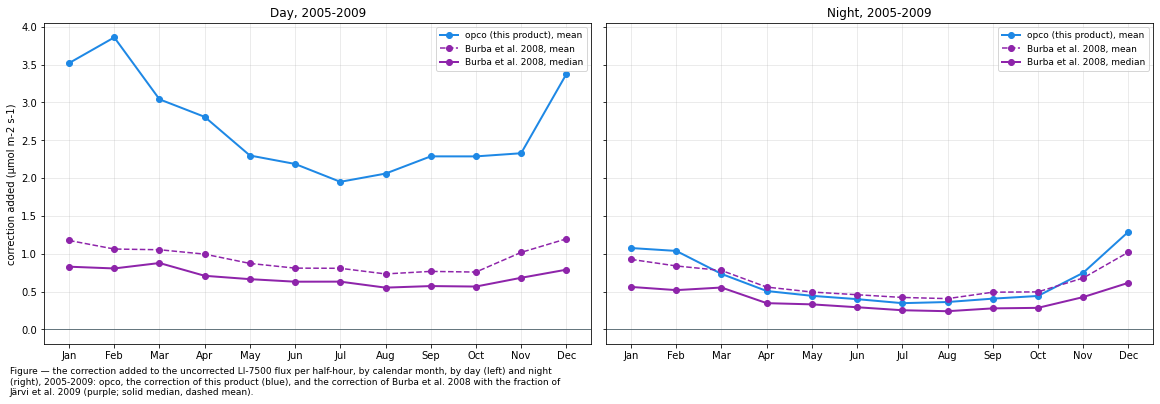

In [43]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), dpi=72, layout="constrained", sharey=True)
_m = range(1, 13)
for _ax, _tod in zip(axs, ('day', 'night')):
    _ax.plot(_m, corr_month[f"opco, mean, {_tod}"].to_numpy(), color=COLORS['ours'], marker='o', lw=2,
             label="opco (this product), mean")
    _ax.plot(_m, corr_month[f"Burba, mean, {_tod}"].to_numpy(), color=COLORS['burba'], marker='o', lw=1.5,
             ls='--', label="Burba et al. 2008, mean")
    _ax.plot(_m, corr_month[f"Burba, median, {_tod}"].to_numpy(), color=COLORS['burba'], marker='o',
             lw=2, label="Burba et al. 2008, median")
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.set_title(f"{_tod.capitalize()}, {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}")
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
    month_axis(_ax)
axs[0].set_ylabel(f"correction added ({units})")
figcap(fig, f"the correction added to the uncorrected LI-7500 flux per half-hour, by calendar month, by "
            f"day (left) and night (right), {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}: opco, the correction "
            f"of this product (blue), and the correction of Burba et al. 2008 with the fraction of "
            f"Järvi et al. 2009 (purple; solid median, dashed mean).")
fig.show()

By day opco adds several times as much as the correction of Burba et al. (2008), in every month.
At night the two are closer: from April to October the mean of the correction of Burba et al.
(2008) is about as large as opco and its median is smaller; in winter opco is the larger of the
two.

## Monthly and seasonal NEE, 2005-2009

To compare with Etzold et al. (2011), the flux of this product is shown in four versions: as
published (*ours*, with opco); without opco; and with the correction of Burba et al. (2008) in place
of opco, with its median or its mean per month. A gap-filled value is learned from corrected
measured values and carries the correction as well, so both corrections are removed or added on
every half-hour, as the mean (opco) or median (Burba) of each calendar month by day and by night.

### 📋 Table: mean monthly NEE

In [44]:
_e9['opco_clim'] = month_night_climatology(_e9, 'opco', 'mean')
_e9['burba_clim'] = month_night_climatology(_e9, 'burba', 'median')
_e9['burba_clim_mean'] = month_night_climatology(_e9, 'burba', 'mean')
_e9['ours_noopco'] = _e9['ours'] - _e9['opco_clim']
_e9['ours_burba'] = _e9['ours_noopco'] + _e9['burba_clim']
_e9['ours_burba_mean'] = _e9['ours_noopco'] + _e9['burba_clim_mean']

LINES = {
    'Etzold et al. 2011 (Fig. 5)': 'Etzold et al. 2011, Fig. 5, read by eye',
    'ours': 'this product, IRGA75, with opco',
    'ours without opco': 'this product, IRGA75, without opco',
    'ours with Burba': 'this product, IRGA75, with the correction of Burba et al. 2008 (median)',
    'ours with Burba (mean)': 'this product, IRGA75, with the correction of Burba et al. 2008 (mean)',
    'FLUXNET': 'FLUXNET NEE_VUT_REF',
    f'IRGA72 {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}': 'this product, IRGA72',
}
monthly = pd.DataFrame({
    'Etzold et al. 2011 (Fig. 5)': pd.Series(ETZOLD_FIG5, dtype=float),
    'ours': mean_monthly_sums(_e9['ours']),
    'ours without opco': mean_monthly_sums(_e9['ours_noopco']),
    'ours with Burba': mean_monthly_sums(_e9['ours_burba']),
    'ours with Burba (mean)': mean_monthly_sums(_e9['ours_burba_mean']),
    'FLUXNET': mean_monthly_sums(_e9['flx']),
    f'IRGA72 {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}': mean_monthly_sums(r72[varname]),
    'opco added': mean_monthly_sums(_e9['opco_clim']),
    'Burba added': mean_monthly_sums(_e9['burba_clim']),
}).sort_index()
_show = monthly.copy()
_show.index = [calendar.month_abbr[m] for m in _show.index]
_show.loc['year'] = monthly.sum()
_show.index.name = 'MONTH'
display(styled(_show, caption=f"mean monthly NEE in {units_sum}, {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]} unless "
                              f"stated: Etzold et al. 2011 read from their Fig. 5 (±{ETZOLD_FIG5_ACCURACY} "
                              f"{units_sum}, least certain in November to March); this product with opco, "
                              f"without it, and with the correction of Burba et al. 2008 in its place; "
                              f"FLUXNET; the LI-7200 of this product over {IRGA72_YEARS[0]}-"
                              f"{IRGA72_YEARS[1]}. The last two columns are the monthly sums of the two "
                              f"corrections as applied. The Fig. 5 values sum to "
                              f"{sum(ETZOLD_FIG5.values())} against the published {ETZOLD_MEAN}",
               subset=[col for col in _show.columns if 'added' not in col]))

Table — mean monthly NEE in gC m-2, 2005-2009 unless stated: Etzold et al. 2011 read from their Fig.
5 (±3 gC m-2, least certain in November to March); this product with opco, without it, and with the
correction of Burba et al. 2008 in its place; FLUXNET; the LI-7200 of this product over 2016-2025.
The last two columns are the monthly sums of the two corrections as applied. The Fig. 5 values sum
to -417.5 against the published -415



,Etzold et al. 2011 (Fig. 5),ours,ours without opco,ours with Burba,ours with Burba (mean),FLUXNET,IRGA72 2016-2025,opco added,Burba added
MONTH,,,,,,,,,
Jan,39,83,18,40,51,65,80,65,21
Feb,33,62,-4,15,23,49,59,67,19
Mar,17,44,-17,6,12,10,37,61,23
Apr,-5,30,-27,-10,-2,-2,5,57,17
May,-111,-83,-135,-118,-112,-97,-103,53,18
Jun,-157,-111,-161,-145,-139,-112,-145,50,16
Jul,-138,-93,-138,-122,-116,-103,-131,45,16
Aug,-106,-78,-123,-109,-103,-71,-81,45,14
Sep,-62,-44,-88,-74,-68,-39,-59,44,14


### 📋 Table: seasonal sums

In [45]:
seasons = season_sums(monthly)
seasons.loc['Etzold et al. 2011 (published)'] = [np.nan] * len(SEASONS) + [ETZOLD_MEAN]
seasons = seasons.loc[[*list(LINES)[:1], 'Etzold et al. 2011 (published)', *list(LINES)[1:],
                       'opco added', 'Burba added']]
display(styled(seasons, caption=f"mean NEE per season in {units_sum}, sums of the monthly means of the table "
                                f"above, {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]} unless stated. The published "
                                f"annual mean of Etzold et al. 2011 is {ETZOLD_MEAN} (range "
                                f"{ETZOLD_RANGE[0]} to {ETZOLD_RANGE[1]}). The rows without and with the "
                                f"other correction are approximations",
               subset=pd.IndexSlice[seasons.index[:-2], :]))

Table — mean NEE per season in gC m-2, sums of the monthly means of the table above, 2005-2009
unless stated. The published annual mean of Etzold et al. 2011 is -415 (range -662 to -366). The
rows without and with the other correction are approximations



,Nov-Mar,Apr+Oct,May-Sep,year
Etzold et al. 2011 (Fig. 5),156,0,-574,-418
Etzold et al. 2011 (published),-,-,-,-415
ours,310,61,-408,-38
ours without opco,7,-38,-645,-675
ours with Burba,109,-8,-567,-466
ours with Burba (mean),158,7,-538,-374
FLUXNET,183,19,-423,-221
IRGA72 2016-2025,366,36,-519,-117
opco added,302,99,236,638
Burba added,102,31,77,210


The flux of this product with the correction of Burba et al. (2008) in place of opco comes close to
the values Etzold et al. (2011) report, in the year and in each season. The remaining difference is
of the size of the reading accuracy of their figure and of the other processing steps. In winter
(November to March) the LI-7200 years agree with the opco-corrected flux and not with the smaller
correction. In summer (May to September) they lie between the two in the run shown. With the
monthly mean of the correction of Burba et al. (2008) in place of its median the flux shows less
uptake, so the result depends on how the long upper tail of that correction is treated.

### 📋 Table: annual NEE 2005-2009

In [46]:
_yr9 = pd.DataFrame({
    'ours': per_year(_e9['ours']),
    'ours without opco': per_year(_e9['ours_noopco']),
    'ours with Burba': per_year(_e9['ours_burba']),
    'FLUXNET': per_year(_e9['flx']),
})
years9 = pd.DataFrame({'mean': _yr9.mean(), 'most negative': _yr9.min(), 'least negative': _yr9.max()})
years9.loc['Etzold et al. 2011 (published)'] = [ETZOLD_MEAN, *ETZOLD_RANGE]
display(styled(years9, caption=f"annual NEE {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]} in {units_sum}: the mean of "
                               f"the five years and the most and least negative year. The correction "
                               f"climatology is the same in every year, so the spread of the rows without "
                               f"and with the other correction is that of the flux of this product"))

Table — annual NEE 2005-2009 in gC m-2: the mean of the five years and the most and least negative
year. The correction climatology is the same in every year, so the spread of the rows without and
with the other correction is that of the flux of this product



,mean,most negative,least negative
ours,-38,-180,62
ours without opco,-675,-817,-575
ours with Burba,-466,-608,-365
FLUXNET,-221,-352,-124
Etzold et al. 2011 (published),-415,-662,-366


### 📊 Plot: mean monthly NEE

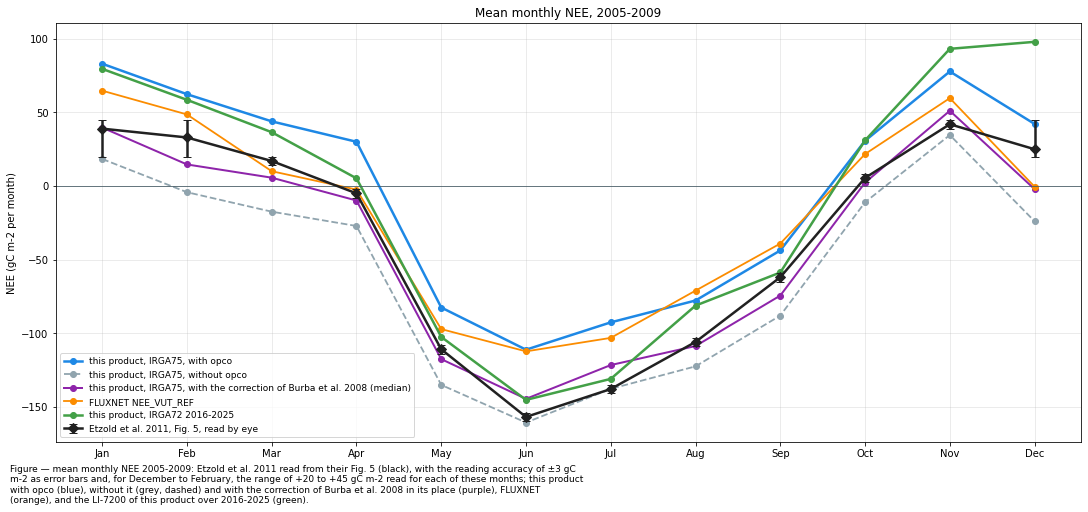

In [47]:
fig, ax = plt.subplots(figsize=(15, 7), dpi=72, layout="constrained")
_m = range(1, 13)
_fig5 = monthly['Etzold et al. 2011 (Fig. 5)']
# Error bars: the reading accuracy, and for the five winter months the range read from the figure.
_lo = pd.Series(float(ETZOLD_FIG5_ACCURACY), index=_fig5.index)
_hi = _lo.copy()
_lo[ETZOLD_FIG5_LEAST_CERTAIN] = _fig5[ETZOLD_FIG5_LEAST_CERTAIN] - ETZOLD_FIG5_WINTER_RANGE[0]
_hi[ETZOLD_FIG5_LEAST_CERTAIN] = ETZOLD_FIG5_WINTER_RANGE[1] - _fig5[ETZOLD_FIG5_LEAST_CERTAIN]
ax.errorbar(_m, _fig5, yerr=[_lo.to_numpy(), _hi.to_numpy()], color=COLORS['study2011'], marker='D',
            ms=7, lw=2.5, capsize=4, label=LINES['Etzold et al. 2011 (Fig. 5)'], zorder=5)
for _col, _c, _ls, _lw in (('ours', COLORS['ours'], '-', 2.5),
                           ('ours without opco', COLORS['noopco'], '--', 1.8),
                           ('ours with Burba', COLORS['burba'], '-', 2.0),
                           ('FLUXNET', COLORS['FLUXNET'], '-', 1.8),
                           (f'IRGA72 {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}', COLORS['IRGA72'], '-', 2.5)):
    _lab = LINES[_col] + (f" {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}" if _col.startswith('IRGA72') else "")
    ax.plot(_m, monthly[_col], color=_c, ls=_ls, lw=_lw, marker='o', label=_lab)
ax.axhline(0, color='#455A64', lw=0.8)
ax.set_ylabel(f"NEE ({units_sum} per month)")
ax.set_title(f"Mean monthly NEE, {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc='lower left')
month_axis(ax)
figcap(fig, f"mean monthly NEE {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}: Etzold et al. 2011 read from their "
            f"Fig. 5 (black), with the reading accuracy of ±{ETZOLD_FIG5_ACCURACY} {units_sum} as error "
            f"bars and, for December to February, the range of +{ETZOLD_FIG5_WINTER_RANGE[0]} to "
            f"+{ETZOLD_FIG5_WINTER_RANGE[1]} {units_sum} read for each of these months; this product with opco (blue), "
            f"without it (grey, dashed) and with the correction of Burba et al. 2008 in its place "
            f"(purple), FLUXNET (orange), and the LI-7200 of this product over {IRGA72_YEARS[0]}-"
            f"{IRGA72_YEARS[1]} (green).")
fig.show()

The seasonal course of the flux with the correction of Burba et al. (2008) follows that of Etzold
et al. (2011). opco raises every month by a similar amount, so the flux of this product has the same
shape at a higher level. The LI-7200 years follow this product in winter and lie between the two
corrections in summer.

## Comprehensive comparison with Etzold et al. (2011)

This section collects every quantitative statement that Etzold et al. (2011) make on CH-LAE
(Lägeren) and sets it beside this product: the annual `NEE` of each year and the day on which the
cumulative `NEE` turns negative, the monthly and seasonal `NEE` by day and by night, the annual
`GPP` and respiration, and the biometric estimates of net ecosystem production. It closes with a
table of the causes of the difference between the two records.

**Values read from figures.** Fig. 3 (cumulative `NEE` per year) and Fig. 5 (monthly `NEE`
against air temperature) of the paper are raster images. Their curves and symbols were read from
the image embedded in the PDF (150 dpi) after calibrating both axes on the tick marks; the
accuracy of each reading is stated with the values below. The monthly values of Fig. 5 read in
this way replace the reading by eye of *Settings* (`ETZOLD_FIG5`) in this section only; the
difference between the two readings is shown.

**The four versions of this product** are those of the section above: as published (*ours*,
with opco), without opco, and with the correction of Burba et al. (2008) in place of opco, applied
as its monthly median (*with Burba*) or its monthly mean (*with Burba (mean)*), by day and by night.

In [48]:
# Published values of Etzold et al. 2011 (Ecosystems 14:1289-1309) for Lägeren, declared here
# because they are in no data file. Settings holds the annual mean and range (ETZOLD_MEAN,
# ETZOLD_RANGE), the reading by eye of Fig. 5 (ETZOLD_FIG5) and the processing (ETZOLD_METHODS).
ez_mg_to_gc = 100  # 1 Mg C ha-1 = 100 gC m-2

# Table 4, p. 1299: mean annual budgets in Mg C ha-1 y-1, sign as printed (negative = uptake):
# (value, uncertainty as printed, period). The uncertainty of GPP and TER is a maximum error of
# 25 % (p. 1298), that of NEE the gap-filling and random error, that of SR, Rh and soil C a 95 %
# confidence interval (Table 5 footnote).
ez_table4 = {
    'NEE': (-4.15, 0.56, '2005-2009'),
    'GPP': (-18.30, 4.48, '2005-2009'),
    'TER': (13.83, 3.38, '2005-2009'),
    'SR (soil respiration, chambers)': (8.90, 0.46, '2006-2009'),
    'Rh (heterotrophic soil respiration, chambers)': (5.07, 0.48, '2007, 2008'),
    'soil C (Yasso07)': (-0.23, 0.10, '2005-2009'),
    'DR_C (radial stem increment)': (-3.75, 1.13, '2006-2007'),
}
# Table 5, p. 1300: mean yearly C flux 2006-2009 in Mg C ha-1 y-1 (value, lower, upper), and the
# mean C pools in Mg C ha-1 (value, lower, upper). Net ecosystem production is positive for a sink.
ez_table5_flux = {
    'trunk': (2.40, 2.35, 2.45), 'branches + twigs': (1.29, 1.26, 1.32),
    'foliage + fruits': (2.42, 2.40, 2.44), 'aboveground': (6.11, 5.92, 6.30),
    'understory': (0.40, 0.33, 0.43), 'woody root': (0.38, 0.37, 0.39),
    'fine root': (0.72, 0.72, 0.73), 'belowground': (1.10, 1.08, 1.12),
    'NPP': (7.63, 7.34, 7.92), 'Rh (modelled)': (4.55, 4.28, 4.82),
    'soil C': (0.22, 0.05, 0.39),
    'NEP*': (3.07, 2.96, 3.19), 'ΔC': (4.29, 4.14, 4.44), 'NEP_BM': (4.34, 4.18, 4.50),
    'NEP_BEF': (5.14, 5.03, 5.25), 'NEE': (-4.35, -4.91, -3.79),
}
ez_table5_pool = {
    'trunk': (137.5, 135.4, 139.6), 'branches + twigs': (36.5, 31.4, 41.6),
    'foliage + fruits': (4.2, 4.0, 4.4), 'aboveground': (178.2, 154.9, 201.5),
    'woody root': (34.2, 26.3, 42.1), 'fine root': (1.8, 1.6, 2.7),
    'belowground': (36.0, 26.9, 55.8),
}
ez_nep = ['NEP*', 'ΔC', 'NEP_BM', 'NEP_BEF']  # the four biometric estimates of Table 5

# Table 3, p. 1294: setup and data coverage of the eddy-covariance record 2005-2009.
ez_coverage = {'day': 62, 'night': 24}  # measured share in %, day/night
ez_setup = {'sonic anemometer': "Gill Solent HS", 'gas analyser': "LI-7500 (open path)",
            'height / above canopy (m)': "47 / 15", 'CO2 profile': "LI-7000",
            'air temperature': "Rotronic MP101A", 'net radiation': "Kipp and Zonen CNR1",
            'EC software': "eth-flux (p. 1297)", 'coordinate rotation': "2D, per averaging period"}

# Fig. 3A, p. 1299: cumulative NEE per year, read from the embedded image (150 dpi) after
# calibrating on the tick marks (100 gC m-2 = 30.5 px, 100 days = 78.8 px). End-of-year values
# in gC m-2 y-1, accurate to about +-10 (the line is 4 px or 13 gC m-2 wide, and the curves of
# 2005 and 2006 overlap at the end). DOY0, the first day the curve falls below zero, accurate to
# about +-3 days; the curves of 2006 and 2008 overlap at zero, so 2006 is the least certain.
ez_fig3_end = {2005: -340, 2006: -330, 2007: -435, 2008: -354, 2009: -633}
ez_fig3_end_acc = 10
ez_fig3_doy0 = {2005: 157, 2006: 149, 2007: 142, 2008: 152, 2009: 131}
ez_fig3_doy0_acc = 3
ez_fig3_doy0_band = (130, 160)  # the grey band of Fig. 3A, 'the range of DOY0'
# Text, p. 1301: mean DOY0 at Lägeren, and the mean slope of the cumulative NEE in summer.
ez_doy0_mean = 147
ez_summer_slope = -3.7  # gC m-2 d-1
ez_cov = 0.31  # coefficient of variation of the annual NEE, p. 1301

# Fig. 5A, p. 1302: mean monthly NEE (gC m-2 month-1) and mean monthly air temperature (degC),
# 2005-2009, read from the embedded image after calibrating on the tick marks (50 gC m-2 =
# 67.5 px, 5 degC = 56.1 px). Symbol centres accurate to about +-3 gC m-2 and +-0.2 degC. December,
# January and February carry no number in the figure: they are assigned by the connecting line
# (November to December) and by air temperature.
ez_fig5 = {1: (39, -1.4), 2: (33, -0.6), 3: (17, 2.3), 4: (-5, 8.5), 5: (-111, 12.4),
           6: (-157, 15.5), 7: (-138, 17.1), 8: (-106, 15.3), 9: (-62, 13.0), 10: (5.5, 8.8),
           11: (42, 3.4), 12: (25, -1.4)}
ez_fig5_acc = (3, 0.2)

# Uncertainty, p. 1297-1298.
ez_random_unc = (2.8, 1.7, 3.4)  # random error of the EC fluxes, % (mean, range)
ez_gapfill_unc_rel = {'day': 0.92, 'night': 1.5}  # mean gap-filling uncertainty, % of the flux
ez_gapfill_unc = (6, 4.1, 7.8, 26)  # applied to all filled periods: %, range, gC m-2 y-1

# Processing, p. 1297, beyond ETZOLD_METHODS.
ez_agc_limit = 60  # % window dirtiness above which records are removed
ez_abs_limit = 50  # umol m-2 s-1, out-of-range limits
ez_winter_flux = 15  # umol m-2 s-1, the large dormant-season fluxes kept but not used in fits
ez_ustar = 0.3  # m s-1

# Columns of this product used only in this section.
ez_gp_cols = {'GPP_NT_OF_CUT_50': 'GPP, nighttime method', 'RECO_NT_OF_CUT_50': 'RECO, nighttime method',
              'GPP_DT_OF_CUT_50': 'GPP, daytime method', 'RECO_DT_OF_CUT_50': 'RECO, daytime method'}
ez_mds = 'NEE_L3.1_L3.3_CUT_50_QCF_gfMDS'  # the same measured records, gap-filled with MDS
ez_ta = 'TA_T1_47_1_gfXG'  # air temperature at 47 m, degC (input of the chain)
ez_agc = 'CUSTOM_AGC_IRGA75_MEAN'  # AGC of the LI-7500, %; this product rejects outside 40-90

### 📋 Table: published values for CH-LAE

In [49]:
_rows = []
for _k, (_v, _u, _p) in ez_table4.items():
    _rows.append((f"{_k}", _v, f"±{_u}", 'Mg C ha-1 y-1', _v * ez_mg_to_gc, _p, "Table 4"))
for _k, (_v, _lo, _hi) in ez_table5_flux.items():
    _rows.append((f"{_k}, flux", _v, f"{_lo}-{_hi}", 'Mg C ha-1 y-1', _v * ez_mg_to_gc, '2006-2009',
                  "Table 5"))
for _k, (_v, _lo, _hi) in ez_table5_pool.items():
    _rows.append((f"{_k}, pool", _v, f"{_lo}-{_hi}", 'Mg C ha-1', _v * ez_mg_to_gc, 'mean', "Table 5"))
_rows += [
    ("NEE, mean of the years", ETZOLD_MEAN, "", 'gC m-2 y-1', ETZOLD_MEAN, '2005-2009', "p. 1301"),
    ("NEE, least negative year (2006)", ETZOLD_RANGE[1], "", 'gC m-2 y-1', ETZOLD_RANGE[1], '2006', "p. 1301"),
    ("NEE, most negative year (2009)", ETZOLD_RANGE[0], "", 'gC m-2 y-1', ETZOLD_RANGE[0], '2009', "p. 1301"),
    ("NEE, coefficient of variation", ez_cov, "", '-', np.nan, '2005-2009', "p. 1301"),
]
for _y, _v in ez_fig3_end.items():
    _rows.append((f"NEE {_y}, end of the cumulative curve", _v, f"±{ez_fig3_end_acc}", 'gC m-2 y-1', _v,
                  str(_y), "Fig. 3A, read"))
for _y, _v in ez_fig3_doy0.items():
    _rows.append((f"DOY0 {_y}", _v, f"±{ez_fig3_doy0_acc}", 'day of year', np.nan, str(_y), "Fig. 3A, read"))
_rows += [
    ("DOY0, range (grey band)", f"{ez_fig3_doy0_band[0]}-{ez_fig3_doy0_band[1]}", "", 'day of year', np.nan,
     '2005-2009', "Fig. 3A, read"),
    ("DOY0, mean", ez_doy0_mean, "", 'day of year', np.nan, '2005-2009', "p. 1301"),
    ("slope of the cumulative NEE in summer", ez_summer_slope, "", 'gC m-2 d-1', np.nan, '2005-2009',
     "p. 1302"),
    ("measured share, day / night", f"{ez_coverage['day']} / {ez_coverage['night']}", "", '%', np.nan,
     '2005-2009', "Table 3"),
    ("random error of the fluxes", ez_random_unc[0], f"{ez_random_unc[1]}-{ez_random_unc[2]}", '%', np.nan,
     '2005-2009', "p. 1297"),
    ("gap-filling uncertainty, day / night gaps", f"{ez_gapfill_unc_rel['day']} / {ez_gapfill_unc_rel['night']}",
     "", '% of the flux', np.nan, '2005-2009', "p. 1298"),
    ("gap-filling uncertainty, all filled periods", ez_gapfill_unc[0], f"{ez_gapfill_unc[1]}-{ez_gapfill_unc[2]}",
     '%', np.nan, '2005-2009', "p. 1298"),
    ("gap-filling uncertainty, annual", ez_gapfill_unc[3], "±", 'gC m-2 y-1', ez_gapfill_unc[3], '2005-2009',
     "p. 1298"),
]
ez_published = pd.DataFrame(_rows, columns=['quantity', 'value as published', 'uncertainty or range',
                                            'unit', f'in {units_sum} (y-1)', 'period', 'source'])
ez_published['value as published'] = ez_published['value as published'].astype(str)
ez_published = ez_published.set_index('quantity')
display(styled(ez_published, caption=f"the quantitative statements of Etzold et al. 2011 on Lägeren, as "
                                     f"published, with the values of Tables 4 and 5 converted to {units_sum} "
                                     f"(1 Mg C ha-1 = 100 {units_sum}). 'read': read from the figure in this "
                                     f"notebook, with the reading accuracy as uncertainty. Sign as published: "
                                     f"negative NEE, GPP and DR_C are uptake, net ecosystem production (NEP*, "
                                     f"ΔC, NEP_BM, NEP_BEF) is positive for a sink",
               fmt={f'in {units_sum} (y-1)': "{:.0f}"}, cmap=None))

# Consistency of the published numbers among themselves.
_fig3 = pd.Series(ez_fig3_end)
_fig5 = pd.Series({m: v[0] for m, v in ez_fig5.items()})
print("Consistency of the published numbers:")
print(f"  GPP + TER of Table 4: {(ez_table4['GPP'][0] + ez_table4['TER'][0]) * ez_mg_to_gc:.0f} "
      f"against NEE {ez_table4['NEE'][0] * ez_mg_to_gc:.0f} {units_sum} y-1")
print(f"  mean of the end values of Fig. 3, 2005-2009: {_fig3.mean():.0f}; 2006-2009: "
      f"{_fig3.loc[2006:].mean():.0f} (Table 4: {ETZOLD_MEAN}; Table 5, 2006-2009: "
      f"{ez_table5_flux['NEE'][0] * ez_mg_to_gc:.0f})")
print(f"  2005 implied by the two published means: "
      f"{5 * ETZOLD_MEAN - 4 * ez_table5_flux['NEE'][0] * ez_mg_to_gc:.0f} (Fig. 3: {ez_fig3_end[2005]})")
print(f"  least and most negative year of Fig. 3: {_fig3.max():.0f} ({_fig3.idxmax()}) and {_fig3.min():.0f} "
      f"({_fig3.idxmin()}); the text gives {ETZOLD_RANGE[1]} and {ETZOLD_RANGE[0]}")
print(f"  smallest possible mean of five years within the published range, with one year at "
      f"{ETZOLD_RANGE[0]}: {(4 * ETZOLD_RANGE[1] + ETZOLD_RANGE[0]) / 5:.0f}, against the published "
      f"mean {ETZOLD_MEAN}")
print(f"  mean DOY0 of Fig. 3: {pd.Series(ez_fig3_doy0).mean():.0f} (text: {ez_doy0_mean})")
print(f"  sum of the twelve months of Fig. 5: {_fig5.sum():.0f} read with calibration, "
      f"{sum(ETZOLD_FIG5.values())} read by eye (Settings), published mean {ETZOLD_MEAN}")
print(f"  mean daily NEE May-September of Fig. 5: {_fig5.loc[5:9].sum() / 153:.2f} gC m-2 d-1 "
      f"(text: {ez_summer_slope})")

Table — the quantitative statements of Etzold et al. 2011 on Lägeren, as published, with the values
of Tables 4 and 5 converted to gC m-2 (1 Mg C ha-1 = 100 gC m-2). 'read': read from the figure in
this notebook, with the reading accuracy as uncertainty. Sign as published: negative NEE, GPP and
DR_C are uptake, net ecosystem production (NEP*, ΔC, NEP_BM, NEP_BEF) is positive for a sink



,value as published,uncertainty or range,unit,in gC m-2 (y-1),period,source
quantity,,,,,,
NEE,-4.15,±0.56,Mg C ha-1 y-1,-415,2005-2009,Table 4
GPP,-18.3,±4.48,Mg C ha-1 y-1,-1830,2005-2009,Table 4
TER,13.83,±3.38,Mg C ha-1 y-1,1383,2005-2009,Table 4
"SR (soil respiration, chambers)",8.9,±0.46,Mg C ha-1 y-1,890,2006-2009,Table 4
"Rh (heterotrophic soil respiration, chambers)",5.07,±0.48,Mg C ha-1 y-1,507,"2007, 2008",Table 4
soil C (Yasso07),-0.23,±0.1,Mg C ha-1 y-1,-23,2005-2009,Table 4
DR_C (radial stem increment),-3.75,±1.13,Mg C ha-1 y-1,-375,2006-2007,Table 4
"trunk, flux",2.4,2.35-2.45,Mg C ha-1 y-1,240,2006-2009,Table 5
"branches + twigs, flux",1.29,1.26-1.32,Mg C ha-1 y-1,129,2006-2009,Table 5


Consistency of the published numbers:
  GPP + TER of Table 4: -447 against NEE -415 gC m-2 y-1
  mean of the end values of Fig. 3, 2005-2009: -418; 2006-2009: -438 (Table 4: -415; Table 5, 2006-2009: -435)
  2005 implied by the two published means: -335 (Fig. 3: -340)
  least and most negative year of Fig. 3: -330 (2006) and -633 (2009); the text gives -366 and -662
  smallest possible mean of five years within the published range, with one year at -662: -425, against the published mean -415
  mean DOY0 of Fig. 3: 146 (text: 147)
  sum of the twelve months of Fig. 5: -418 read with calibration, -417.5 read by eye (Settings), published mean -415
  mean daily NEE May-September of Fig. 5: -3.75 gC m-2 d-1 (text: -3.7)


The values read from Fig. 3 agree with both published means: the end values average close to the
mean of Table 4 over 2005-2009 and to the mean of Table 5 over 2006-2009. The range stated in the
text does not: with the least negative year at the published upper end, the five-year mean could
not be as high as the published mean, and the end values of the least and the most negative year
in Fig. 3 lie about 30 to 40 gC m-2 above the two ends of the published range. This section
therefore uses the per-year values of Fig. 3 and treats the published range as uncertain. `GPP`
and `TER` of Table 4 do not add up exactly to its `NEE`. The twelve months of Fig. 5 read with
calibration add up to the published annual mean, closer than the reading by eye in *Settings*.

### 📋 Table: annual NEE per year, 2005-2009

In [50]:
ez_versions = {'ours': 'ours', 'ours without opco': 'ours_noopco', 'ours with Burba': 'ours_burba',
               'ours with Burba (mean)': 'ours_burba_mean', 'FLUXNET': 'flx'}
ez_colors = {'ours': COLORS['ours'], 'ours without opco': COLORS['noopco'], 'ours with Burba': COLORS['burba'],
             'ours with Burba (mean)': COLORS['burba'], 'FLUXNET': COLORS['FLUXNET']}
# This product gap-filled with MDS on the same measured records, for the gap-filling comparison.
_mds = pd.read_parquet(_files['this product, IRGA75 NEE (05)'], columns=[ez_mds])[ez_mds]
_mds.index = pd.DatetimeIndex(_mds.index).as_unit('ns')
_e9['ours_mds'] = _mds.reindex(_e9.index)
_years = range(ETZOLD_YEARS[0], ETZOLD_YEARS[1] + 1)
ez_years = pd.DataFrame({'Etzold et al. 2011 (Fig. 3)': pd.Series(ez_fig3_end)}, index=_years)
for _lab, _col in ez_versions.items():
    ez_years[_lab] = per_year(_e9[_col])
ez_years.index.name = 'YEAR'
_r = ez_years['Etzold et al. 2011 (Fig. 3)']
_show = ez_years.copy()
for _lab in ez_versions:
    _show[f"{_lab} minus Etzold et al."] = ez_years[_lab] - _r
_show.loc['mean'] = _show.loc[_years].mean()
_show.loc['mean 2006-2009'] = _show.loc[2006:2009].mean()
for _lab, _v in (('published, 2005-2009 (Table 4)', ETZOLD_MEAN),
                 ('published, 2006-2009 (Table 5)', ez_table5_flux['NEE'][0] * ez_mg_to_gc)):
    _show.loc[_lab] = np.nan
    _show.loc[_lab, 'Etzold et al. 2011 (Fig. 3)'] = _v
display(styled(_show, caption=f"annual NEE per year {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]} in {units_sum} y-1: "
                              f"Etzold et al. 2011, read from the end of the curves of their Fig. 3A "
                              f"(±{ez_fig3_end_acc}), with their published means in the last two rows; the four "
                              f"versions of this product and FLUXNET, and their difference to Fig. 3. The "
                              f"versions without and with the other correction are approximations",
               subset=pd.IndexSlice[_show.index[:-2], [c for c in _show.columns if 'minus' in c]]))
print("Correlation with Fig. 3 over the five years: " +
      ", ".join(f"{k} r = {np.corrcoef(_r, ez_years[k])[0, 1]:.2f}" for k in ('ours', 'FLUXNET')) +
      " (the versions with another correction share the year-to-year pattern of 'ours')")
print(f"Year of the most and least uptake: Fig. 3 {_r.idxmin()} / {_r.idxmax()}; " +
      "; ".join(f"{k} {ez_years[k].idxmin()} / {ez_years[k].idxmax()}" for k in ('ours', 'FLUXNET')))

Table — annual NEE per year 2005-2009 in gC m-2 y-1: Etzold et al. 2011, read from the end of the
curves of their Fig. 3A (±10), with their published means in the last two rows; the four versions of
this product and FLUXNET, and their difference to Fig. 3. The versions without and with the other
correction are approximations



,Etzold et al. 2011 (Fig. 3),ours,ours without opco,ours with Burba,ours with Burba (mean),FLUXNET,ours minus Etzold et al.,ours without opco minus Etzold et al.,ours with Burba minus Etzold et al.,ours with Burba (mean) minus Etzold et al.,FLUXNET minus Etzold et al.
YEAR,,,,,,,,,,,
2005,-340,62,-575,-365,-273,-158,402,-235,-25,67,182
2006,-330,43,-594,-385,-293,-124,373,-264,-55,37,206
2007,-435,-180,-817,-608,-516,-352,255,-382,-173,-81,83
2008,-354,-57,-697,-486,-394,-201,297,-343,-132,-40,153
2009,-633,-57,-694,-485,-393,-270,576,-61,148,240,363
mean,-418,-38,-675,-466,-374,-221,381,-257,-47,45,197
mean 2006-2009,-438,-63,-701,-491,-399,-237,375,-263,-53,39,201
"published, 2005-2009 (Table 4)",-415,-,-,-,-,-,-,-,-,-,-
"published, 2006-2009 (Table 5)",-435,-,-,-,-,-,-,-,-,-,-


Correlation with Fig. 3 over the five years: ours r = 0.41, FLUXNET r = 0.59 (the versions with another correction share the year-to-year pattern of 'ours')
Year of the most and least uptake: Fig. 3 2009 / 2006; ours 2007 / 2005; FLUXNET 2007 / 2006


With the correction of Burba et al. (2008) the annual sums of this product come close to Fig. 3 in
most years, while the version as published is several hundred gC m-2 less negative in every year.
The correction climatology is the same in every year, so all versions of this product share its
year-to-year pattern, and their differences to Fig. 3 change from year to year by the same amounts.
The pattern agrees with Fig. 3 only loosely: in the run shown, 2007 is a year of large uptake in
both records, while the exceptional uptake of 2009 in Fig. 3 does not appear in this product.

### 📋 Table: DOY0 per year, 2005-2009

In [51]:
def ez_cumulative(s):
    # Cumulative daily NEE from 1 January of each year, in gC m-2, indexed by date.
    daily = s.resample('D').sum() * UMOL_TO_GC
    return daily.groupby(daily.index.year).cumsum()


def ez_downward(cum):
    # Positions of the days on which the cumulative NEE falls from zero or above to below zero.
    below = cum.to_numpy() < 0
    return np.flatnonzero(below & ~np.r_[False, below[:-1]])


def ez_doy0(cum):
    # DOY0 as defined by Etzold et al. 2011: the first day the cumulative NEE from 1 January falls
    # below zero. NaN if it does not fall below zero within the year.
    first = ez_downward(cum)
    return cum.index[first[0]].dayofyear if len(first) else np.nan


def ez_doy0_spring(cum):
    # The last day before the annual minimum of the cumulative NEE on which it falls below zero: the
    # crossing after the winter, unaffected by a few days of net uptake in early January.
    arr = cum.to_numpy()
    imin = int(np.argmin(arr))
    starts = ez_downward(cum)
    starts = starts[starts <= imin]
    return cum.index[starts[-1]].dayofyear if arr[imin] < 0 and len(starts) else np.nan


ez_cum = {lab: ez_cumulative(_e9[col]) for lab, col in ez_versions.items()}
ez_doy = pd.DataFrame({'Etzold et al. 2011 (Fig. 3)': pd.Series(ez_fig3_doy0)}, index=_years)
ez_doy_first = pd.DataFrame(index=_years)
ez_cum_max = pd.DataFrame(index=_years)
for _lab, _c in ez_cum.items():
    ez_doy[_lab] = [ez_doy0_spring(_c[_c.index.year == y]) for y in _years]
    ez_doy_first[_lab] = [ez_doy0(_c[_c.index.year == y]) for y in _years]
    ez_cum_max[_lab] = [_c[_c.index.year == y].max() for y in _years]
ez_doy.index.name = ez_doy_first.index.name = ez_cum_max.index.name = 'YEAR'
_t = pd.concat({'DOY0': ez_doy, 'first crossing': ez_doy_first, 'spring maximum': ez_cum_max}, axis=1)
_t.columns = [f"{a}: {b}" for a, b in _t.columns]
_t.loc['mean'] = _t.mean()
_t.loc['published mean (p. 1301)'] = np.nan
_t.loc['published mean (p. 1301)', 'DOY0: Etzold et al. 2011 (Fig. 3)'] = ez_doy0_mean
display(styled(_t, caption=f"DOY0 of Etzold et al. 2011 and of this product, the day of year on which the "
                           f"cumulative NEE from 1 January turns negative, per year {ETZOLD_YEARS[0]}-"
                           f"{ETZOLD_YEARS[1]}: the 2011 study read from its Fig. 3A (±{ez_fig3_doy0_acc} days; grey band {ez_fig3_doy0_band[0]}-"
                           f"{ez_fig3_doy0_band[1]}), and this product and FLUXNET as the last downward zero "
                           f"crossing before the annual minimum of the cumulative curve. 'first crossing': the "
                           f"first day the cumulative NEE falls below zero at all, which for some versions "
                           f"is a day in early January. 'spring maximum': the largest cumulative NEE of the "
                           f"year, in {units_sum}. '-': the cumulative NEE does not fall below zero",
               fmt="{:.0f}", cmap=None))

Table — DOY0 of Etzold et al. 2011 and of this product, the day of year on which the cumulative NEE
from 1 January turns negative, per year 2005-2009: the 2011 study read from its Fig. 3A (±3 days;
grey band 130-160), and this product and FLUXNET as the last downward zero crossing before the
annual minimum of the cumulative curve. 'first crossing': the first day the cumulative NEE falls
below zero at all, which for some versions is a day in early January. 'spring maximum': the largest
cumulative NEE of the year, in gC m-2. '-': the cumulative NEE does not fall below zero



,DOY0: Etzold et al. 2011 (Fig. 3),DOY0: ours,DOY0: ours without opco,DOY0: ours with Burba,DOY0: ours with Burba (mean),DOY0: FLUXNET,first crossing: ours,first crossing: ours without opco,first crossing: ours with Burba,first crossing: ours with Burba (mean),first crossing: FLUXNET,spring maximum: ours,spring maximum: ours without opco,spring maximum: ours with Burba,spring maximum: ours with Burba (mean),spring maximum: FLUXNET
YEAR,,,,,,,,,,,,,,,,
2005,157,212,110,144,156,147,212,110,144,156,147,246,32,93,122,147
2006,149,210,67,136,145,134,210,1,1,1,134,213,31,57,80,118
2007,142,163,57,121,128,157,163,2,3,3,157,186,7,40,64,150
2008,152,197,120,146,154,182,197,1,2,154,13,250,35,88,117,199
2009,131,183,110,137,148,159,1,1,1,1,1,229,29,77,108,201
mean,146,193,93,137,146,156,157,23,30,63,90,225,27,71,98,163
published mean (p. 1301),147,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-


DOY0 of this product as published comes in summer or later, because its winter and spring
respiration exceeds the following uptake for weeks; its spring maximum is two to three times that
of the version with the correction of Burba et al. (2008). With that correction the spring
crossing moves into or near the grey band of Fig. 3, and in the run shown its mean over the five
years is close to the published mean, while its order between the years follows Fig. 3 only in
part. The first downward crossing, the literal definition, falls in early January in some years for
the versions with the smaller correction, where a few days of net uptake briefly make the sum
negative; the spring crossing is the one comparable with Fig. 3.

### 📊 Plot: cumulative NEE per year, 2005-2009

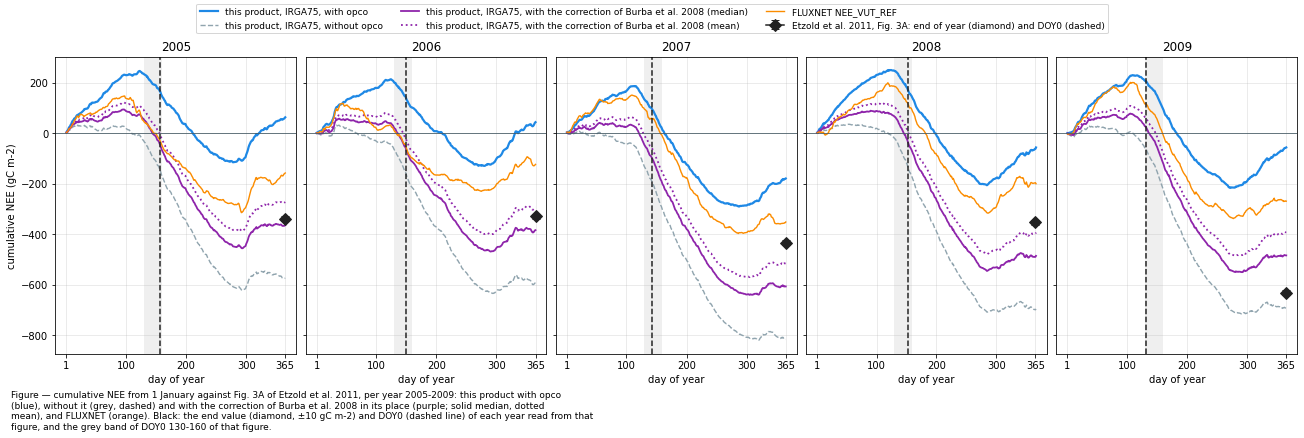

In [52]:
fig, axs = plt.subplots(1, len(_years), figsize=(18, 6), dpi=72, layout="constrained", sharey=True)
for _ax, _y in zip(axs, _years):
    for _lab, _ls, _lw in (('ours', '-', 2.2), ('ours without opco', '--', 1.4), ('ours with Burba', '-', 1.8),
                           ('ours with Burba (mean)', ':', 1.8), ('FLUXNET', '-', 1.4)):
        _c = ez_cum[_lab][ez_cum[_lab].index.year == _y]
        _ax.plot(_c.index.dayofyear, _c.to_numpy(), color=ez_colors[_lab], ls=_ls, lw=_lw, label=LINES[_lab])
    _ax.axvspan(*ez_fig3_doy0_band, color=COLORS['study2011'], alpha=0.07, lw=0)
    _ax.axvline(ez_fig3_doy0[_y], color=COLORS['study2011'], lw=1.5, ls='--')
    _ax.errorbar([365], [ez_fig3_end[_y]], yerr=ez_fig3_end_acc, color=COLORS['study2011'], marker='D', ms=8,
                 capsize=4, zorder=5, label="Etzold et al. 2011, Fig. 3A: end of year (diamond) and DOY0 (dashed)")
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.set_title(str(_y))
    _ax.set_xlabel("day of year")
    _ax.set_xticks([1, 100, 200, 300, 365])
    _ax.grid(alpha=0.3)
axs[0].set_ylabel(f"cumulative NEE ({units_sum})")
fig.legend(*axs[0].get_legend_handles_labels(), loc='outside upper center', ncol=3, fontsize=9)
figcap(fig, f"cumulative NEE from 1 January against Fig. 3A of Etzold et al. 2011, per year "
            f"{ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}: this product with opco (blue), without it (grey, dashed) and with the correction of Burba et al. 2008 in its "
            f"place (purple; solid median, dotted mean), and FLUXNET (orange). Black: the end value "
            f"(diamond, ±{ez_fig3_end_acc} {units_sum}) and DOY0 (dashed line) of each year read from that "
            f"figure, and the grey band of DOY0 {ez_fig3_doy0_band[0]}-"
            f"{ez_fig3_doy0_band[1]} of that figure.")
fig.show()

The curves with the correction of Burba et al. (2008) have the shape of Fig. 3A of Etzold et al.
(2011): a gain until spring, a zero crossing within or near the grey band, a steep decline in
summer and a rise in late autumn. The curves of this product as published have a similar summer
slope but start from a larger spring maximum and gain more again in autumn, because opco adds more
than the other correction in every month. FLUXNET lies between the two in most years. The largest
difference to Fig. 3 at the end of a year is that of 2009.

### 📋 Table: monthly NEE and air temperature against Fig. 5

In [53]:
# Air temperature of this product at 47 m, from the input of the chain.
_ta = pd.read_parquet(_files['this product, IRGA75 input (01)'], columns=[ez_ta])[ez_ta]
_ta.index = pd.DatetimeIndex(_ta.index).as_unit('ns')
_ta = _ta.loc[str(ETZOLD_YEARS[0]):str(ETZOLD_YEARS[1])]
ez_fig5_nee = pd.Series({m: v[0] for m, v in ez_fig5.items()}, dtype=float)
ez_month = pd.DataFrame({
    'Etzold et al. 2011, Fig. 5 (read with calibration)': ez_fig5_nee,
    'Etzold et al. 2011, Fig. 5 (read by eye, Settings)': pd.Series(ETZOLD_FIG5, dtype=float),
    **{k: monthly[k] for k in ez_versions},
    'ours with Burba minus Etzold et al.': monthly['ours with Burba'] - ez_fig5_nee,
    'TA, Etzold et al. 2011, Fig. 5 (°C)': pd.Series({m: v[1] for m, v in ez_fig5.items()}),
    'TA, this product (°C)': _ta.groupby(_ta.index.month).mean(),
}).sort_index()
ez_month['TA difference (°C)'] = ez_month['TA, this product (°C)'] - ez_month['TA, Etzold et al. 2011, Fig. 5 (°C)']
_show = ez_month.copy()
_show.index = [calendar.month_abbr[m] for m in _show.index]
_show.loc['year'] = ez_month.sum()
_show.loc['year', [c for c in _show.columns if '°C' in c]] = ez_month[[c for c in _show.columns if '°C' in c]].mean()
_show.index.name = 'MONTH'
_vals = [c for c in _show.columns if '°C' not in c]
_fmt = {c: "{:.0f}" for c in _vals}
_fmt.update({c: "{:.1f}" for c in _show.columns if '°C' in c})
display(styled(_show, caption=f"Fig. 5A of Etzold et al. 2011 against this product: mean monthly NEE in "
                              f"{units_sum} and mean monthly air temperature, {ETZOLD_YEARS[0]}-"
                              f"{ETZOLD_YEARS[1]}. The 2011 study read with calibration (±{ez_fig5_acc[0]} {units_sum}, ±{ez_fig5_acc[1]} °C) and by eye "
                              f"(Settings, ±{ETZOLD_FIG5_ACCURACY}); the versions of this product and FLUXNET; "
                              f"and the air temperature of this product ({ez_ta}). 'year': the sum of the "
                              f"months for NEE, the mean for air temperature",
               fmt=_fmt, subset=_vals))

Table — Fig. 5A of Etzold et al. 2011 against this product: mean monthly NEE in gC m-2 and mean
monthly air temperature, 2005-2009. The 2011 study read with calibration (±3 gC m-2, ±0.2 °C) and by
eye (Settings, ±3); the versions of this product and FLUXNET; and the air temperature of this
product (TA_T1_47_1_gfXG). 'year': the sum of the months for NEE, the mean for air temperature



,"Etzold et al. 2011, Fig. 5 (read with calibration)","Etzold et al. 2011, Fig. 5 (read by eye, Settings)",ours,ours without opco,ours with Burba,ours with Burba (mean),FLUXNET,ours with Burba minus Etzold et al.,"TA, Etzold et al. 2011, Fig. 5 (°C)","TA, this product (°C)",TA difference (°C)
MONTH,,,,,,,,,,,
Jan,39,39,83,18,40,51,65,1,-1.4,-1.3,0.1
Feb,33,33,62,-4,15,23,49,-18,-0.6,-0.4,0.2
Mar,17,17,44,-17,6,12,10,-11,2.3,2.3,0.0
Apr,-5,-5,30,-27,-10,-2,-2,-5,8.5,8.5,-0.0
May,-111,-111,-83,-135,-118,-112,-97,-7,12.4,12.5,0.1
Jun,-157,-157,-111,-161,-145,-139,-112,12,15.5,15.4,-0.1
Jul,-138,-138,-93,-138,-122,-116,-103,16,17.1,17.2,0.1
Aug,-106,-106,-78,-123,-109,-103,-71,-3,15.3,15.2,-0.1
Sep,-62,-62,-44,-88,-74,-68,-39,-12,13.0,13.0,-0.0


The air temperature of this product reproduces the temperature axis of Fig. 5 to within a few
tenths of a degree in every month, which confirms both the reading of the figure and the assignment
of the three unnumbered winter months. In winter the five months are not equal: March is the
smallest source and November the largest. With the correction of Burba et al. (2008)
in place of opco, this product follows Fig. 5 within about 20 gC m-2 in most months in the run
shown; the largest differences are in November and January, where this product is the larger
source.

### 📋 Table: seasonal NEE by day and night, 2005-2009

In [54]:
# Mean monthly sums by day and by night (FLUXNET NIGHT), for each version and FLUXNET.
ez_dn = {}
for _tod, _sel in (('day', ~_e9['night']), ('night', _e9['night']), ('all', _e9['night'] | ~_e9['night'])):
    _m = pd.DataFrame({lab: mean_monthly_sums(_e9.loc[_sel, col]) for lab, col in ez_versions.items()})
    _r = r72['night'] if _tod == 'night' else (~r72['night'] if _tod == 'day' else r72['night'] | ~r72['night'])
    _m[f'IRGA72 {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}'] = mean_monthly_sums(r72.loc[_r, varname])
    if _tod == 'all':
        _m.insert(0, 'Etzold et al. 2011 (Fig. 5)', ez_fig5_nee)
    ez_dn[_tod] = _m
ez_season_dn = pd.concat({tod: season_sums(m) for tod, m in ez_dn.items()}, axis=1)
ez_season_dn = ez_season_dn.swaplevel(axis=1)[[(s, t) for s in [*SEASONS, 'year'] for t in ('day', 'night', 'all')]]
_show = ez_season_dn.copy()
_show.columns = [f"{s}, {t}" for s, t in _show.columns]
display(styled(_show, caption=f"Etzold et al. 2011 give no split into day and night, so their row holds the "
                              f"calibrated reading of their Fig. 5 only. Mean NEE per season by day and by "
                              f"night in {units_sum}, sums of the monthly means, {ETZOLD_YEARS[0]}-"
                              f"{ETZOLD_YEARS[1]} (LI-7200: {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}, by its own "
                              f"NIGHTTIME flag). Day and night by the FLUXNET flag NIGHT"))
_d = ez_season_dn.loc['ours with Burba'] - ez_season_dn.loc['ours']
print("ours with Burba minus ours, gC m-2:", ", ".join(f"{s} {t} {v:+.0f}" for (s, t), v in _d.items()
                                                      if s == 'year'))

Table — Etzold et al. 2011 give no split into day and night, so their row holds the calibrated
reading of their Fig. 5 only. Mean NEE per season by day and by night in gC m-2, sums of the monthly
means, 2005-2009 (LI-7200: 2016-2025, by its own NIGHTTIME flag). Day and night by the FLUXNET flag
NIGHT



,"Nov-Mar, day","Nov-Mar, night","Nov-Mar, all","Apr+Oct, day","Apr+Oct, night","Apr+Oct, all","May-Sep, day","May-Sep, night","May-Sep, all","year, day","year, night","year, all"
ours,117,193,310,-42,103,61,-669,261,-408,-594,557,-38
ours without opco,-95,103,7,-126,88,-38,-882,238,-645,-1104,429,-675
ours with Burba,-42,152,109,-105,98,-8,-822,254,-567,-970,504,-466
ours with Burba (mean),-23,180,158,-97,104,7,-803,265,-538,-923,550,-374
FLUXNET,114,68,183,-50,69,19,-672,249,-423,-608,387,-221
IRGA72 2016-2025,89,277,366,-83,119,36,-816,296,-519,-809,692,-117
Etzold et al. 2011 (Fig. 5),-,-,156,-,-,0,-,-,-574,-,-,-418


ours with Burba minus ours, gC m-2: year day -375, year night -53, year all -428


The change from opco to the correction of Burba et al. (2008) acts mostly by day, as expected from
the corrections per half-hour above: by day opco adds several times as much. At night the two
corrections are closer, and the nighttime sums of the versions differ less than the daytime sums.
Etzold et al. (2011) give only the sum of day and night, so their day and night parts cannot be
compared directly; the next table shows how much of each night total is gap-filled.

### 📊 Plot: monthly NEE by day and night, 2005-2009

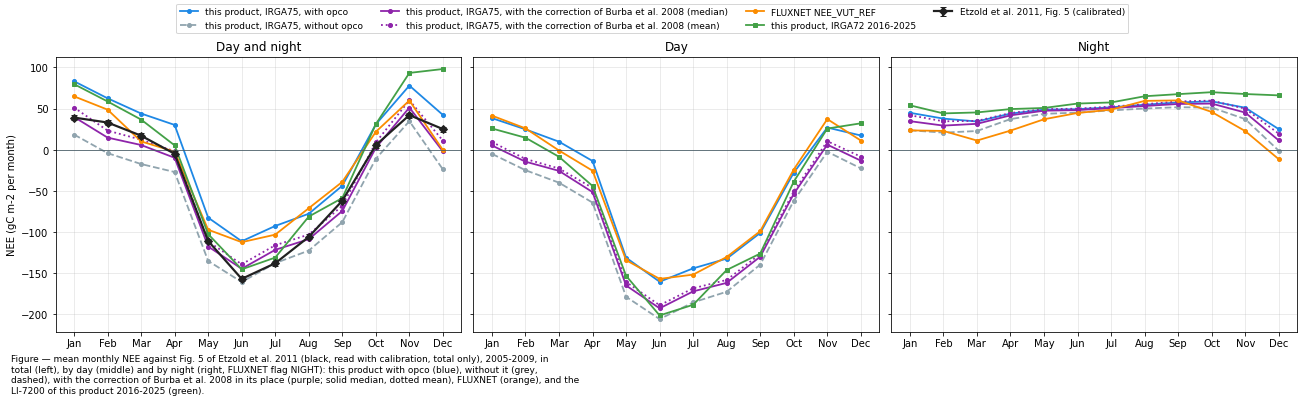

In [55]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5.5), dpi=72, layout="constrained", sharey=True)
_m = range(1, 13)
for _ax, _tod in zip(axs, ('all', 'day', 'night')):
    _f = ez_dn[_tod]
    if 'Etzold et al. 2011 (Fig. 5)' in _f:
        _ax.errorbar(_m, _f['Etzold et al. 2011 (Fig. 5)'], yerr=ez_fig5_acc[0], color=COLORS['study2011'],
                     marker='D', ms=6, lw=2.2, capsize=3, label="Etzold et al. 2011, Fig. 5 (calibrated)", zorder=5)
    for _lab, _ls in (('ours', '-'), ('ours without opco', '--'), ('ours with Burba', '-'),
                      ('ours with Burba (mean)', ':'), ('FLUXNET', '-')):
        _ax.plot(_m, _f[_lab], color=ez_colors[_lab], ls=_ls, marker='o', ms=4, lw=1.8, label=LINES[_lab])
    _ax.plot(_m, _f[f'IRGA72 {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}'], color=COLORS['IRGA72'], marker='s', ms=4,
             lw=1.8, label=f"this product, IRGA72 {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}")
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.set_title({'all': "Day and night", 'day': "Day", 'night': "Night"}[_tod])
    _ax.grid(alpha=0.3)
    month_axis(_ax)
axs[0].set_ylabel(f"NEE ({units_sum} per month)")
fig.legend(*axs[0].get_legend_handles_labels(), loc='outside upper center', ncol=4, fontsize=9)
figcap(fig, f"mean monthly NEE against Fig. 5 of Etzold et al. 2011 (black, read with calibration, total "
            f"only), {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}, in total (left), by day (middle) and by "
            f"night (right, FLUXNET flag NIGHT): this product with opco (blue), without it (grey, dashed), with "
            f"the correction of Burba et al. 2008 in its place (purple; solid median, dotted mean), FLUXNET "
            f"(orange), and the LI-7200 of this product {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]} (green).")
fig.show()

By night the four versions of this product lie close together in every month and near the LI-7200
years, while FLUXNET lies well below them from autumn to spring. By day the version with opco and
FLUXNET show the least uptake in summer; in the run shown the LI-7200 years take up about as much
by day in June and July as the versions with the smaller correction, and less in the other months.
The total of Etzold et al. (2011) follows the version with the correction of Burba et al. (2008)
in most months; whether their day and night parts do as well cannot be tested.

### 📋 Table: measured share and gap-filled night, 2005-2009

In [56]:
_y9 = _e9.index.year
_n9 = _e9['night']
ez_cover = pd.DataFrame({
    'ours, day (%)': _e9.loc[~_n9, 'ours_meas'].groupby(_y9[~_n9]).mean() * 100,
    'ours, night (%)': _e9.loc[_n9, 'ours_meas'].groupby(_y9[_n9]).mean() * 100,
    'FLUXNET, day (%)': _e9.loc[~_n9, 'flx_meas'].groupby(_y9[~_n9]).mean() * 100,
    'FLUXNET, night (%)': _e9.loc[_n9, 'flx_meas'].groupby(_y9[_n9]).mean() * 100,
    'ours, night sum': per_year(_e9.loc[_n9, 'ours']),
    'ours, night sum from filled records': per_year(_e9.loc[_n9 & ~_e9['ours_meas'], 'ours']),
    'ours, mean measured night': _e9.loc[_n9 & _e9['ours_meas'], 'ours'].groupby(_y9[_n9 & _e9['ours_meas']]).mean(),
    'ours, mean filled night': _e9.loc[_n9 & ~_e9['ours_meas'], 'ours'].groupby(_y9[_n9 & ~_e9['ours_meas']]).mean(),
})
ez_cover['ours, filled share of the night sum (%)'] = (ez_cover['ours, night sum from filled records']
                                                       / ez_cover['ours, night sum'] * 100)
ez_cover.index.name = 'YEAR'
ez_cover.loc['mean'] = ez_cover.mean()
for _tod in ('day', 'night'):
    ez_cover.insert(0 if _tod == 'day' else 3, f'Etzold et al. 2011, {_tod} (%)', np.nan)
    ez_cover.loc['mean', f'Etzold et al. 2011, {_tod} (%)'] = ez_coverage[_tod]
_fmt = {c: ("{:.1f}" if '%' in c else ("{:.2f}" if 'mean' in c else "{:.0f}")) for c in ez_cover.columns}
display(styled(ez_cover, caption=f"Etzold et al. 2011 (Table 3, mean of 2005-2009 only), this product and "
                                 f"FLUXNET: measured share of the day and the night per year (FLUXNET flag "
                                 f"NIGHT); the night sum of NEE of this product ({units_sum}) with the part that "
                                 f"comes from gap-filled records; and the mean NEE of the measured and the filled "
                                 f"nights of this product ({units})",
               fmt=_fmt, cmap=None))
print(f"Gap-filled share of the nights: Etzold et al. 2011 {100 - ez_coverage['night']} %, this product "
      f"{100 - ez_cover.loc['mean', 'ours, night (%)']:.0f} %, FLUXNET {100 - ez_cover.loc['mean', 'FLUXNET, night (%)']:.0f} %; "
      f"of the day: {100 - ez_coverage['day']} %, {100 - ez_cover.loc['mean', 'ours, day (%)']:.0f} % and "
      f"{100 - ez_cover.loc['mean', 'FLUXNET, day (%)']:.0f} %")

Table — Etzold et al. 2011 (Table 3, mean of 2005-2009 only), this product and FLUXNET: measured
share of the day and the night per year (FLUXNET flag NIGHT); the night sum of NEE of this product
(gC m-2) with the part that comes from gap-filled records; and the mean NEE of the measured and the
filled nights of this product (µmol m-2 s-1)



,"Etzold et al. 2011, day (%)","ours, day (%)","ours, night (%)","Etzold et al. 2011, night (%)","FLUXNET, day (%)","FLUXNET, night (%)","ours, night sum","ours, night sum from filled records","ours, mean measured night","ours, mean filled night","ours, filled share of the night sum (%)"
YEAR,,,,,,,,,,,
2005,-,45.8,26.5,-,42.2,23.6,537,385,3.18,2.90,71.7
2006,-,46.5,29.8,-,36.1,22.3,546,353,3.57,2.78,64.7
2007,-,50.1,32.5,-,42.0,25.4,577,362,3.67,2.96,62.7
2008,-,50.5,32.2,-,43.4,26.0,587,361,3.88,2.93,61.4
2009,-,48.2,28.5,-,42.8,24.4,535,375,3.10,2.90,70.1
mean,62.0,48.2,29.9,24.0,41.3,24.4,557,367,3.48,2.89,66.1


Gap-filled share of the nights: Etzold et al. 2011 76 %, this product 70 %, FLUXNET 76 %; of the day: 38 %, 52 % and 59 %


Etzold et al. (2011) measured about a quarter of the nights and filled the remaining three quarters
from a temperature response fitted to the measured, trimmed nights. This product keeps a similar,
small share of the nights as measured, so in both records most of the annual night sum is
gap-filled and the night total depends mainly on the level of the measured nights the gap-filling
learns from. The filled nights of this product are close to its measured nights in the mean. A
difference in the measured night level between the two studies, through the correction, the
trimming or the storage term, is therefore carried to every filled night. By day Etzold et al.
(2011) kept a larger share as measured than this product.

### 📋 Table: annual GPP, respiration and NEE against Table 4

In [57]:
_gp = pd.read_parquet(_files['this product, IRGA75 NEE (05)'], columns=list(ez_gp_cols))
_gp.index = pd.DatetimeIndex(_gp.index).as_unit('ns')
_gp = _gp.loc[str(ETZOLD_YEARS[0]):str(ETZOLD_YEARS[1])]
# The change of each correction swap, applied as in the versions above. With the nighttime method,
# a change of the nighttime flux moves RECO at all hours of that month (approximated as the same
# additive change by day), and GPP = RECO - NEE takes the rest.
_night_shift = _e9.loc[_e9['night']].groupby(_e9.loc[_e9['night']].index.month)['burba_clim'].mean() - \
    _e9.loc[_e9['night']].groupby(_e9.loc[_e9['night']].index.month)['opco_clim'].mean()
_d_reco = pd.Series(_night_shift.reindex(_e9.index.month).to_numpy(), index=_e9.index)
ez_gpp = pd.DataFrame({
    'NEE, ours': per_year(_e9['ours']),
    **{lab: per_year(_gp[col]) for col, lab in ez_gp_cols.items()},
})
ez_gpp['NEE, ours with Burba'] = per_year(_e9['ours_burba'])
ez_gpp['RECO, nighttime method, with Burba (approx.)'] = ez_gpp['RECO, nighttime method'] + per_year(_d_reco)
ez_gpp['GPP, nighttime method, with Burba (approx.)'] = (ez_gpp['RECO, nighttime method, with Burba (approx.)']
                                                         - ez_gpp['NEE, ours with Burba'])
ez_gpp.index.name = 'YEAR'
ez_gpp.loc['mean'] = ez_gpp.mean()
ez_gpp.loc['Etzold et al. 2011 (Table 4)'] = np.nan
ez_gpp.loc['Etzold et al. 2011 (Table 4)', ['NEE, ours', 'GPP, nighttime method', 'RECO, nighttime method']] = [
    ez_table4['NEE'][0] * ez_mg_to_gc, -ez_table4['GPP'][0] * ez_mg_to_gc, ez_table4['TER'][0] * ez_mg_to_gc]
ez_gpp['RECO / GPP, nighttime method'] = ez_gpp['RECO, nighttime method'] / ez_gpp['GPP, nighttime method']
_fmt = {c: "{:.0f}" for c in ez_gpp.columns}
_fmt['RECO / GPP, nighttime method'] = "{:.2f}"
display(styled(ez_gpp, caption=f"Table 4 of Etzold et al. 2011 (last row) against this product: annual NEE, GPP "
                               f"and ecosystem respiration (RECO) per year "
                               f"{ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]} in {units_sum} y-1, GPP positive, with "
                               f"the nighttime and the daytime partitioning (CUT_50). The last row holds NEE, GPP "
                               f"and TER of the 2011 study for 2005-2009 (±{ez_table4['GPP'][1] * 100:.0f} "
                               f"and ±{ez_table4['TER'][1] * 100:.0f} for GPP and TER) in the columns of the "
                               f"nighttime method, which is theirs as well. 'with Burba (approx.)': the change of "
                               f"the nighttime correction moved to RECO at every hour of the month, the rest to "
                               f"GPP; an approximation, not a repartitioning",
               fmt=_fmt, cmap=None))
_s = ez_gpp.loc['mean']
print(f"Etzold et al. 2011: TER / GPP = {ez_table4['TER'][0] / -ez_table4['GPP'][0]:.2f}; "
      f"this product, nighttime method: {_s['RECO / GPP, nighttime method']:.2f}; with Burba (approx.): "
      f"{_s['RECO, nighttime method, with Burba (approx.)'] / _s['GPP, nighttime method, with Burba (approx.)']:.2f}")
print(f"Difference to Table 4 (this product minus Etzold et al. 2011), mean of the years: "
      f"GPP {_s['GPP, nighttime method'] + ez_table4['GPP'][0] * ez_mg_to_gc:+.0f}, "
      f"RECO {_s['RECO, nighttime method'] - ez_table4['TER'][0] * ez_mg_to_gc:+.0f}, "
      f"NEE {_s['NEE, ours'] - ez_table4['NEE'][0] * ez_mg_to_gc:+.0f} {units_sum} y-1")

Table — Table 4 of Etzold et al. 2011 (last row) against this product: annual NEE, GPP and ecosystem
respiration (RECO) per year 2005-2009 in gC m-2 y-1, GPP positive, with the nighttime and the
daytime partitioning (CUT_50). The last row holds NEE, GPP and TER of the 2011 study for 2005-2009
(±448 and ±338 for GPP and TER) in the columns of the nighttime method, which is theirs as well.
'with Burba (approx.)': the change of the nighttime correction moved to RECO at every hour of the
month, the rest to GPP; an approximation, not a repartitioning



,"NEE, ours","GPP, nighttime method","RECO, nighttime method","GPP, daytime method","RECO, daytime method","NEE, ours with Burba","RECO, nighttime method, with Burba (approx.)","GPP, nighttime method, with Burba (approx.)","RECO / GPP, nighttime method"
YEAR,,,,,,,,,
2005,62,1094,1157,1786,1634,-365,1060,1425,1.06
2006,43,1364,1407,1116,1441,-385,1310,1695,1.03
2007,-180,1633,1453,1447,1507,-608,1356,1963,0.89
2008,-57,1559,1501,1346,1489,-486,1404,1890,0.96
2009,-57,1318,1261,1308,1556,-485,1164,1649,0.96
mean,-38,1394,1356,1401,1525,-466,1259,1724,0.97
Etzold et al. 2011 (Table 4),-415,1830,1383,-,-,-,-,-,0.76


Etzold et al. 2011: TER / GPP = 0.76; this product, nighttime method: 0.97; with Burba (approx.): 0.73
Difference to Table 4 (this product minus Etzold et al. 2011), mean of the years: GPP -436, RECO -27, NEE +377 gC m-2 y-1


Ecosystem respiration of this product lies close to the `TER` of Etzold et al. (2011), well within
their stated uncertainty. `GPP` is several hundred gC m-2 lower, and most of the difference in
`NEE` comes from `GPP`. Replacing opco by the correction of Burba et al. (2008) changes mainly the
daytime flux and therefore mainly `GPP`, which moves toward Table 4, and the ratio of respiration
to `GPP` comes close to theirs.

### 📋 Table: net ecosystem production against −NEE, 2006-2009

In [58]:
_y69 = (2006, ETZOLD_YEARS[1])
_e69 = _e9.loc[str(_y69[0]):str(_y69[1])]
_rows = {f"Etzold et al. 2011, {k} (biometric)": [v[0] * ez_mg_to_gc, v[1] * ez_mg_to_gc, v[2] * ez_mg_to_gc]
         for k in ez_nep for v in [ez_table5_flux[k]]}
_v = ez_table5_flux['NEE']
_rows["Etzold et al. 2011, −NEE (eddy covariance, Table 5)"] = [-_v[0] * ez_mg_to_gc, -_v[2] * ez_mg_to_gc,
                                                               -_v[1] * ez_mg_to_gc]
_rows["Etzold et al. 2011, −NEE (Fig. 3)"] = [-pd.Series(ez_fig3_end).loc[_y69[0]:].mean(), np.nan, np.nan]
for _lab, _col in ez_versions.items():
    _a = -per_year(_e69[_col])
    _rows[f"{_lab}, −NEE"] = [_a.mean(), _a.min(), _a.max()]
ez_nep_table = pd.DataFrame(_rows, index=['mean', 'lower', 'upper']).T
_lowest = ez_table5_flux['NEP*'][0] * ez_mg_to_gc
_mid = np.mean([ez_table5_flux[k][0] for k in ('ΔC', 'NEP_BM')]) * ez_mg_to_gc
ez_nep_table['minus NEP* (lowest)'] = ez_nep_table['mean'] - _lowest
ez_nep_table['minus mean of ΔC and NEP_BM'] = ez_nep_table['mean'] - _mid
# RECO against soil respiration, 2006-2009.
_reco = per_year(_gp.loc[str(_y69[0]):, 'RECO_NT_OF_CUT_50']).mean()
_reco_dt = per_year(_gp.loc[str(_y69[0]):, 'RECO_DT_OF_CUT_50']).mean()
display(styled(ez_nep_table, caption=f"Table 5 of Etzold et al. 2011 against this product: net ecosystem production "
                                     f"{_y69[0]}-{_y69[1]} in {units_sum} y-1, positive for a sink. The four "
                                     f"biometric estimates of the 2011 study (with their uncertainty range), their eddy-covariance −NEE, and "
                                     f"−NEE of this product and FLUXNET (mean, and the least and most uptake of "
                                     f"the four years). The last two columns: the mean minus the lowest biometric "
                                     f"estimate and minus the mean of the two mass-balance estimates ΔC and NEP_BM",
               fmt="{:.0f}", subset=['minus NEP* (lowest)', 'minus mean of ΔC and NEP_BM']))
_sr = ez_table4['SR (soil respiration, chambers)'][0] * ez_mg_to_gc
print(f"Soil respiration (chambers, {ez_table4['SR (soil respiration, chambers)'][2]}): {_sr:.0f} {units_sum} y-1.")
print(f"  SR / TER, Etzold et al. 2011: {_sr / (ez_table4['TER'][0] * ez_mg_to_gc):.2f} (TER 2005-2009)")
print(f"  SR / RECO, this product {_y69[0]}-{_y69[1]}: nighttime method {_sr / _reco:.2f} (RECO {_reco:.0f}), "
      f"daytime method {_sr / _reco_dt:.2f} (RECO {_reco_dt:.0f})")
print(f"  Rh (chambers) / SR: {ez_table4['Rh (heterotrophic soil respiration, chambers)'][0] / ez_table4['SR (soil respiration, chambers)'][0]:.2f}; "
      f"modelled Rh {ez_table5_flux['Rh (modelled)'][0] * ez_mg_to_gc:.0f} {units_sum} y-1")

Table — Table 5 of Etzold et al. 2011 against this product: net ecosystem production 2006-2009 in gC
m-2 y-1, positive for a sink. The four biometric estimates of the 2011 study (with their uncertainty
range), their eddy-covariance −NEE, and −NEE of this product and FLUXNET (mean, and the least and
most uptake of the four years). The last two columns: the mean minus the lowest biometric estimate
and minus the mean of the two mass-balance estimates ΔC and NEP_BM



,mean,lower,upper,minus NEP* (lowest),minus mean of ΔC and NEP_BM
"Etzold et al. 2011, NEP* (biometric)",307,296,319,0,-124
"Etzold et al. 2011, ΔC (biometric)",429,414,444,122,-2
"Etzold et al. 2011, NEP_BM (biometric)",434,418,450,127,3
"Etzold et al. 2011, NEP_BEF (biometric)",514,503,525,207,83
"Etzold et al. 2011, −NEE (eddy covariance, Table 5)",435,379,491,128,4
"Etzold et al. 2011, −NEE (Fig. 3)",438,-,-,131,7
"ours, −NEE",63,-43,180,-244,-369
"ours without opco, −NEE",701,594,817,394,269
"ours with Burba, −NEE",491,385,608,184,59
"ours with Burba (mean), −NEE",399,293,516,92,-33


Soil respiration (chambers, 2006-2009): 890 gC m-2 y-1.
  SR / TER, Etzold et al. 2011: 0.64 (TER 2005-2009)
  SR / RECO, this product 2006-2009: nighttime method 0.63 (RECO 1406), daytime method 0.59 (RECO 1498)
  Rh (chambers) / SR: 0.57; modelled Rh 455 gC m-2 y-1


All four biometric estimates indicate a sink of several hundred gC m-2 per year, and the
eddy-covariance `NEE` of Etzold et al. (2011) lies within them. This product as published lies far
below even the lowest estimate (NEP\*). In the run shown, the version with the correction of
Burba et al. (2008) lies between the lowest estimate and the two mass-balance estimates (ΔC and
NEP_BM), and the version with the monthly mean of that correction near the lowest. The
respiration of this product exceeds the chamber soil respiration by a margin similar to that in
Etzold et al. (2011), so the independent constraint does not point to a respiration that is too
high; it points to too little daytime uptake.

### 📋 Table: why the numbers diverge

In [59]:
# Supporting numbers for each cause, 2005-2009, in gC m-2 y-1: the change of the annual NEE of
# this product if the step were done as in Etzold et al. 2011 (negative = more uptake).
_ny = len(_years)
_sum = lambda s: s.sum() * UMOL_TO_GC / _ny  # mean annual sum of a half-hourly series
_corr = {'median': _sum(_e9['burba_clim'] - _e9['opco_clim']),
         'mean': _sum(_e9['burba_clim_mean'] - _e9['opco_clim'])}
_corr_day = _sum((_e9['burba_clim'] - _e9['opco_clim'])[~_e9['night']])
_corr_night = _sum((_e9['burba_clim'] - _e9['opco_clim'])[_e9['night']])

# An approximation of the half-hourly flux as Etzold et al. 2011 processed it: the uncorrected flux
# plus the correction of Burba et al. 2008 and the storage term, with their screening (USTAR, AGC,
# out-of-range limits). It is not their record; it serves to size the steps that act on it.
_agc = pd.read_parquet(_files['this product, IRGA75 input (01)'], columns=[ez_agc])[ez_agc]
_agc.index = pd.DatetimeIndex(_agc.index).as_unit('ns')
_e9['agc'] = _agc.reindex(_e9.index)
_e9['ez_flux'] = _e9['FC'] + _e9['burba'] + _e9['SC_SINGLE']
_ok = (_e9['ez_flux'].abs() <= ez_abs_limit) & (_e9['USTAR'] >= ez_ustar) & (_e9['agc'] <= ez_agc_limit)

# (b) Large dormant-season fluxes: kept in the data by Etzold et al. 2011. Their effect on the sum is
# the difference between the kept value and the value this product has on the same records.
_dorm = _e9.index.month.isin(SEASONS['Nov-Mar'])
_large = _ok & _dorm & (_e9['ez_flux'].abs() > ez_winter_flux) & ~_e9['ours_meas']
_large_eff = _sum((_e9['ez_flux'] - _e9['ours_burba'])[_large])
_large_n = int(_large.sum()) / _ny

# (c) Trimming: negative nighttime values and as many of the largest positive ones removed, per
# calendar month of each year; the shift of the mean of the measured nights is carried to every
# night by the gap-filling.
_nights = _e9.loc[_ok & _e9['night'], 'ez_flux']
_kept_ours = _e9.loc[_e9['night'] & _e9['ours_meas'], 'ours_burba']  # this product, same correction
_ours_level = _kept_ours.groupby([_kept_ours.index.year, _kept_ours.index.month]).mean()
_all_nights = _e9.loc[_e9['night']]
_n_night = _all_nights.groupby([_all_nights.index.year, _all_nights.index.month]).size()
_trim_rows = []
for (_yy, _mm), _x in _nights.groupby([_nights.index.year, _nights.index.month]):
    _x = np.sort(_x.to_numpy())
    _k = int((_x < 0).sum())
    _kept = _x[_k:len(_x) - _k] if len(_x) > 2 * _k else _x[_x >= 0]
    _trim_rows.append((_yy, _mm, _x.mean(), _kept.mean(), _ours_level.get((_yy, _mm), np.nan),
                       _k / len(_x) * 100, _n_night.get((_yy, _mm), 0)))
_trim = pd.DataFrame(_trim_rows, columns=['YEAR', 'MONTH', 'all', 'trimmed', 'ours kept', 'negative (%)',
                                          'records'])
_trim_vs_all = (_trim['trimmed'] - _trim['all']).mul(_trim['records']).sum() * UMOL_TO_GC / _ny
_trim_vs_ours = (_trim['trimmed'] - _trim['ours kept']).mul(_trim['records']).sum() * UMOL_TO_GC / _ny

# (d) Gap-filling: the same measured records of this product, filled with MDS instead of XGBoost.
_gf = per_year(_e9['ours_mds']) - per_year(_e9['ours'])
_meas_night = _e9.loc[_e9['night'], 'ours_meas'].mean() * 100

# (e) Storage: the median storage flux per calendar month, by day and by night, on every record.
_sc = month_night_climatology(_e9, 'SC_SINGLE', 'median')
_sc_day, _sc_night = -_sum(_sc[~_e9['night']]), -_sum(_sc[_e9['night']])

# (f) USTAR: the nights between the two thresholds.
_ust = (_e9['night'] & _e9['USTAR'].between(ez_ustar, USTAR_CUT_50, inclusive='left')).mean() * 100

# (f) Window screening: records this product keeps as measured that Etzold et al. 2011 would remove.
_agc_rm = (_e9['ours_meas'] & (_e9['agc'] > ez_agc_limit)).sum() / _e9['ours_meas'].sum() * 100

# (g) The remainder: Etzold et al. 2011 minus this product with their correction, minus (b) and (c).
_ez_mean = pd.Series(ez_fig3_end).mean()
_ours_mean = ez_years.loc[_years, 'ours'].mean()
_total = _ez_mean - _ours_mean
_rest = {k: _ez_mean - (_ours_mean + v) for k, v in _corr.items()}
_explained = _large_eff + _trim_vs_all + (_sc_day + _sc_night)

ez_causes = pd.DataFrame([
    ("(a) self-heating correction", "Burba et al. 2008, fraction 0.085 (Järvi et al. 2009)",
     "opco, fitted to the LI-7200 in 2016-2017", "negative",
     f"{_corr['median']:+.0f} (median), {_corr['mean']:+.0f} (mean)",
     f"all year; day {_corr_day:+.0f}, night {_corr_night:+.0f}",
     "tables of the corrections per month above; recomputed from the input of the chain"),
    ("(b) large dormant-season fluxes (±15 µmol m-2 s-1)", "kept in the data, left out of the fits",
     "removed as outliers and filled", "either",
     f"{_large_eff:+.0f}", f"Nov-Mar; {_large_n:.0f} records per year",
     "kept value minus the value of this product on records it does not keep, approximated flux"),
    ("(c) trimming of the nights", "negative nights and as many of the largest positive ones removed",
     "only nights clearly below zero removed", "negative",
     f"{_trim_vs_all:+.0f} (trimming alone); {_trim_vs_ours:+.0f} (their screened and trimmed nights "
     f"against the measured nights of this product, same correction)",
     f"night, all year; {_trim['negative (%)'].mean():.0f} % of the screened nights negative",
     "the shift of the monthly mean of the screened nights, carried to every night; the second value "
     "also holds the noise that the screening of the approximation leaves in, and is an upper bound"),
    ("(d) gap-filling", "light response, Lloyd-Taylor, running mean below 0 °C; 24 % of the nights measured",
     f"XGBoost; {_meas_night:.0f} % of the nights measured", "unknown",
     f"MDS minus XGBoost on the same data: {_gf.min():+.0f} to {_gf.max():+.0f}",
     "mostly night and winter", "the filled share dominates both night totals; table of the measured share"),
    ("(e) storage term", "not stated in the methods", "single-point profile, SC_SINGLE",
     "either", f"{_sc_day + _sc_night:+.0f} if omitted (day {_sc_day:+.0f}, night {_sc_night:+.0f})",
     "night positive, morning negative", "median storage per month by day and night, on every record"),
    ("(f) USTAR threshold and window screening",
     f"USTAR {ez_ustar} m s-1, constant; AGC above {ez_agc_limit} % removed",
     f"USTAR {USTAR_CUT_50} m s-1 (CUT_50), constant; AGC outside 40-90 % removed (Level 2)",
     "USTAR negligible; AGC unknown", "USTAR about 0; AGC not sized",
     f"night: {_ust:.2f} % of the records between the two thresholds; {_agc_rm:.1f} % of the measured "
     f"records of this product above AGC {ez_agc_limit}",
     "records this product keeps that the stricter AGC limit would remove would be gap-filled instead"),
    ("(g) remainder", "", "", "-",
     f"{_rest['median']:+.0f} (median), {_rest['mean']:+.0f} (mean) after (a); "
     f"{_rest['median'] - _explained:+.0f} after (a), (b), (c) and (e)",
     "", f"Etzold et al. 2011 (Fig. 3, mean {_ez_mean:.0f}) minus this product with their correction"),
], columns=['cause', 'Etzold et al. 2011', 'this product', 'sign of the effect on NEE',
            f'size ({units_sum} y-1)', 'season, time of day', 'evidence']).set_index('cause')
display(styled(ez_causes, caption=f"the causes of the difference between the annual NEE of Etzold et al. 2011 "
                                  f"and this product, {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}: the change of the "
                                  f"annual NEE of this product, mean of the five years, if the step were done as "
                                  f"in that study (negative: more uptake). The total difference is "
                                  f"{_total:+.0f} {units_sum} y-1 (Fig. 3, mean {_ez_mean:.0f}, against "
                                  f"{_ours_mean:.0f}). (b), (c) and (e) are sized on an approximation of their "
                                  f"flux (uncorrected flux plus the correction of Burba et al. 2008 and the "
                                  f"storage term, with their screening), not on their record", cmap=None))
print("Supporting numbers:")
print(f"  total difference, Etzold et al. 2011 minus this product: {_total:+.0f} {units_sum} y-1")
print(f"  (a) share of the total explained by the correction: {_corr['median'] / _total * 100:.0f} % (median), "
      f"{_corr['mean'] / _total * 100:.0f} % (mean)")
print(f"  (c) screened nights: {len(_nights) / _ny:.0f} records per year; mean of the monthly means "
      f"{_trim['all'].mean():.2f} before and {_trim['trimmed'].mean():.2f} after trimming, measured nights "
      f"of this product with the same correction {_trim['ours kept'].mean():.2f} {units}")
print(f"  (d) MDS minus XGBoost per year: " + ", ".join(f"{y} {v:+.0f}" for y, v in _gf.items()))
print(f"  (g) per year, Fig. 3 minus this product with their correction (median): " +
      ", ".join(f"{y} {v:+.0f}" for y, v in (ez_years.loc[_years, 'Etzold et al. 2011 (Fig. 3)']
                                             - ez_years.loc[_years, 'ours with Burba']).items()))

Table — the causes of the difference between the annual NEE of Etzold et al. 2011 and this product,
2005-2009: the change of the annual NEE of this product, mean of the five years, if the step were
done as in that study (negative: more uptake). The total difference is -381 gC m-2 y-1 (Fig. 3, mean
-418, against -38). (b), (c) and (e) are sized on an approximation of their flux (uncorrected flux
plus the correction of Burba et al. 2008 and the storage term, with their screening), not on their
record



,Etzold et al. 2011,this product,sign of the effect on NEE,size (gC m-2 y-1),"season, time of day",evidence
cause,,,,,,
(a) self-heating correction,"Burba et al. 2008, fraction 0.085 (Järvi et al. 2009)","opco, fitted to the LI-7200 in 2016-2017",negative,"-428 (median), -336 (mean)","all year; day -375, night -53",tables of the corrections per month above; recomputed from the input of the chain
(b) large dormant-season fluxes (±15 µmol m-2 s-1),"kept in the data, left out of the fits",removed as outliers and filled,either,+18,Nov-Mar; 226 records per year,"kept value minus the value of this product on records it does not keep, approximated flux"
(c) trimming of the nights,negative nights and as many of the largest positive ones removed,only nights clearly below zero removed,negative,"-28 (trimming alone); -123 (their screened and trimmed nights against the measured nights of this product, same correction)","night, all year; 24 % of the screened nights negative","the shift of the monthly mean of the screened nights, carried to every night; the second value also holds the noise that the screening of the approximation leaves in, and is an upper bound"
(d) gap-filling,"light response, Lloyd-Taylor, running mean below 0 °C; 24 % of the nights measured",XGBoost; 30 % of the nights measured,unknown,MDS minus XGBoost on the same data: -34 to +126,mostly night and winter,the filled share dominates both night totals; table of the measured share
(e) storage term,not stated in the methods,"single-point profile, SC_SINGLE",either,"+7 if omitted (day +49, night -42)","night positive, morning negative","median storage per month by day and night, on every record"
(f) USTAR threshold and window screening,"USTAR 0.3 m s-1, constant; AGC above 60 % removed","USTAR 0.304 m s-1 (CUT_50), constant; AGC outside 40-90 % removed (Level 2)",USTAR negligible; AGC unknown,USTAR about 0; AGC not sized,night: 0.25 % of the records between the two thresholds; 2.2 % of the measured records of this product above AGC 60,records this product keeps that the stricter AGC limit would remove would be gap-filled instead
(g) remainder,,,-,"+47 (median), -45 (mean) after (a); +50 after (a), (b), (c) and (e)",,"Etzold et al. 2011 (Fig. 3, mean -418) minus this product with their correction"


Supporting numbers:
  total difference, Etzold et al. 2011 minus this product: -381 gC m-2 y-1
  (a) share of the total explained by the correction: 112 % (median), 88 % (mean)
  (c) screened nights: 3433 records per year; mean of the monthly means 2.76 before and 2.65 after trimming, measured nights of this product with the same correction 3.36 µmol m-2 s-1
  (d) MDS minus XGBoost per year: 2005 -34, 2006 +126, 2007 +62, 2008 +96, 2009 +68
  (g) per year, Fig. 3 minus this product with their correction (median): 2005 +25, 2006 +55, 2007 +173, 2008 +132, 2009 -148


**Interpretation.** The two records agree where the correction does not matter: the air
temperature, the shape of the seasonal course, the timing of DOY0 once the smaller correction is
applied, and an ecosystem respiration of the same size with a similar share of soil respiration.
The difference in the annual sum comes mostly from one step. The correction of Burba et al. (2008)
with the fraction of Järvi et al. (2009) adds far less than opco, almost entirely by day, and
accounts for most of the total difference. Each of the other steps is much smaller, and their
estimated effects partly cancel. The screened and trimmed nights of the approximation lie below the
measured nights of this product, so the night level that the gap-filling of Etzold et al. (2011)
carried to three quarters of the nights was probably lower; this points in the direction of the
remainder. The remainder varies strongly between the years and is not explained by any step sized
here; in the run shown most of it falls in 2009. Which correction is right cannot be decided from
the LI-7500 alone. The LI-7200 years support opco in winter, while the independent biometric
estimates of the same years indicate a sink well above this product as published and of the size
given by the version with the smaller correction.

</br>

# End of notebook

In [60]:
dt_string = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print(f"Finished. {dt_string}")

Finished. 2026-10-30 19:29:39
